# OptiEnergy AI — Complete Project Notebook
### A Comparative Study of Optimization Algorithms for Smart Energy Consumption Prediction

**One `.ipynb` file contains the project code, real UCI hourly data cache, experiments, figures, mathematical notes, tests, and report generation. No repository upload or archive is needed.**

**How to use:** Open this notebook in **Google Colab**, **JupyterLab**, or **VS Code**. Select a Python kernel and run the cells from top to bottom. In Colab choose **Runtime → Run all**. The first cell installs only missing or incompatible dependencies. All ML calculations use a CPU.

The default demo uses the first **2,400 real clock hours**, baseline **10 epochs**, and seeds **7, 21, 42**. It compares all eight methods across linear/ridge/ANN models and performs representative one-variable sensitivity studies. Set `MODE = "full"` in the experiment cell for the expensive complete-history study. Full mode can take hours; it is not run by default.

**What you will get:** an actual measured optimizer leaderboard; convergence, residual, and sensitivity plots; interactive optimization landscapes and forecasts; a nine-page PDF report; a nine-minute presentation script; and 40 viva questions. The final optional cell can materialize the seven-page Streamlit app directly from source embedded in this notebook.

Pre-executed outputs, if present, were measured on the execution environment recorded in the notebook and manifest. Re-running produces your own measurements. Diverged runs are retained and are never assigned fabricated test scores.

**Dataset attribution:** Hebrail, G. & Berard, A. (2006). *Individual Household Electric Power Consumption*. [UCI dataset 235](https://doi.org/10.24432/C58K54), CC BY 4.0. The included hourly cache is an aggregation of those observations. The download code below can reconstruct it from the official source.

## 1. Architecture and forecast contract

**Minute kW → validated hourly kWh → causal lag/rolling/calendar inputs → chronological splits → train-only scaling → fixed models and optimizers → validation selection → final test → predictions and reports.**

An observation at index **t = 14:00** describes the finished interval **[13:00, 14:00)**. At origin t, the model predicts energy during **[t, t + 1 hour)**, whose target timestamp is t + 1 hour.

\[
e_t=\frac1{60}\sum_{m\in[t-1h,t)}p_m\ \mathrm{kWh},\qquad \hat y_t=f_\theta(x_t),\quad y_t=e_{t+1}.
\]

Targets require 60 valid minute readings. Short input gaps can forward-fill, but labels are never imputed. All features use data available at the origin. Training labels precede validation origins, validation labels precede test origins, and all transformations fit on training data only.

## 2. Install dependencies

This cell uses the current kernel's Python and installs a dependency only when its installed version is outside the supported range. If a managed Jupyter environment asks you to restart after an installation, restart once and run from the top.

In [1]:
import importlib.metadata as package_metadata
import importlib.util
import subprocess
import sys

try:
    from packaging.requirements import Requirement
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "packaging"], check=True)
    from packaging.requirements import Requirement

DEPENDENCIES = [
    "numpy>=2.1,<3", "pandas>=2.2,<3", "scipy>=1.14,<2", "scikit-learn>=1.6,<2",
    "torch>=2.6,<3", "streamlit>=1.44,<2", "plotly>=6,<7", "matplotlib>=3.9,<4",
    "joblib>=1.4,<2", "psutil>=6,<8", "pytest>=8,<10", "reportlab>=4.2,<5",
    "pypdf>=5,<8", "nbformat>=5.10,<6", "ipywidgets>=8,<9", "pillow>=10,<13",
]
missing = []
for specification in DEPENDENCIES:
    requirement = Requirement(specification)
    try:
        installed = package_metadata.version(requirement.name)
        if not requirement.specifier.contains(installed):
            missing.append(specification)
    except package_metadata.PackageNotFoundError:
        missing.append(specification)
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("Dependencies ready. Python:", sys.version.split()[0])

import matplotlib.pyplot as plt
import plotly.io as pio
from IPython.display import display, Markdown, Image as NotebookImage, FileLink
IN_COLAB = importlib.util.find_spec("google.colab") is not None
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

Dependencies ready. Python: 3.13.2


## 3. Configuration and workspace

Generated CSVs, models, and reports are stored in `OptiEnergy_Notebook_Work/` beside this notebook's working directory. Code is defined directly in the notebook: no `src` package or external project files are needed.

In [2]:
from pathlib import Path
NOTEBOOK_ROOT = Path.cwd() / 'OptiEnergy_Notebook_Work'
NOTEBOOK_ROOT.mkdir(parents=True, exist_ok=True)

"""Central, serializable configuration. All paths are relative to this repository."""
from dataclasses import asdict, dataclass
from pathlib import Path

ROOT = NOTEBOOK_ROOT
DATA = ROOT / "data"
RESULTS = ROOT / "results"
MODELS = ROOT / "saved_models"
OPTIMIZERS = ("Batch GD", "SGD", "Mini-batch GD", "Momentum", "Nesterov", "RMSprop", "Adam", "L-BFGS")
SEEDS = (7, 21, 42)


@dataclass(frozen=True)
class TrainConfig:
    model: str = "linear"
    optimizer: str = "Adam"
    lr: float = 0.01
    batch_size: int = 64
    epochs: int = 12
    momentum: float = 0.9
    alpha: float = 0.0
    schedule: str = "constant"
    decay: float = 0.05
    seed: int = 7
    threshold: float = 0.35
    scaling: str = "standard"

    def validate(self):
        if self.model not in {"linear", "ridge", "ann", "sklearn"}:
            raise ValueError("Unknown model")
        if self.optimizer not in OPTIMIZERS and not (self.model == "sklearn" and self.optimizer == "Direct solve"):
            raise ValueError("Unknown optimizer")
        if not 0 < self.lr <= 10 or not 0 <= self.momentum < 1:
            raise ValueError("Require 0 < learning rate <= 10 and 0 <= momentum < 1")
        if self.batch_size < 1 or self.epochs < 1 or self.alpha < 0 or self.decay < 0:
            raise ValueError("Invalid batch size, epochs, regularization, or decay")
        if self.model in {"linear", "sklearn"} and self.alpha != 0:
            raise ValueError("Use model='ridge' for a regularized linear model")
        if self.schedule not in {"constant", "decay"}:
            raise ValueError("Unknown learning-rate schedule")
        if self.scaling not in {"standard", "minmax", "robust", "none"}:
            raise ValueError("Unknown feature scaling")
        return self

    def to_dict(self):
        return asdict(self)

print('Workspace folder:', NOTEBOOK_ROOT.name)

Workspace folder: OptiEnergy_Notebook_Work


## 4. Reproducibility and result helpers

Set deterministic seeds, hash configurations, record the runtime, and write strict JSON metadata.

In [3]:
import hashlib
import json
import os
import platform
import random
from pathlib import Path

import numpy as np


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    import torch
    torch.manual_seed(seed)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)


def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()[:16]


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, default=str, allow_nan=False), encoding="utf-8")


def environment():
    from importlib.metadata import version
    names = ["numpy", "pandas", "scipy", "scikit-learn", "torch", "streamlit"]
    return {"python": platform.python_version(), "platform": platform.platform(),
            "packages": {n: version(n) for n in names},
            "cpu_count": os.cpu_count(), "torch_threads": 1}

## 5. Official UCI download and hourly aggregation

This is the complete download/cache/validation implementation. It uses the official UCI archive if the hourly cache is absent. Duplicate timestamps, invalid numbers, negative power, missing minutes, and partial hours are handled explicitly.

In [4]:
"""Download UCI 235 atomically; aggregate complete observed hours without inventing labels."""
import argparse
import hashlib
import json
import shutil
import time
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd


URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
SOURCE = "https://doi.org/10.24432/C58K54"
SCHEMA = "complete-hours-v2"


def download_dataset(directory=DATA / "raw"):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    target = directory / "household_power_consumption.txt"
    if target.exists() and target.stat().st_size > 1_000_000:
        return target
    archive = directory / "uci235.zip"
    if not archive.exists():
        partial = archive.with_suffix(".partial")
        for attempt in range(3):
            try:
                request = urllib.request.Request(URL, headers={"User-Agent": "OptiEnergy-AI/1.0 educational research"})
                with urllib.request.urlopen(request, timeout=120) as response, partial.open("wb") as out:
                    shutil.copyfileobj(response, out)
                with zipfile.ZipFile(partial) as z:
                    if z.testzip():
                        raise ValueError("UCI archive failed its CRC integrity check")
                partial.replace(archive)
                break
            except (OSError, ValueError, zipfile.BadZipFile):
                partial.unlink(missing_ok=True)
                if attempt == 2:
                    raise RuntimeError("Cannot download UCI data. Download the ZIP manually into data/raw/uci235.zip.")
                time.sleep(attempt + 1)
    with zipfile.ZipFile(archive) as z:
        # Read only the named member; never extract arbitrary archive paths.
        member = next((n for n in z.namelist() if Path(n).name == target.name), None)
        if member is None:
            raise ValueError("Dataset file is missing from archive")
        with z.open(member) as source, target.with_suffix(".partial").open("wb") as out:
            shutil.copyfileobj(source, out)
    target.with_suffix(".partial").replace(target)
    return target


def aggregate_minutes(frame):
    """An index at 14:00 represents energy observed in [13:00, 14:00)."""
    frame = frame.copy()
    timestamps = pd.to_datetime(frame["Date"].astype(str) + " " + frame["Time"].astype(str),
                                format="%d/%m/%Y %H:%M:%S", errors="coerce")
    power = pd.to_numeric(frame["Global_active_power"], errors="coerce")
    power = power.where(np.isfinite(power) & (power >= 0))
    series = pd.Series(power.to_numpy(), index=timestamps).loc[timestamps.notna().to_numpy()]
    duplicates = int(series.index.duplicated().sum())
    series = series[~series.index.duplicated(keep="first")].sort_index()
    series = series.asfreq("min")
    groups = series.resample("h", closed="left", label="right")
    counts = groups.count()
    energy = (groups.sum(min_count=60) / 60.0).where(counts == 60)
    hourly = pd.DataFrame({"energy_kwh": energy, "observed_minutes": counts})
    hourly.index.name = "origin"
    stats = {"source": SOURCE, "license": "CC BY 4.0; Hebrail & Berard",
             "raw_rows": len(frame), "duplicate_timestamps": duplicates,
             "missing_or_invalid_minutes": int(series.isna().sum()),
             "missing_minute_fraction": float(series.isna().mean()),
             "hours": len(hourly), "complete_hours": int(energy.notna().sum()),
             "incomplete_hours": int(energy.isna().sum()), "schema": SCHEMA,
             "timestamp_convention": "naive local clock; right endpoint of observed hourly interval"}
    return hourly, stats


def load_hourly(data_dir=DATA, force=False):
    data_dir = Path(data_dir)
    cache, metadata = data_dir / "processed/hourly.csv", data_dir / "processed/metadata.json"
    if cache.exists() and metadata.exists() and not force:
        stats = json.loads(metadata.read_text(encoding="utf-8"))
        if stats.get("schema") == SCHEMA:
            return pd.read_csv(cache, index_col=0, parse_dates=True), stats
    path = download_dataset(data_dir / "raw")
    frame = pd.read_csv(path, sep=";", na_values=["?", ""],
                        usecols=["Date", "Time", "Global_active_power"], low_memory=False)
    hourly, stats = aggregate_minutes(frame)
    stats["raw_sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
    cache.parent.mkdir(parents=True, exist_ok=True)
    hourly.to_csv(cache)
    write_json(metadata, stats)
    return hourly, stats

### Included real-data cache

The following cell restores the observed hourly UCI aggregation from a compressed text payload embedded in this notebook. It contains **data only**, not executable or pickled objects. This makes the notebook independent of a dataset upload and usable without downloading the 126 MB raw text. Set `USE_INCLUDED_HOURLY_CACHE = False` and `FORCE_RAW_REBUILD = True` to verify the raw download instead.

In [5]:
import base64
import hashlib
import zlib

USE_INCLUDED_HOURLY_CACHE = True
FORCE_RAW_REBUILD = False
HOURLY_DATA_B64 = '...'
HOURLY_METADATA = {'source': 'https://doi.org/10.24432/C58K54', 'license': 'CC BY 4.0; Hebrail & Berard', 'raw_rows': 2075259, 'duplicate_timestamps': 0, 'missing_or_invalid_minutes': 25979, 'missing_minute_fraction': 0.012518437457686004, 'hours': 34589, 'complete_hours': 34085, 'incomplete_hours': 504, 'schema': 'complete-hours-v2', 'timestamp_convention': 'naive local clock; right endpoint of observed hourly interval', 'raw_sha256': '4259c9d7ece5dbee9ab8d53682baac68d791c864f0f64a52b4043cb3b90894b7'}

if USE_INCLUDED_HOURLY_CACHE and not FORCE_RAW_REBUILD:
    cache_folder = DATA / 'processed'
    cache_folder.mkdir(parents=True, exist_ok=True)
    cache_file = cache_folder / 'hourly.csv'
    raw_cache = zlib.decompress(base64.b64decode(HOURLY_DATA_B64))
    assert hashlib.sha256(raw_cache).hexdigest() == 'ea346fbed119a430e49614e6a05835ec51fdc643d0f0f5508e211fcc11b1e472'
    if not cache_file.exists():
        cache_file.write_bytes(raw_cache)
        write_json(cache_folder / 'metadata.json', HOURLY_METADATA)
    print('Observed UCI hourly cache ready; no upload required.')

Observed UCI hourly cache ready; no upload required.


In [6]:
hourly, dataset_metadata = load_hourly(force=FORCE_RAW_REBUILD)
display(pd.DataFrame({
    "Quantity": ["Raw minute records", "Missing or invalid minutes", "Complete observed hours", "Incomplete hours"],
    "Measured value": [dataset_metadata["raw_rows"], dataset_metadata["missing_or_invalid_minutes"],
                       dataset_metadata["complete_hours"], dataset_metadata["incomplete_hours"]],
}))
display(hourly.head())
print("Source:", dataset_metadata["source"])
print("Raw text SHA-256:", dataset_metadata["raw_sha256"])

,Quantity,Measured value
0,Raw minute records,2075259
1,Missing or invalid minutes,25979
2,Complete observed hours,34085
3,Incomplete hours,504


,energy_kwh,observed_minutes
origin,,
2006-12-16 18:00:00,NaN,36
2006-12-16 19:00:00,3.632200,60
2006-12-16 20:00:00,3.400233,60
2006-12-16 21:00:00,3.268567,60
2006-12-16 22:00:00,3.056467,60


Source: https://doi.org/10.24432/C58K54
Raw text SHA-256: 4259c9d7ece5dbee9ab8d53682baac68d791c864f0f64a52b4043cb3b90894b7


## 6. Exploratory data analysis

These full-history summaries are descriptive. They do not choose hyperparameters or alter the experiment's held-out partitions. Hour/day labels use the interval's starting time.

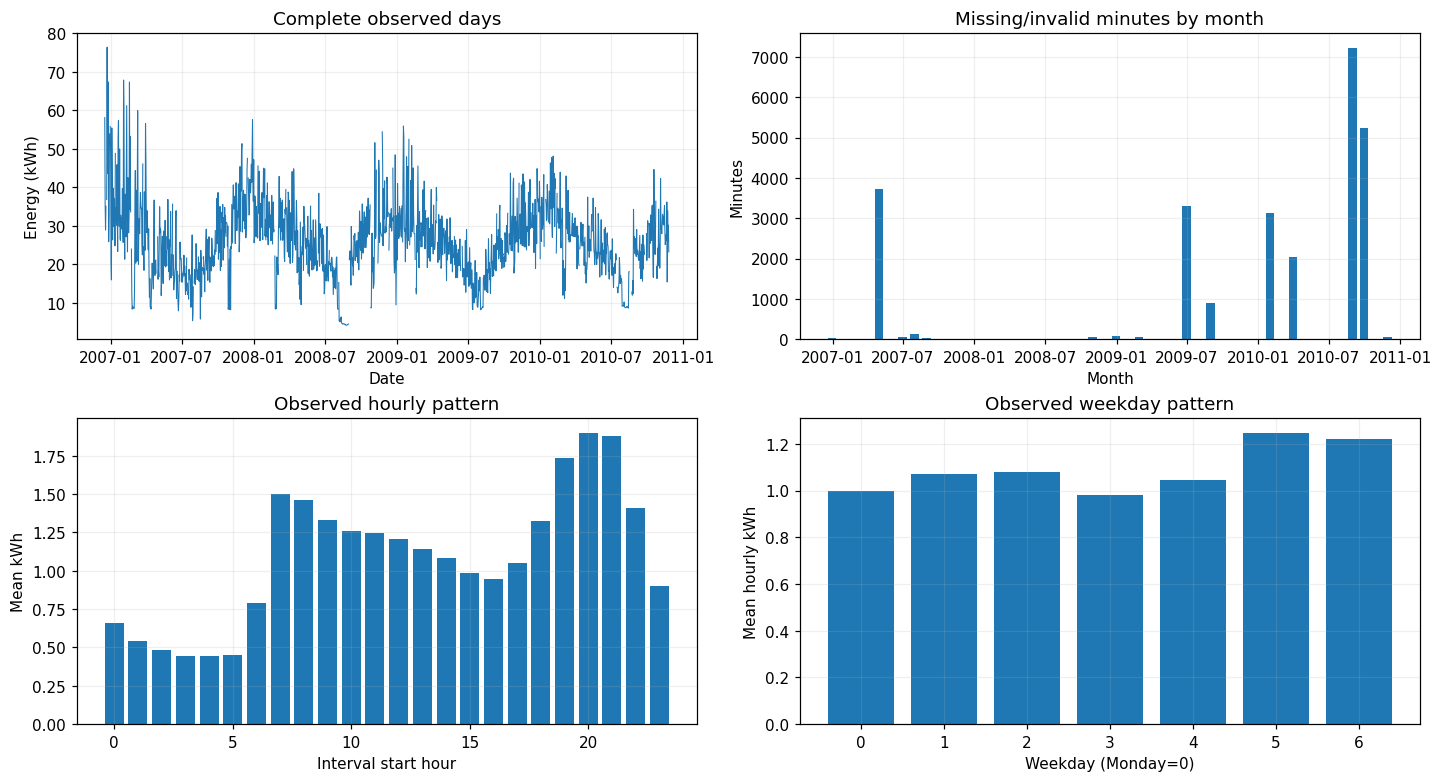

In [7]:
daily_energy = hourly.energy_kwh.resample("D").sum(min_count=24)
fig, axes = plt.subplots(2, 2, figsize=(13, 7), layout="constrained")
axes[0, 0].plot(daily_energy.index, daily_energy, linewidth=.7)
axes[0, 0].set(title="Complete observed days", ylabel="Energy (kWh)", xlabel="Date")
missing_by_month = (60 - hourly.observed_minutes).resample("ME").sum()
axes[0, 1].bar(missing_by_month.index, missing_by_month, width=22)
axes[0, 1].set(title="Missing/invalid minutes by month", ylabel="Minutes", xlabel="Month")
hourly_pattern = hourly.energy_kwh.groupby((hourly.index.hour - 1) % 24).mean()
axes[1, 0].bar(hourly_pattern.index, hourly_pattern)
axes[1, 0].set(title="Observed hourly pattern", xlabel="Interval start hour", ylabel="Mean kWh")
weekday_pattern = hourly.energy_kwh.groupby((hourly.index-pd.Timedelta(hours=1)).dayofweek).mean()
axes[1, 1].bar(weekday_pattern.index, weekday_pattern)
axes[1, 1].set(title="Observed weekday pattern", xlabel="Weekday (Monday=0)", ylabel="Mean hourly kWh")
plt.show()

## 7. Causal feature engineering

Create lags 1/3/6/12/24 hours, rolling mean/std for 3/6/12/24 hours, calendar values, and cyclical encodings. Every feature is available at its stated origin.

In [8]:
"""Every feature at origin t is measurable using hourly observations through t."""
import numpy as np
import pandas as pd

LAGS = (1, 3, 6, 12, 24)
WINDOWS = (3, 6, 12, 24)


def features_at_origins(hourly):
    if not isinstance(hourly.index, pd.DatetimeIndex) or not hourly.index.is_monotonic_increasing:
        raise ValueError("A sorted DatetimeIndex is required")
    if hourly.index.has_duplicates:
        raise ValueError("Duplicate hourly origins are not allowed")
    # Reindex before shifts: a missing clock hour must never become a one-hour lag.
    observed = hourly["energy_kwh"].asfreq("h")
    # Causal bounded forward fill is for INPUTS ONLY. Labels remain strictly observed.
    energy = observed.ffill(limit=6)
    x = pd.DataFrame({"energy_current": energy, "current_missing": observed.isna().astype(float)})
    for lag in LAGS:
        x[f"lag_{lag}"] = energy.shift(lag)
    for window in WINDOWS:
        x[f"rolling_mean_{window}"] = energy.rolling(window, min_periods=window).mean()
        x[f"rolling_std_{window}"] = energy.rolling(window, min_periods=window).std(ddof=0)
    # Calendar covariates describe the next hourly interval, whose left endpoint is t.
    idx = x.index
    x["hour"], x["day"], x["weekday"], x["month"] = idx.hour, idx.day, idx.dayofweek, idx.month
    x["weekend"] = (idx.dayofweek >= 5).astype(float)
    for name, values, period in (("hour", idx.hour, 24), ("weekday", idx.dayofweek, 7), ("month", idx.month - 1, 12)):
        x[name + "_sin"] = np.sin(2 * np.pi * values / period)
        x[name + "_cos"] = np.cos(2 * np.pi * values / period)
    return x.replace([np.inf, -np.inf], np.nan)


def supervised_frame(hourly):
    x = features_at_origins(hourly)
    x["target"] = hourly["energy_kwh"].asfreq("h").shift(-1)
    x["target_time"] = x.index + pd.Timedelta(hours=1)
    return x.dropna().copy()

## 8. Chronological splits and train-only scaling

Create 70/15/15 train/validation/test partitions, purge cross-boundary labels, and fit feature and target transforms on training rows only. The target is standardized for optimization and inverted to kWh for scoring.

In [9]:
from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler



@dataclass
class PreparedData:
    X_train: np.ndarray
    X_val: np.ndarray
    X_test: np.ndarray
    y_train: np.ndarray
    y_val: np.ndarray
    y_test: np.ndarray
    frames: dict
    feature_names: list
    scaler: object
    y_mean: float
    y_std: float
    scaling: str

    def inverse_target(self, y):
        return np.asarray(y) * self.y_std + self.y_mean

    def transform(self, frame):
        x = frame[self.feature_names].to_numpy(dtype=float)
        return self.scaler.transform(x) if self.scaler is not None else x


def prepare_data(hourly, scaling="standard", max_hours=None):
    if scaling not in {"standard", "minmax", "robust", "none"}:
        raise ValueError("Unknown scaling")
    if max_hours is not None:
        if max_hours < 240:
            raise ValueError("Use at least 240 hours")
        hourly = hourly.iloc[:max_hours]
    frame = supervised_frame(hourly)
    if len(frame) < 100:
        raise ValueError("Insufficient complete causal feature/target rows")
    n = len(frame)
    a, b = int(n * .70), int(n * .85)
    train, val, test = frame.iloc[:a].copy(), frame.iloc[a:b].copy(), frame.iloc[b:].copy()
    # A training target cannot land at the first validation origin. Same for val/test.
    train = train.loc[train.target_time < val.index.min()]
    val = val.loc[val.target_time < test.index.min()]
    names = [c for c in frame if c not in {"target", "target_time"}]
    scaler = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}.get(scaling)
    scaler = scaler().fit(train[names].to_numpy(float)) if scaler else None
    transform = lambda f: scaler.transform(f[names].to_numpy(float)) if scaler else f[names].to_numpy(float)
    mean, std = float(train.target.mean()), float(train.target.std(ddof=0))
    std = max(std, 1e-8)
    target = lambda f: (f.target.to_numpy(float) - mean) / std
    return PreparedData(transform(train), transform(val), transform(test),
                        target(train), target(val), target(test),
                        {"train": train, "validation": val, "test": test}, names,
                        scaler, mean, std, scaling)

In [10]:
DEMO_HOURS = 2400
preview_data = prepare_data(hourly, scaling="standard", max_hours=DEMO_HOURS)
display(pd.DataFrame([
    {"partition": name, "rows": len(frame), "first_origin": frame.index.min(),
     "last_origin": frame.index.max(), "last_target": frame.target_time.max()}
    for name, frame in preview_data.frames.items()
]))
display(preview_data.frames["train"].head())
print("Number of inputs:", len(preview_data.feature_names))
corr_columns = ["energy_current", "lag_1", "lag_3", "lag_6", "lag_12", "lag_24", "rolling_mean_24", "target"]
# This correlation view uses training data only.
import plotly.express as px
px.imshow(preview_data.frames["train"][corr_columns].corr(), zmin=-1, zmax=1,
          color_continuous_scale="RdBu_r", title="Training feature/target correlation").show()

,partition,rows,first_origin,last_origin,last_target
0,train,1656,2006-12-17 19:00:00,2007-02-24 23:00:00,2007-02-25 00:00:00
1,validation,354,2007-02-25 01:00:00,2007-03-11 18:00:00,2007-03-11 19:00:00
2,test,356,2007-03-11 20:00:00,2007-03-26 16:00:00,2007-03-26 17:00:00


,energy_current,current_missing,lag_1,lag_3,lag_6,lag_12,lag_24,rolling_mean_3,rolling_std_3,rolling_mean_6,...,month,weekend,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos,target,target_time
origin,,,,,,,,,,,,,,,,,,,,,
2006-12-17 19:00:00,3.697100,0.0,3.406767,2.985400,1.915867,1.303300,3.632200,3.476633,0.159340,2.861450,...,12,1.0,-0.965926,0.258819,-0.781831,0.62349,-0.5,0.866025,2.908400,2006-12-17 20:00:00
2006-12-17 20:00:00,2.908400,0.0,3.697100,3.326033,1.660767,1.620033,3.400233,3.337422,0.325698,3.069389,...,12,1.0,-0.866025,0.500000,-0.781831,0.62349,-0.5,0.866025,3.361500,2006-12-17 21:00:00
2006-12-17 21:00:00,3.361500,0.0,2.908400,3.406767,2.092633,1.890567,3.268567,3.322333,0.323174,3.280867,...,12,1.0,-0.707107,0.707107,-0.781831,0.62349,-0.5,0.866025,3.040767,2006-12-17 22:00:00
2006-12-17 22:00:00,3.040767,0.0,3.361500,3.697100,2.985400,2.549067,3.056467,3.103556,0.190231,3.290094,...,12,1.0,-0.500000,0.866025,-0.781831,0.62349,-0.5,0.866025,1.518000,2006-12-17 23:00:00
2006-12-17 23:00:00,1.518000,0.0,3.040767,2.908400,3.326033,3.628900,2.200133,2.640089,0.804168,2.988756,...,12,1.0,-0.258819,0.965926,-0.781831,0.62349,-0.5,0.866025,0.437733,2006-12-18 00:00:00


Number of inputs: 26


## 9. Mathematical formulation and models

Append the intercept column to obtain $A\in\mathbb R^{n\times(d+1)}$, and set $D=\mathrm{diag}(1,\ldots,1,0)$.

\[
J(w)=\frac1n\lVert Aw-u\rVert^2+\frac\alpha2w^TDw,\qquad
\nabla J=\frac2nA^T(Aw-u)+\alpha Dw,\qquad
H=\frac2nA^TA+\alpha D.
\]

Linear/ridge squared loss is convex because $v^THv\ge0$. Strict convexity requires a positive-definite Hessian. Constant or redundant features can make the unregularized Hessian singular; ridge adds curvature while leaving the intercept unpenalized.

With $L=\lambda_{\max}(H)$, batch GD is stable for $0<\eta<2/L$ and descends for $\eta\le1/L$. This full-data bound does not guarantee per-sample SGD stability. The fixed ANN is **26 → 32 → 16 → 1**, uses Tanh, and has a non-convex parameter-space loss.

In [11]:
"""Linear MSE and ridge objectives share one analytically differentiated implementation."""
import numpy as np
import torch
from torch import nn


class LinearModel:
    def __init__(self, n_features):
        self.weights = np.zeros(n_features + 1, dtype=np.float64)

    @staticmethod
    def design(X):
        return np.column_stack([X, np.ones(len(X))])

    def predict(self, X):
        return self.design(X) @ self.weights


class RidgeModel(LinearModel):
    """Model form is identical; the trainer adds alpha/2 times squared non-bias weights."""


def linear_objective(weights, X, y, alpha=0.0):
    error = X @ weights - y
    penalty = weights.copy()
    penalty[-1] = 0.0
    loss = np.mean(error ** 2) + alpha * .5 * np.dot(penalty, penalty)
    gradient = 2 * X.T @ error / len(y) + alpha * penalty
    return float(loss), gradient


def linear_hessian(X, alpha=0.0):
    regularizer = np.eye(X.shape[1])
    regularizer[-1, -1] = 0
    return 2 * X.T @ X / len(X) + alpha * regularizer


def gradient_check(weights, X, y, alpha=.1, epsilon=1e-6):
    analytic = linear_objective(weights, X, y, alpha)[1]
    numerical = np.empty_like(weights)
    for j in range(len(weights)):
        step = np.zeros_like(weights)
        step[j] = epsilon
        numerical[j] = (linear_objective(weights + step, X, y, alpha)[0] -
                        linear_objective(weights - step, X, y, alpha)[0]) / (2 * epsilon)
    return float(np.linalg.norm(analytic - numerical) / max(1., np.linalg.norm(analytic), np.linalg.norm(numerical)))


class SmallANN(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features, 32), nn.Tanh(),
                                 nn.Linear(32, 16), nn.Tanh(), nn.Linear(16, 1))

    def forward(self, X):
        return self.net(X).squeeze(-1)

    def predict(self, X):
        self.eval()
        with torch.no_grad():
            return self(torch.as_tensor(X, dtype=torch.float32)).numpy()


def ann_objective(model, X, y, alpha):
    penalty = sum((p ** 2).sum() for name, p in model.named_parameters() if "weight" in name)
    return torch.mean((model(X) - y) ** 2) + alpha * .5 * penalty

In [12]:
design = LinearModel.design(preview_data.X_train)
relative_error = gradient_check(np.zeros(design.shape[1]), design[:50], preview_data.y_train[:50])
hessian = linear_hessian(design)
spectrum = np.linalg.eigvalsh(hessian)
rank_tolerance = spectrum.max() * 1e-10
rank = int(np.sum(spectrum > rank_tolerance))
print(f"Gradient-check relative error: {relative_error:.3e}")
print(f"Hessian numerical rank: {rank}/{len(spectrum)}")
print(f"Largest curvature eigenvalue L: {spectrum.max():.6f}")
print(f"Stable full-batch GD upper step 2/L: {2/spectrum.max():.6f}")
print("Full condition number:", "singular at tolerance" if rank < len(spectrum) else spectrum.max()/spectrum.min())
assert relative_error < 1e-7

Gradient-check relative error: 1.149e-10
Hessian numerical rank: 26/27
Largest curvature eigenvalue L: 12.504830
Stable full-batch GD upper step 2/L: 0.159938
Full condition number: singular at tolerance


## 10. NumPy optimizers from scratch

Batch GD, SGD, and mini-batch GD share the same update equation and differ by batch selection. Momentum stores velocity; Nesterov evaluates a lookahead gradient; RMSprop uses second moments; Adam uses bias-corrected first and second moments. L-BFGS uses SciPy/PyTorch closures in the training engine below.

In [13]:
"""First-order NumPy optimizer classes. Nesterov evaluates the gradient at lookahead()."""
import numpy as np


class GradientDescent:
    def __init__(self, lr=.01, momentum=.9):
        if not np.isfinite(lr) or lr <= 0 or not 0 <= momentum < 1:
            raise ValueError("Invalid optimizer hyperparameters")
        self.lr, self.beta, self.t = lr, momentum, 0

    def lookahead(self, weights):
        return weights

    def step(self, weights, gradient):
        self.t += 1
        return weights - self.lr * gradient


class Momentum(GradientDescent):
    def step(self, weights, gradient):
        self.t += 1
        if not hasattr(self, "velocity"):
            self.velocity = np.zeros_like(weights)
        self.velocity = self.beta * self.velocity - self.lr * gradient
        return weights + self.velocity


class Nesterov(Momentum):
    def lookahead(self, weights):
        return weights + self.beta * getattr(self, "velocity", np.zeros_like(weights))


class RMSprop(GradientDescent):
    def step(self, weights, gradient):
        self.t += 1
        self.square = .99 * getattr(self, "square", np.zeros_like(weights)) + .01 * gradient ** 2
        return weights - self.lr * gradient / (np.sqrt(self.square) + 1e-8)


class Adam(GradientDescent):
    def step(self, weights, gradient):
        self.t += 1
        self.first = .9 * getattr(self, "first", np.zeros_like(weights)) + .1 * gradient
        self.second = .999 * getattr(self, "second", np.zeros_like(weights)) + .001 * gradient ** 2
        first = self.first / (1 - .9 ** self.t)
        second = self.second / (1 - .999 ** self.t)
        return weights - self.lr * first / (np.sqrt(second) + 1e-8)


def make_optimizer(name, lr=.01, momentum=.9):
    cls = {"Batch GD": GradientDescent, "SGD": GradientDescent, "Mini-batch GD": GradientDescent,
           "Momentum": Momentum, "Nesterov": Nesterov, "RMSprop": RMSprop, "Adam": Adam}.get(name)
    if cls is None:
        raise ValueError("L-BFGS uses a function/gradient closure; it is handled by SciPy/PyTorch")
    return cls(lr, momentum)

### Update equations and cost

| Method | Update principle | Linear per-update computation / extra state |
|---|---|---|
| GD / SGD / mini-batch GD | $w\leftarrow w-\eta g$ | $O(bp)$ / $O(p)$ |
| Momentum | $v\leftarrow\beta v-\eta g$; $w\leftarrow w+v$ | $O(bp)$ / $O(p)$ |
| NumPy Nesterov | Evaluate $g$ at $w+\beta v$, then update velocity/weights | $O(bp)$ / $O(p)$ |
| RMSprop | $s\leftarrow.99s+.01g^2$; $w\leftarrow w-\eta g/(\sqrt{s}+\epsilon)$ | $O(bp)$ / $O(p)$ |
| Adam | Moments .9/.999, bias correction per update, adaptive coordinate steps | $O(bp)$ / $O(p)$ |
| L-BFGS | Limited-memory curvature pairs and a line search | $O(qnp+mp)$ / $O(mp)$ |

Here $b$ is batch size, $p$ parameter count, $m=10$ history pairs, and $q$ the number of full-data evaluations for an accepted L-BFGS step. All L-BFGS closure evaluations count toward the training budget. Monitoring overhead is logged separately.

The PyTorch Nesterov implementation uses its standard momentum-buffer convention. Comparisons are within model families; identical NumPy/PyTorch trajectories are not assumed.

## 11. Mathematical benchmark functions

Exact-gradient quadratic, ill-conditioned quadratic (condition number 100), Rosenbrock, and Himmelblau objectives.

In [14]:
import numpy as np


def quadratic(p):
    x, y = p
    return .5 * (x*x + 4*y*y), np.array([x, 4*y])


def ill_conditioned(p):
    x, y = p
    return .5 * (x*x + 100*y*y), np.array([x, 100*y])


def rosenbrock(p):
    x, y = p
    return (1-x)**2 + 100*(y-x*x)**2, np.array([-2*(1-x)-400*x*(y-x*x), 200*(y-x*x)])


def himmelblau(p):
    x, y = p
    a, b = x*x+y-11, x+y*y-7
    return a*a+b*b, np.array([4*x*a+2*b, 2*a+4*y*b])


BENCHMARKS = {"Quadratic": (quadratic, (-4., 4.), (3., 3.), .1),
              "Ill-conditioned quadratic": (ill_conditioned, (-4., 4.), (3., 3.), .01),
              "Rosenbrock": (rosenbrock, (-2., 2.), (-1.2, 1.), .001),
              "Himmelblau": (himmelblau, (-5., 5.), (-3., -3.), .01)}

## 12. Metrics in physical units

MSE is measured in kWh²; RMSE and MAE in kWh. R² can be negative. Repeated-run summaries use sample standard deviation, not a confidence interval.

In [15]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def regression_metrics(actual, predicted):
    if not np.isfinite(predicted).all():
        raise ValueError("Non-finite prediction")
    mse = mean_squared_error(actual, predicted)
    return {"mse": float(mse), "rmse": float(np.sqrt(mse)),
            "mae": float(mean_absolute_error(actual, predicted)), "r2": float(r2_score(actual, predicted))}

## 13. Instrumented linear, ridge, and ANN training

The complete engine below fixes initialization and seeded permutations within each family. It logs objective/validation loss, gradient norm, updates, example-processing passes, function/gradient calls, time, process RSS, and threshold crossing. It restores validation-best checkpoints and never reads test labels.

In [16]:
"""Instrumented CPU training. Validation checkpoints, no test access in this module."""
import copy
import time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import psutil
import torch
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression



class BudgetExhausted(Exception):
    """Expected termination when a quasi-Newton evaluation budget has been spent."""


@dataclass
class TrainingResult:
    model: object
    history: pd.DataFrame
    summary: dict
    config: dict


def train(data, config, progress=None):
    config.validate()
    seed_everything(config.seed)
    rng = np.random.default_rng(config.seed)
    n, d = data.X_train.shape
    X, y, V, v = data.X_train, data.y_train, data.X_val, data.y_val
    ann = config.model == "ann"
    if ann:
        X, y, V, v = [torch.as_tensor(z, dtype=torch.float32) for z in (X, y, V, v)]
        model = SmallANN(d)
    elif config.model == "sklearn":
        model = LinearRegression()
    else:
        model = (RidgeModel if config.model == "ridge" else LinearModel)(d)
        X, V = model.design(X), model.design(V)
    start = time.perf_counter()
    counters = {"updates": 0, "gradient_evaluations": 0, "function_evaluations": 0,
                "processed_examples": 0, "monitor_gradient_evaluations": 0,
                "monitor_function_evaluations": 0}
    rows, best, best_val, best_epoch = [], None, float("inf"), 0
    status, message, threshold_seconds = "budget_completed", "", None
    process = psutil.Process()
    peak_rss = process.memory_info().rss / 2 ** 20

    def state():
        if ann:
            return copy.deepcopy(model.state_dict())
        return copy.deepcopy(model) if config.model == "sklearn" else model.weights.copy()

    def record(epoch):
        nonlocal best, best_val, best_epoch, threshold_seconds, peak_rss
        if ann:
            model.zero_grad()
            objective = ann_objective(model, X, y, config.alpha)
            objective.backward()
            loss = float(objective.detach())
            grad = float(torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters())))
            with torch.no_grad():
                pred, vp = model(X).numpy(), model(V).numpy()
        elif config.model == "sklearn":
            pred, vp = model.predict(X), model.predict(V)
            w = np.r_[model.coef_, model.intercept_]
            loss, g = linear_objective(w, LinearModel.design(X), y)
            grad = float(np.linalg.norm(g))
        else:
            loss, g = linear_objective(model.weights, X, y, config.alpha)
            grad = float(np.linalg.norm(g))
            pred, vp = X @ model.weights, V @ model.weights
        counters["monitor_gradient_evaluations"] += 1
        counters["monitor_function_evaluations"] += 2
        val_mse = float(np.mean((np.asarray(vp) - data.y_val) ** 2))
        train_mse = float(np.mean((np.asarray(pred) - data.y_train) ** 2))
        if not np.isfinite([loss, val_mse, grad]).all() or loss > 1e12:
            raise FloatingPointError("Non-finite or exploding training objective")
        if val_mse < best_val:
            best, best_val, best_epoch = state(), val_mse, epoch
        elapsed = time.perf_counter() - start
        if loss <= config.threshold and threshold_seconds is None:
            threshold_seconds = elapsed
        peak_rss = max(peak_rss, process.memory_info().rss / 2 ** 20)
        row = {"epoch": epoch, "train_loss": loss, "train_mse": train_mse, "validation_loss": val_mse,
               "gradient_norm": grad, "elapsed_seconds": elapsed,
               "effective_passes": counters["processed_examples"] / n, **counters}
        rows.append(row)
        if progress:
            progress(epoch, config.epochs, pd.DataFrame(rows))

    # L-BFGS may need several full-data closure calls per accepted update.
    # Stop BEFORE a closure would exceed the same epochs*n example-gradient budget.
    budget = config.epochs * n
    try:
        if config.model == "sklearn":
            model.fit(X, y)
            status = "direct_solution"
            record(1)
        else:
            record(0)
            if config.optimizer == "L-BFGS":
                if ann:
                    optimizer = torch.optim.LBFGS(model.parameters(), lr=1., max_iter=1,
                                                  max_eval=20, history_size=10, line_search_fn="strong_wolfe")

                    def closure():
                        if counters["processed_examples"] + n > budget:
                            raise BudgetExhausted()
                        optimizer.zero_grad()
                        loss = ann_objective(model, X, y, config.alpha)
                        if not torch.isfinite(loss):
                            raise FloatingPointError("Non-finite L-BFGS closure")
                        loss.backward()
                        counters["gradient_evaluations"] += 1
                        counters["function_evaluations"] += 1
                        counters["processed_examples"] += n
                        return loss

                    for epoch in range(1, config.epochs + 1):
                        optimizer.step(closure)
                        counters["updates"] += 1
                        record(epoch)
                else:
                    def objective(w):
                        if counters["processed_examples"] + n > budget:
                            raise BudgetExhausted()
                        value, gradient = linear_objective(w, X, y, config.alpha)
                        if not np.isfinite(value) or not np.isfinite(gradient).all():
                            raise FloatingPointError("Non-finite L-BFGS evaluation")
                        counters["gradient_evaluations"] += 1
                        counters["function_evaluations"] += 1
                        counters["processed_examples"] += n
                        return value, gradient

                    def callback(w):
                        model.weights = w.copy()
                        counters["updates"] += 1
                        record(counters["updates"])

                    result = minimize(objective, model.weights, method="L-BFGS-B", jac=True, callback=callback,
                                      options={"maxiter": config.epochs, "maxfun": config.epochs,
                                               "gtol": 1e-7, "ftol": 1e-12, "maxcor": 10})
                    model.weights = result.x.copy()
                    status = "converged" if result.success else "budget_completed"
                    message = str(result.message)
            else:
                if ann:
                    params = model.parameters()
                    if config.optimizer in {"Batch GD", "SGD", "Mini-batch GD"}:
                        optimizer = torch.optim.SGD(params, lr=config.lr)
                    elif config.optimizer in {"Momentum", "Nesterov"}:
                        # PyTorch's equivalent NAG formulation is documented in MATHEMATICS.md.
                        optimizer = torch.optim.SGD(params, lr=config.lr, momentum=config.momentum,
                                                     nesterov=config.optimizer == "Nesterov" and config.momentum > 0)
                    elif config.optimizer == "RMSprop":
                        optimizer = torch.optim.RMSprop(params, lr=config.lr, alpha=.99, eps=1e-8)
                    else:
                        optimizer = torch.optim.Adam(params, lr=config.lr, betas=(.9, .999), eps=1e-8)
                else:
                    optimizer = make_optimizer(config.optimizer, config.lr, config.momentum)
                size = n if config.optimizer == "Batch GD" else 1 if config.optimizer == "SGD" else config.batch_size
                for epoch in range(1, config.epochs + 1):
                    lr = config.lr / (1 + config.decay * (epoch - 1)) if config.schedule == "decay" else config.lr
                    if ann:
                        for group in optimizer.param_groups:
                            group["lr"] = lr
                    else:
                        optimizer.lr = lr
                    order = rng.permutation(n)
                    for pos in range(0, n, size):
                        batch = order[pos:pos + size]
                        if ann:
                            optimizer.zero_grad()
                            objective = ann_objective(model, X[batch], y[batch], config.alpha)
                            if not torch.isfinite(objective) or objective > 1e12:
                                raise FloatingPointError("Exploding mini-batch loss")
                            objective.backward()
                            optimizer.step()
                        else:
                            point = optimizer.lookahead(model.weights)
                            objective, gradient = linear_objective(point, X[batch], y[batch], config.alpha)
                            if not np.isfinite(objective) or objective > 1e12 or not np.isfinite(gradient).all():
                                raise FloatingPointError("Exploding mini-batch loss")
                            model.weights = optimizer.step(model.weights, gradient)
                        counters["updates"] += 1
                        counters["gradient_evaluations"] += 1
                        counters["function_evaluations"] += 1
                        counters["processed_examples"] += len(batch)
                    record(epoch)
    except BudgetExhausted:
        status, message = "budget_completed", "Stopped before exceeding the example-gradient budget"
    except (FloatingPointError, OverflowError, RuntimeError) as exc:
        status, message = "diverged", str(exc)
    elapsed = time.perf_counter() - start
    if best is None:
        raise RuntimeError("No finite model checkpoint: " + message)
    if ann:
        model.load_state_dict(best)
    elif config.model == "sklearn":
        model = best
    else:
        model.weights = best
    vp = model.predict(data.X_val)
    metrics = regression_metrics(data.inverse_target(data.y_val), data.inverse_target(vp))
    history = pd.DataFrame(rows)
    changes = np.diff(history.train_loss.to_numpy())
    summary = {"status": status, "message": message, "training_seconds": elapsed,
               "iterations": counters["updates"], **counters,
               "effective_passes": counters["processed_examples"] / n,
               "best_epoch": int(best_epoch), "best_validation_loss": best_val,
               "final_training_loss": float(history.train_loss.iloc[-1]),
               "final_validation_loss": float(history.validation_loss.iloc[-1]),
               "final_gradient_norm": float(history.gradient_norm.iloc[-1]),
               "loss_increase_fraction": float(np.mean(changes > 0)) if len(changes) else 0.,
               "tail_loss_std": float(history.train_loss.tail(5).std(ddof=0)),
               "threshold_seconds": threshold_seconds,
               "threshold": config.threshold, "peak_observed_process_rss_mib": peak_rss,
               **{"val_" + k: value for k, value in metrics.items()}}
    return TrainingResult(model, history, summary, config.to_dict())

## 14. Model persistence and causal recursive prediction

Persist trusted model bundles with fitted transforms. Recursive prediction truncates observed history at the forecast origin before feeding predictions forward.

In [17]:
"""Historical one-step forecasts and optional recursive forecasts using past energy only."""
from pathlib import Path

import joblib
import numpy as np
import pandas as pd



def save_bundle(path, result, data, metadata=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    # Do not store any train/validation/test arrays inside an inference bundle.
    transform = {"feature_names": data.feature_names, "scaler": data.scaler,
                 "y_mean": data.y_mean, "y_std": data.y_std}
    joblib.dump({"model": result.model, "transform": transform, "config": result.config,
                 "metadata": metadata or {}, "schema": 1}, path)


def load_bundle(path):
    # joblib/pickle files execute code: load only artifacts you generated or trust.
    return joblib.load(path)


def predict_frame(bundle, frame):
    transform = bundle["transform"]
    X = frame[transform["feature_names"]].to_numpy(float)
    if not np.isfinite(X).all():
        raise ValueError("Insufficient valid historical observations for this origin")
    if transform["scaler"] is not None:
        X = transform["scaler"].transform(X)
    return bundle["model"].predict(X) * transform["y_std"] + transform["y_mean"]


def forecast(bundle, hourly, origin, horizon=1):
    if not 1 <= horizon <= 24:
        raise ValueError("Forecast horizon must be between 1 and 24")
    origin = pd.Timestamp(origin)
    if origin not in hourly.index:
        raise ValueError("Origin must be a historical hourly timestamp")
    # Truncate FIRST. Future observations can never enter recursive feature creation.
    history = hourly.loc[:origin, ["energy_kwh"]].copy()
    rows = []
    for step in range(horizon):
        current = origin + pd.Timedelta(hours=step)
        frame = features_at_origins(history).loc[[current]]
        estimate = float(predict_frame(bundle, frame)[0])
        endpoint = current + pd.Timedelta(hours=1)
        actual = hourly.energy_kwh.get(endpoint, np.nan)
        rows.append({"forecast_origin": origin, "target_time": endpoint,
                     "horizon": step + 1, "predicted_kwh": estimate, "actual_kwh": actual})
        # Leave predictions un-clipped, consistently with measured evaluation metrics.
        history.loc[endpoint, "energy_kwh"] = estimate
    return pd.DataFrame(rows)

## 15. Interactive and static visualization engine

Plotly provides contour/3D surfaces, trajectories, starting/ending points, normalized gradient directions, and optional animations. Matplotlib exports labelled measured figures on common axes.

In [18]:
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from scipy.optimize import minimize


TEMPLATE = "plotly_dark"
COLORS = ["#43dfb0", "#6a9dff", "#ffc66b", "#ea8afd", "#ff6d87", "#70d3f5", "#d1d770", "#b7a8ff"]


def line(frame, x, y, color=None, title=None):
    fig = px.line(frame, x=x, y=y, color=color, title=title, template=TEMPLATE,
                  color_discrete_sequence=COLORS)
    fig.update_layout(margin=dict(l=20, r=20, t=45, b=25), legend_title_text="")
    return fig


def trajectory(name, optimizer, lr, steps=200, start=None, momentum=.9):
    function, _, default, _ = BENCHMARKS[name]
    point = np.array(start if start is not None else default, dtype=float)
    if not np.isfinite(point).all() or steps < 1:
        raise ValueError("Invalid starting point or step count")
    path = [point.copy()]
    if optimizer == "L-BFGS":
        result = minimize(lambda p: function(p), point, jac=True, method="L-BFGS-B",
                          callback=lambda p: path.append(p.copy()), options={"maxiter": steps})
        if not np.array_equal(path[-1], result.x):
            path.append(result.x)
    else:
        engine = make_optimizer(optimizer, lr, momentum)
        for _ in range(steps):
            with np.errstate(over="ignore", invalid="ignore"):
                _, gradient = function(engine.lookahead(point))
                next_point = engine.step(point, gradient)
                value, _ = function(next_point)
            if not np.isfinite(value) or np.linalg.norm(next_point) > 1e6:
                break
            point = next_point
            path.append(point.copy())
    return np.array(path)


def landscape(name, paths, three_d=False, animate=False):
    function, bounds, _, _ = BENCHMARKS[name]
    axis = np.linspace(*bounds, 100)
    xx, yy = np.meshgrid(axis, axis)
    z, _ = function([xx, yy])
    fig = go.Figure()
    if three_d:
        fig.add_trace(go.Surface(x=xx, y=yy, z=z, opacity=.7, colorscale="Viridis", showscale=False))
    else:
        fig.add_trace(go.Contour(x=axis, y=axis, z=np.log1p(z), colorscale="Viridis",
                                 colorbar_title="log(1 + f)", contours_coloring="heatmap"))
    for i, (optimizer, path) in enumerate(paths.items()):
        values = np.array([function(p)[0] for p in path])
        common = dict(mode="lines+markers", name=optimizer, line=dict(color=COLORS[i % len(COLORS)]),
                      marker=dict(size=3))
        if three_d:
            fig.add_trace(go.Scatter3d(x=path[:, 0], y=path[:, 1], z=values, **common))
        else:
            fig.add_trace(go.Scatter(x=path[:, 0], y=path[:, 1], **common))
            # Show raw negative-gradient directions, normalized only for readability.
            for point in path[::max(1, len(path)//8)][:8]:
                g = function(point)[1]
                delta = -.25 * g / max(np.linalg.norm(g), 1e-12)
                fig.add_annotation(x=point[0]+delta[0], y=point[1]+delta[1], ax=point[0], ay=point[1],
                                   xref="x", yref="y", axref="x", ayref="y", showarrow=True,
                                   arrowhead=2, arrowcolor=COLORS[i % len(COLORS)])
        for index, label, symbol in ((0, "start", "circle"), (-1, "end", "diamond")):
            p = path[index]
            kw = dict(x=[p[0]], y=[p[1]], mode="markers", name=optimizer+" "+label,
                      marker=dict(size=8, symbol=symbol, color=COLORS[i % len(COLORS)]))
            if three_d:
                fig.add_trace(go.Scatter3d(z=[values[index]], **kw))
            else:
                fig.add_trace(go.Scatter(**kw))
    if animate and paths and not three_d:
        path = next(iter(paths.values()))
        trace_index = len(fig.data)
        fig.add_trace(go.Scatter(x=[path[0, 0]], y=[path[0, 1]], mode="markers", marker=dict(size=13, color="white"), name="playhead"))
        fig.frames = [go.Frame(data=[go.Scatter(x=[p[0]], y=[p[1]])], traces=[trace_index], name=str(i))
                      for i, p in enumerate(path)]
        fig.update_layout(updatemenus=[dict(type="buttons", buttons=[dict(label="Play trajectory", method="animate", args=[None, {"frame": {"duration": 35}, "fromcurrent": True}])])])
    fig.update_layout(template=TEMPLATE, title=name, height=540, xaxis_title="x", yaxis_title="y",
                      scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="f(x, y)"))
    if not three_d:
        fig.update_xaxes(range=list(bounds))
        fig.update_yaxes(range=list(bounds))
    return fig


def export_figures(result_dir):
    """Generate static publication figures and interactive HTML from measured CSV files."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    result_dir = Path(result_dir)
    out = result_dir / "figures"
    out.mkdir(exist_ok=True)
    history = pd.read_csv(result_dir / "histories.csv")
    # Identical baseline config and first seed: all optimizers on common axes.
    view = history[(history.model == "linear") & (history.sweep == "baseline") & (history.seed == 7)]
    for x, label in (("epoch", "Epoch / accepted L-BFGS update"), ("elapsed_seconds", "Elapsed seconds (includes monitoring)"),
                     ("gradient_evaluations", "Training gradient evaluations"), ("effective_passes", "Training example-gradient passes")):
        fig, ax = plt.subplots(figsize=(8.2, 4.2), layout="constrained")
        for name, group in view.groupby("optimizer", sort=False):
            ax.plot(group[x], group.train_loss, label=name)
        ax.set(xlabel=label, ylabel="Standardized MSE objective", title="Linear model: baseline convergence, seed 7")
        ax.set_yscale("log")
        statuses = pd.read_csv(result_dir / "runs.csv")
        failures = statuses[(statuses.model == "linear") & (statuses.sweep == "baseline") &
                            (statuses.seed == 7) & (statuses.status == "diverged")].optimizer.tolist()
        stable = view[~view.optimizer.isin(failures)]
        if failures and not stable.empty:
            ax.set_ylim(stable.train_loss.min() * .85, stable.train_loss.max() * 1.15)
            ax.text(.02, .96, "Outside displayed loss range: " + ", ".join(failures) + " (diverged)",
                    transform=ax.transAxes, va="top", fontsize=8, color="#a33333")
        ax.legend(fontsize=7, ncol=4)
        ax.grid(alpha=.2)
        fig.savefig(out / f"convergence_{x}.png", dpi=170)
        plt.close(fig)
        line(view, x, "train_loss", "optimizer", "Measured convergence").write_html(out / f"convergence_{x}.html", include_plotlyjs="cdn")
    leaderboard = pd.read_csv(result_dir / "leaderboard.csv")
    fig, ax = plt.subplots(figsize=(8.2, 4.8), layout="constrained")
    labels = leaderboard.model + " / " + leaderboard.optimizer
    ax.barh(labels, leaderboard.test_rmse_mean, xerr=leaderboard.test_rmse_std.fillna(0), color="#357eaa")
    ax.invert_yaxis()
    ax.set(xlabel="Test RMSE (kWh), mean +/- SD across 3 seeds", title="Validation-selected configurations")
    ax.tick_params(axis="y", labelsize=6)
    fig.savefig(out / "leaderboard.png", dpi=170)
    plt.close(fig)
    pred = pd.read_csv(result_dir / "predictions.csv", parse_dates=["origin", "target_time"])
    fig, ax = plt.subplots(figsize=(8.2, 3.5), layout="constrained")
    ax.plot(pred.target_time.iloc[:168], pred.actual_kwh.iloc[:168], label="Actual")
    ax.plot(pred.target_time.iloc[:168], pred.predicted_kwh.iloc[:168], label="Forecast", alpha=.8)
    ax.set(ylabel="Hourly energy (kWh)", xlabel="Target interval endpoint", title="Validation-selected champion: test forecast sample")
    ax.legend()
    fig.savefig(out / "predictions.png", dpi=170)
    plt.close(fig)
    fig, axs = plt.subplots(1, 2, figsize=(8.2, 3.3), layout="constrained")
    residual = pred.actual_kwh - pred.predicted_kwh
    axs[0].scatter(pred.predicted_kwh, residual, s=8, alpha=.5)
    axs[0].axhline(0, color="black", lw=1)
    axs[0].set(xlabel="Predicted (kWh)", ylabel="Actual - predicted (kWh)", title="Residuals")
    axs[1].hist(residual, bins=30)
    axs[1].set(xlabel="Residual (kWh)", ylabel="Count", title="Residual distribution")
    fig.savefig(out / "residuals.png", dpi=170)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(8.2, 3.6), layout="constrained")
    for name, group in view.groupby("optimizer", sort=False):
        if name not in failures:
            ax.plot(group.effective_passes, group.gradient_norm, label=name)
    ax.set(xlabel="Training example-gradient passes", ylabel="Full objective gradient norm",
           title="Linear baseline: gradient norms of non-diverged runs")
    ax.set_yscale("log")
    ax.legend(fontsize=7, ncol=4)
    fig.savefig(out / "gradient_norms.png", dpi=170)
    plt.close(fig)
    for name in BENCHMARKS:
        paths = {opt: trajectory(name, opt, BENCHMARKS[name][3]) for opt in ("Batch GD", "Momentum", "Adam", "L-BFGS")}
        landscape(name, paths).write_html(out / (name.lower().replace(" ", "_") + ".html"), include_plotlyjs="cdn")

## 16. Executable correctness and leakage tests

The small synthetic series below is **only a unit-test fixture**. All reported experiment scores come from the observed UCI data. Tests verify gradients/Hessian action, exact update equations, convex convergence, units, missing targets, temporal separation, save/load, recursive causality, and every model/optimizer training pairing.

In [19]:
import tempfile
import unittest

def test_hourly_fixture():
    index = pd.date_range("2020-01-01", periods=480, freq="h", name="origin")
    values = 1 + .4*np.sin(np.arange(480)*2*np.pi/24) + .001*np.arange(480)
    return pd.DataFrame({"energy_kwh": values, "observed_minutes": 60}, index=index)

class NotebookCorrectnessTests(unittest.TestCase):
    def setUp(self):
        self.hourly = test_hourly_fixture()
        self.data = prepare_data(self.hourly)

    def test_analytic_gradient(self):
        rng = np.random.default_rng(7)
        X = LinearModel.design(rng.normal(size=(50, 4)))
        self.assertLess(gradient_check(rng.normal(size=5), X, rng.normal(size=50), .2), 1e-8)

    def test_hessian_action(self):
        rng = np.random.default_rng(7)
        X = LinearModel.design(rng.normal(size=(50, 4)))
        y, w, delta = rng.normal(size=50), rng.normal(size=5), rng.normal(size=5)*1e-5
        H = linear_hessian(X, .2)
        self.assertGreater(np.linalg.eigvalsh(H).min(), 0)
        np.testing.assert_allclose(linear_objective(w+delta, X, y, .2)[1] - linear_objective(w, X, y, .2)[1], H@delta)

    def test_bias_not_regularized(self):
        X, w, y = np.ones((5, 2)), np.array([2., 3.]), np.ones(5)
        difference = linear_objective(w, X, y, .5)[1] - linear_objective(w, X, y, 0)[1]
        np.testing.assert_allclose(difference, [1., 0.])

    def test_momentum_and_lookahead(self):
        w, g = np.array([1., -2.]), np.array([2., -1.])
        engine = Momentum(.1, .9)
        np.testing.assert_allclose(engine.step(w, g), [.8, -1.9])
        np.testing.assert_allclose(engine.step(np.array([.8, -1.9]), g), [.42, -1.71])
        nag = Nesterov(.1, .9)
        updated = nag.step(w, g)
        np.testing.assert_allclose(nag.lookahead(updated), [.62, -1.81])

    def test_adaptive_first_steps(self):
        w, g = np.array([2., -1.]), np.array([3., -2.])
        np.testing.assert_allclose(Adam(.01).step(w, g), w-.01*g/(np.abs(g)+1e-8))
        np.testing.assert_allclose(RMSprop(.01).step(w, g), w-.01*g/(np.sqrt(.01*g*g)+1e-8))

    def test_first_order_convex_convergence(self):
        for optimizer_name in OPTIMIZERS[:-1]:
            with self.subTest(optimizer=optimizer_name):
                w = np.array([3., -2.])
                engine = make_optimizer(optimizer_name, .03)
                for _ in range(1500):
                    point = engine.lookahead(w)
                    w = engine.step(w, np.array([point[0], 4*point[1]]))
                self.assertLess(np.linalg.norm(w), .04)

    def test_all_benchmark_gradients(self):
        for function_name, (function, _, _, _) in BENCHMARKS.items():
            with self.subTest(function=function_name):
                p = np.array([.3, -.2])
                numerical = [(function(p+delta)[0]-function(p-delta)[0])/2e-6 for delta in np.eye(2)*1e-6]
                np.testing.assert_allclose(function(p)[1], numerical, atol=1e-6)

    def test_kw_to_kwh_and_partial_hour(self):
        timestamps = pd.date_range("2020-01-01", periods=90, freq="min")
        minutes = pd.DataFrame({"Date": timestamps.strftime("%d/%m/%Y"), "Time": timestamps.strftime("%H:%M:%S"), "Global_active_power": 2.})
        aggregated, _ = aggregate_minutes(minutes)
        self.assertEqual(aggregated.energy_kwh.iloc[0], 2.)
        self.assertTrue(np.isnan(aggregated.energy_kwh.iloc[1]))

    def test_future_observations_do_not_change_features(self):
        origin = self.hourly.index[150]
        before = features_at_origins(self.hourly).loc[:origin]
        changed = self.hourly.copy()
        changed.loc[changed.index > origin, "energy_kwh"] = 9999
        pd.testing.assert_frame_equal(before, features_at_origins(changed).loc[:origin])

    def test_missing_targets_are_not_filled(self):
        self.hourly.loc[self.hourly.index[100], "energy_kwh"] = np.nan
        self.assertNotIn(self.hourly.index[99], supervised_frame(self.hourly).index)

    def test_temporal_split_boundaries_and_train_scaler(self):
        data = self.data
        self.assertLess(data.frames["train"].target_time.max(), data.frames["validation"].index.min())
        self.assertLess(data.frames["validation"].target_time.max(), data.frames["test"].index.min())
        np.testing.assert_allclose(data.scaler.mean_, data.frames["train"][data.feature_names].mean())

    def test_training_is_independent_of_test_labels(self):
        cfg = TrainConfig(epochs=2)
        first = train(self.data, cfg)
        self.data.y_test[:] = 99999
        second = train(self.data, cfg)
        np.testing.assert_array_equal(first.model.weights, second.model.weights)

    def test_seed_reproducibility(self):
        cfg = TrainConfig(model="ann", epochs=2)
        first, second = train(self.data, cfg), train(self.data, cfg)
        np.testing.assert_array_equal(first.model.predict(self.data.X_val), second.model.predict(self.data.X_val))

    def test_persistence_and_recursive_no_leak(self):
        result = train(self.data, TrainConfig(epochs=2))
        with tempfile.TemporaryDirectory(dir=ROOT) as temp:
            path = Path(temp)/"trusted_model.joblib"
            save_bundle(path, result, self.data)
            bundle = load_bundle(path)
            np.testing.assert_array_equal(result.model.predict(self.data.X_test), bundle["model"].predict(self.data.X_test))
            origin = self.hourly.index[400]
            first = forecast(bundle, self.hourly, origin, 24)
            changed = self.hourly.copy()
            changed.loc[changed.index > origin, "energy_kwh"] = 9999
            second = forecast(bundle, changed, origin, 24)
            np.testing.assert_array_equal(first.predicted_kwh, second.predicted_kwh)

    def test_divergence_is_reported(self):
        self.data.X_train[:, 0] *= 1e20
        result = train(self.data, TrainConfig(optimizer="Batch GD", lr=.1, epochs=2))
        self.assertEqual(result.summary["status"], "diverged")
        self.assertEqual(result.summary["best_epoch"], 0)

    def test_sklearn_reference(self):
        result = train(self.data, TrainConfig(model="sklearn", optimizer="Direct solve"))
        self.assertEqual(result.summary["status"], "direct_solution")
        self.assertLess(result.summary["final_gradient_norm"], 1e-6)

def make_training_test(model_name, optimizer_name):
    def check(self):
        config = TrainConfig(model=model_name, optimizer=optimizer_name, epochs=2,
                             alpha=.01 if model_name == "ridge" else 0.)
        result = train(self.data, config)
        self.assertTrue(np.isfinite(result.summary["val_rmse"]))
        self.assertLessEqual(result.summary["processed_examples"], config.epochs*len(self.data.y_train))
        self.assertEqual(result.summary["function_evaluations"], result.summary["gradient_evaluations"])
    return check

for family in ("linear", "ridge", "ann"):
    for method in OPTIMIZERS:
        test_name = "test_training_" + family + "_" + method.replace(" ", "_").replace("-", "_")
        setattr(NotebookCorrectnessTests, test_name, make_training_test(family, method))

suite = unittest.defaultTestLoader.loadTestsFromTestCase(NotebookCorrectnessTests)
notebook_test_result = unittest.TextTestRunner(verbosity=1).run(suite)
assert notebook_test_result.wasSuccessful(), "Fix test failures before interpreting experiments."

.

.

.

.

.

.

... (31 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 40 tests in 4.777s

OK


## 17. Controlled three-seed experiment runner

The baseline compares identical initial weights, architecture, objective, splits, and parameters within each family. Sensitivity studies change one variable at a time. Selection uses mean validation RMSE over all three seeds; only eligible selected configurations receive a final test score. The runner retains divergence, records actual timing/counters, and caches by configuration, data, environment, and engine version.

In [20]:
"""Reproducible baseline + one-variable-at-a-time studies, validation selection, final test."""
import argparse
import hashlib
import json
import shutil
import time
from dataclasses import replace
from pathlib import Path

import joblib
import numpy as np
import pandas as pd


ENGINE_VERSION = "1.0.0-notebook"


def experiment_plan(mode="demo", epochs=10, sensitivity=True):
    plan = []
    for model in ("linear", "ridge", "ann"):
        for optimizer in OPTIMIZERS:
            base = TrainConfig(model=model, optimizer=optimizer, epochs=epochs,
                               alpha=.01 if model == "ridge" else 0.)
            plan.append(("baseline", base))
            if not sensitivity:
                continue
            # Demo exercises every sensitivity dimension on representative models.
            # Full applies each relevant dimension to every model/optimizer pairing.
            if optimizer != "L-BFGS" and (mode == "full" or (model == "linear" and optimizer == "Adam")):
                for lr in (.0001, .001, .01, .1):
                    plan.append(("learning_rate", replace(base, lr=lr)))
            if optimizer not in {"Batch GD", "SGD", "L-BFGS"} and (mode == "full" or (model == "linear" and optimizer == "Adam")):
                for size in (16, 32, 64, 128):
                    plan.append(("batch_size", replace(base, batch_size=size)))
            if optimizer in {"Momentum", "Nesterov"} and (mode == "full" or (model == "linear" and optimizer == "Momentum")):
                for momentum in (.5, .9, .99):
                    plan.append(("momentum", replace(base, momentum=momentum)))
            if model in {"ridge", "ann"} and (mode == "full" or (model == "ridge" and optimizer == "Adam")):
                for alpha in (0., .001, .01, .1):
                    plan.append(("regularization", replace(base, alpha=alpha)))
            if optimizer != "L-BFGS" and (mode == "full" or (model == "linear" and optimizer == "Adam")):
                plan.append(("schedule", replace(base, schedule="decay")))
            if mode == "full" or (model == "linear" and optimizer == "Adam"):
                for scaling in ("standard", "minmax", "robust", "none"):
                    plan.append(("scaling", replace(base, scaling=scaling)))
                for count in (5, 10, 20) if mode == "demo" else (10, 30, 60):
                    plan.append(("epochs", replace(base, epochs=count)))
    plan.append(("reference", TrainConfig(model="sklearn", optimizer="Direct solve", epochs=1)))
    # Store the same configuration once; sweep tables recover baseline rows explicitly.
    unique = {}
    for sweep, cfg in plan:
        unique.setdefault(fingerprint(cfg.to_dict()), (sweep, cfg))
    return list(unique.values())


def run_experiments(mode="demo", output=None, epochs=None, max_hours=None, sensitivity=True, use_cache=True):
    if mode not in {"demo", "full"}:
        raise ValueError("mode must be demo or full")
    epochs = epochs or (10 if mode == "demo" else 60)
    max_hours = max_hours if max_hours is not None else (2400 if mode == "demo" else None)
    output = Path(output or RESULTS / mode)
    output.mkdir(parents=True, exist_ok=True)
    cache = RESULTS / "cache"
    cache.mkdir(parents=True, exist_ok=True)
    runtime = environment()
    hourly, metadata = load_hourly()
    selected_hourly = hourly.iloc[:max_hours] if max_hours else hourly
    data_hash = hashlib.sha256(pd.util.hash_pandas_object(selected_hourly, index=True).values.tobytes()).hexdigest()
    prepared = {}

    def get_data(scaling):
        if scaling not in prepared:
            prepared[scaling] = prepare_data(hourly, scaling, max_hours)
        return prepared[scaling]

    base_data = get_data("standard")
    write_json(output / "manifest.json", {"engine_version": ENGINE_VERSION, "mode": mode,
        "epochs": epochs, "max_hours": max_hours, "seeds": SEEDS, "data_hash": data_hash,
        "dataset": metadata, "environment": runtime, "sensitivity": sensitivity,
        "split": {k: {"rows": len(f), "first_origin": str(f.index.min()), "last_origin": str(f.index.max())}
                  for k, f in base_data.frames.items()},
        "protocol": "70/15/15 chronological; boundary labels purged; train-only scaling; validation-only tuning; final test once per selected model/optimizer and seed",
        "budget": "first order: epochs*n example-gradient budget; L-BFGS: at most epochs full-data closure calls; monitoring separately counted; sklearn direct solve not budget-matched"})
    plan = experiment_plan(mode, epochs, sensitivity)
    runs, histories, objects = [], [], {}
    started = time.perf_counter()
    for number, (sweep, base) in enumerate(plan, 1):
        for seed in SEEDS:
            cfg = replace(base, seed=seed)
            data = get_data(cfg.scaling)
            configuration = cfg.to_dict()
            group = configuration.copy()
            group.pop("seed")
            config_id = fingerprint(group)
            run_id = fingerprint({"config": configuration, "data": data_hash, "engine": ENGINE_VERSION,
                                  "environment": runtime})
            path = cache / (run_id + ".joblib")
            cache_hit = use_cache and path.exists()
            if cache_hit:
                result = joblib.load(path)
            else:
                result = train(data, cfg)
                joblib.dump(result, path)
            objects[run_id] = (result, data)
            row = {"run_id": run_id, "config_id": config_id, "sweep": sweep, "cache_hit": cache_hit,
                   **configuration, **result.summary}
            runs.append(row)
            history = result.history.assign(run_id=run_id, config_id=config_id, sweep=sweep,
                                             model=cfg.model, optimizer=cfg.optimizer, seed=seed)
            histories.append(history)
            print(f"[{number}/{len(plan)}] {cfg.model:7} {cfg.optimizer:13} seed={seed} {sweep:15} "
                  f"val_RMSE={result.summary['val_rmse']:.4f} {result.summary['status']}", flush=True)
    runs = pd.DataFrame(runs)
    runs.to_csv(output / "runs.csv", index=False)
    baseline = runs[runs.sweep.isin(["baseline", "reference"])]
    baseline.groupby(["model", "optimizer", "status"]).agg(
        repetitions=("seed", "count"), validation_rmse_mean=("val_rmse", "mean"),
        validation_rmse_std=("val_rmse", "std"), training_seconds_mean=("training_seconds", "mean")
    ).reset_index().to_csv(output / "baseline_summary.csv", index=False)
    pd.concat(histories, ignore_index=True).to_csv(output / "histories.csv", index=False)
    # Only candidates with all three finite, non-diverged repetitions are eligible.
    eligible = runs[runs.status != "diverged"]
    candidates = eligible.groupby(["model", "optimizer", "config_id"]).agg(
        val_rmse_mean=("val_rmse", "mean"), seeds=("seed", "nunique")).reset_index()
    candidates = candidates[candidates.seeds == len(SEEDS)]
    chosen = candidates.sort_values(["val_rmse_mean", "config_id"]).groupby(["model", "optimizer"], sort=False).head(1)
    chosen.to_csv(output / "selected_configs.csv", index=False)
    final = []
    for _, candidate in chosen.iterrows():
        for _, run in runs[runs.config_id == candidate.config_id].iterrows():
            result, data = objects[run.run_id]
            prediction = data.inverse_target(result.model.predict(data.X_test))
            actual = data.inverse_target(data.y_test)
            metrics = regression_metrics(actual, prediction)
            final.append({**run.to_dict(), **{"test_" + k: v for k, v in metrics.items()}})
            save_bundle(output / "models" / f"{run.model}_{run.optimizer.replace(' ', '_')}_{run.seed}.joblib",
                        result, data, {"run_id": run.run_id, "data_hash": data_hash,
                                       "last_training_target": str(data.frames["train"].target_time.max())})
    final = pd.DataFrame(final)
    final.to_csv(output / "final_test_runs.csv", index=False)
    columns = ["val_rmse", "test_mse", "test_rmse", "test_mae", "test_r2", "training_seconds", "iterations",
               "gradient_evaluations", "function_evaluations", "effective_passes", "final_training_loss",
               "final_validation_loss", "final_gradient_norm", "loss_increase_fraction", "tail_loss_std",
               "peak_observed_process_rss_mib"]
    board = final.groupby(["model", "optimizer"])[columns].agg(["mean", "std"])
    board.columns = ["_".join(c) for c in board.columns]
    board = board.reset_index().sort_values("val_rmse_mean")
    board.insert(0, "validation_rank", range(1, len(board) + 1))
    board.to_csv(output / "leaderboard.csv", index=False)
    # Champion family/config uses validation means; seed is fixed in advance to 7.
    champion = chosen.iloc[0]
    champion_run = runs[(runs.config_id == champion.config_id) & (runs.seed == SEEDS[0])].iloc[0]
    result, data = objects[champion_run.run_id]
    save_bundle(MODELS / f"champion_{mode}.joblib", result, data,
                {"selection": "lowest mean validation RMSE, fixed deployment seed 7", "data_hash": data_hash,
                 "training_last_target": str(data.frames["train"].target_time.max()), "max_hours": max_hours})
    shutil.copy2(MODELS / f"champion_{mode}.joblib", output / "champion.joblib")
    pred = data.frames["test"][["target_time"]].reset_index()
    pred["actual_kwh"] = data.inverse_target(data.y_test)
    pred["predicted_kwh"] = data.inverse_target(result.model.predict(data.X_test))
    pred.to_csv(output / "predictions.csv", index=False)
    # Persistence predicts that next hour equals the most recently observed hour.
    naive = regression_metrics(pred.actual_kwh, data.frames["test"].energy_current.to_numpy())
    hessian = linear_hessian(LinearModel.design(base_data.X_train))
    eigenvalues = np.linalg.eigvalsh(hessian)
    h_ridge = linear_hessian(LinearModel.design(base_data.X_train), .01)
    ridge_eigenvalues = np.linalg.eigvalsh(h_ridge)
    positive = eigenvalues[eigenvalues > eigenvalues.max() * 1e-10]
    numeric_rank = len(positive)
    write_json(output / "analysis.json", {
        "champion": champion.to_dict(), "champion_seed": SEEDS[0], "persistence_test": naive,
        "gradient_check_relative_error": gradient_check(np.zeros(hessian.shape[0]),
            LinearModel.design(base_data.X_train[:50]), base_data.y_train[:50]),
        "hessian": {"min_eigenvalue": float(eigenvalues.min()), "max_eigenvalue": float(eigenvalues.max()),
                    "numerical_rank": numeric_rank, "dimension": len(eigenvalues),
                    "condition_number": float(eigenvalues.max()/eigenvalues.min()) if numeric_rank == len(eigenvalues) else None,
                    "positive_spectrum_condition_number": float(positive.max()/positive.min()),
                    "safe_gd_lr_upper_bound": float(2/eigenvalues.max()),
                    "ridge_alpha_0.01_min_eigenvalue": float(ridge_eigenvalues.min()),
                    "ridge_alpha_0.01_condition_number": float(ridge_eigenvalues.max()/ridge_eigenvalues.min())},
        "run_count": len(runs), "diverged_runs": int((runs.status == "diverged").sum()),
        "cached_runs": int(runs.cache_hit.sum()), "newly_trained_runs": int((~runs.cache_hit).sum()),
        "total_wall_seconds": time.perf_counter() - started,
        "caveats": ["Demo covers an early contiguous subset, not all four years."] if mode == "demo" else []})
    export_figures(output)
    print(f"Saved measured outputs to {output}", flush=True)
    return board

### Budget and selection rules

* A first-order epoch processes each training example once: batch GD makes one update, SGD makes n, and mini-batch methods make approximately n/b.
* L-BFGS can use several full-data closure calls for an accepted step. Its example-gradient budget cannot exceed the first-order budget. Monitoring is separate and included in elapsed time.
* Demo one-factor sweeps cover learning rates **0.0001/0.001/0.01/0.1**, batch sizes **16/32/64/128**, momentum **0.5/0.9/0.99**, several L2 strengths, constant/decaying schedules, epochs, and scaling on representative pairings. Full mode expands to all applicable pairings.
* The fixed-baseline comparison and tuned leaderboard answer different questions. Demo tuning coverage is unequal; selected results are not proof of intrinsic optimizer superiority.
* The sklearn direct solve is a reference, not an iterative optimizer with a matched update budget.
* Test scores never choose configurations. The deployable family uses the smallest mean validation RMSE; its deployment seed is fixed in advance to 7.

In [21]:
# Default: a real-data demo. Change to "full" only when ready for the much larger job.
MODE = "demo"
BASELINE_EPOCHS = 10 if MODE == "demo" else 60
MAX_HOURS = 2400 if MODE == "demo" else None
RUN_SENSITIVITY = True
USE_TRAINING_CACHE = True

# Ensure the generated full-mode plan varies exactly one factor at a time.
sweep_fields = {"learning_rate": "lr", "batch_size": "batch_size", "momentum": "momentum",
                "regularization": "alpha", "schedule": "schedule", "scaling": "scaling", "epochs": "epochs"}
for sweep, candidate in experiment_plan("full", epochs=60):
    candidate.validate()
    if sweep in sweep_fields:
        base = TrainConfig(model=candidate.model, optimizer=candidate.optimizer, epochs=60,
                           alpha=.01 if candidate.model == "ridge" else 0.)
        changed = {k for k, value in candidate.to_dict().items() if base.to_dict()[k] != value}
        assert changed == {sweep_fields[sweep]}
print("One-variable-at-a-time plan check passed.")

leaderboard = run_experiments(mode=MODE, epochs=BASELINE_EPOCHS, max_hours=MAX_HOURS,
                              sensitivity=RUN_SENSITIVITY, use_cache=USE_TRAINING_CACHE)
result_folder = RESULTS / MODE
runs = pd.read_csv(result_folder / "runs.csv")
histories = pd.read_csv(result_folder / "histories.csv")
analysis = json.loads((result_folder / "analysis.json").read_text())
manifest = json.loads((result_folder / "manifest.json").read_text())
print("Attempted runs:", len(runs), "| Diverged:", analysis["diverged_runs"],
      "| Newly trained:", analysis["newly_trained_runs"], "| Cached:", analysis["cached_runs"])

One-variable-at-a-time plan check passed.
[1/42] linear  Batch GD      seed=7 baseline        val_RMSE=0.8122 budget_completed


[1/42] linear  Batch GD      seed=21 baseline        val_RMSE=0.8122 budget_completed


[1/42] linear  Batch GD      seed=42 baseline        val_RMSE=0.8122 budget_completed


[2/42] linear  SGD           seed=7 baseline        val_RMSE=1.2382 diverged


[2/42] linear  SGD           seed=21 baseline        val_RMSE=1.2382 diverged


[2/42] linear  SGD           seed=42 baseline        val_RMSE=1.2382 diverged


... (118 outputs left out)

[42/42] sklearn Direct solve  seed=21 reference       val_RMSE=0.6283 direct_solution


[42/42] sklearn Direct solve  seed=42 reference       val_RMSE=0.6283 direct_solution


Saved measured outputs to C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\results\demo


Attempted runs: 126 | Diverged: 6 | Newly trained: 126 | Cached: 0


## 18. Measured optimizer leaderboard

Rows are ordered by **validation** RMSE, not by test RMSE. Every test score below belongs to a configuration selected without seeing test results. Mean ± sample SD describes these three seeds; it is not a confidence interval. Failed runs are shown separately.

In [22]:
leaderboard_columns = ["model", "optimizer", "val_rmse_mean", "test_rmse_mean", "test_rmse_std",
                       "test_mae_mean", "test_r2_mean", "training_seconds_mean", "training_seconds_std"]
display(leaderboard[leaderboard_columns].round(5))
display(pd.read_csv(result_folder / "baseline_summary.csv"))
if (runs.status == "diverged").any():
    print("Diverged attempts (not eligible for final configuration selection):")
    display(runs.loc[runs.status == "diverged", ["model", "optimizer", "seed", "lr", "status", "message"]])

winner = leaderboard.iloc[0]
print(f"Validation-selected family: {winner['model']} / {winner.optimizer}")
print(f"Final test RMSE: {winner.test_rmse_mean:.4f} +/- {winner.test_rmse_std:.4f} kWh")
print(f"Persistence baseline test RMSE: {analysis['persistence_test']['rmse']:.4f} kWh")
display(pd.DataFrame([manifest["environment"]]))

,model,optimizer,val_rmse_mean,test_rmse_mean,test_rmse_std,test_mae_mean,test_r2_mean,training_seconds_mean,training_seconds_std
12,linear,Momentum,0.59396,0.69038,0.01168,0.51092,0.56934,0.01051,0.00147
8,linear,Adam,0.59428,0.67907,0.00874,0.48993,0.58337,0.03935,0.01314
19,ridge,Momentum,0.59481,0.69063,0.01152,0.51206,0.56903,0.01948,0.00604
13,linear,Nesterov,0.59798,0.68534,0.01023,0.51029,0.57563,0.01643,0.01119
20,ridge,Nesterov,0.59891,0.68556,0.01006,0.51130,0.57536,0.02143,0.00760
15,ridge,Adam,0.60215,0.68414,0.00736,0.49700,0.57714,0.02218,0.01493
10,linear,L-BFGS,0.60319,0.68690,0.00000,0.50722,0.57375,0.00596,0.00130
17,ridge,L-BFGS,0.60379,0.68610,0.00000,0.50700,0.57475,0.00594,0.00081
21,ridge,RMSprop,0.60511,0.67900,0.01773,0.49679,0.58331,0.01227,0.00143
14,linear,RMSprop,0.60522,0.67926,0.01806,0.49697,0.58299,0.01343,0.00324


,model,optimizer,status,repetitions,validation_rmse_mean,validation_rmse_std,training_seconds_mean
0,ann,Adam,budget_completed,3,0.644492,4.013492e-02,0.264421
1,ann,Batch GD,budget_completed,3,1.055274,4.452984e-02,0.054818
2,ann,L-BFGS,budget_completed,3,0.711223,3.666236e-02,0.028468
3,ann,Mini-batch GD,budget_completed,3,0.719524,3.055525e-02,0.194965
4,ann,Momentum,budget_completed,3,0.622092,3.906533e-02,0.209422
5,ann,Nesterov,budget_completed,3,0.627473,3.402774e-02,0.232745
6,ann,RMSprop,budget_completed,3,0.657175,8.431677e-03,0.246210
7,ann,SGD,budget_completed,3,0.612997,7.328518e-03,11.385485
8,linear,Adam,budget_completed,3,0.602148,5.502559e-03,0.012476
9,linear,Batch GD,budget_completed,3,0.812224,7.850462e-17,0.004345


Diverged attempts (not eligible for final configuration selection):


,model,optimizer,seed,lr,status,message
3,linear,SGD,7,0.01,diverged,Exploding mini-batch loss
4,linear,SGD,21,0.01,diverged,Exploding mini-batch loss
5,linear,SGD,42,0.01,diverged,Exploding mini-batch loss
69,ridge,SGD,7,0.01,diverged,Exploding mini-batch loss
70,ridge,SGD,21,0.01,diverged,Exploding mini-batch loss
71,ridge,SGD,42,0.01,diverged,Exploding mini-batch loss


Validation-selected family: linear / Momentum
Final test RMSE: 0.6904 +/- 0.0117 kWh
Persistence baseline test RMSE: 0.7886 kWh


,python,platform,packages,cpu_count,torch_threads
0,3.13.2,Windows-11-10.0.26300-SP0,"{'numpy': '2.2.3', 'pandas': '2.2.3', 'scipy':...",24,1


## 19. Convergence, computation, and gradient norms

These plots compare fixed-baseline linear runs with seed 7 on common axes. Failed paths outside the stable-loss display range are explicitly marked; raw values remain in `histories`. The time axis includes monitoring. Data-gradient calls, data passes, and optimizer updates must not be treated as interchangeable.

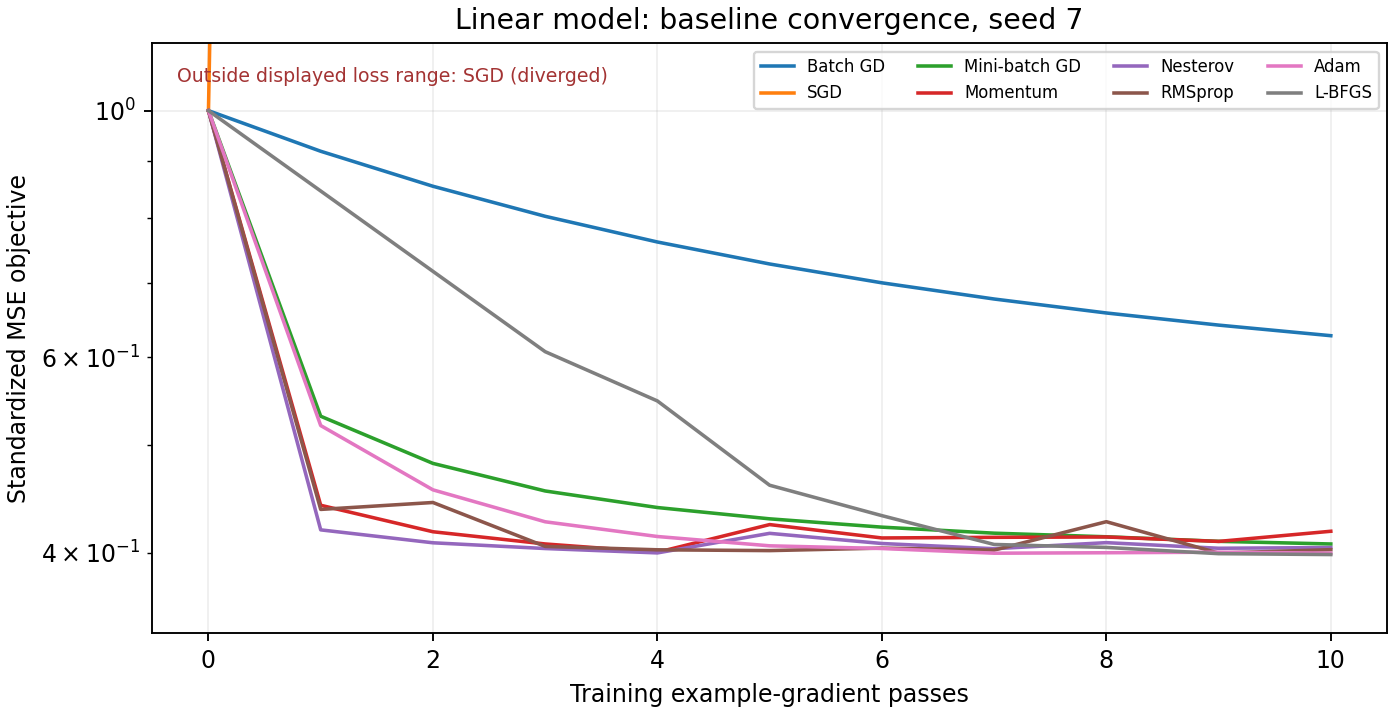

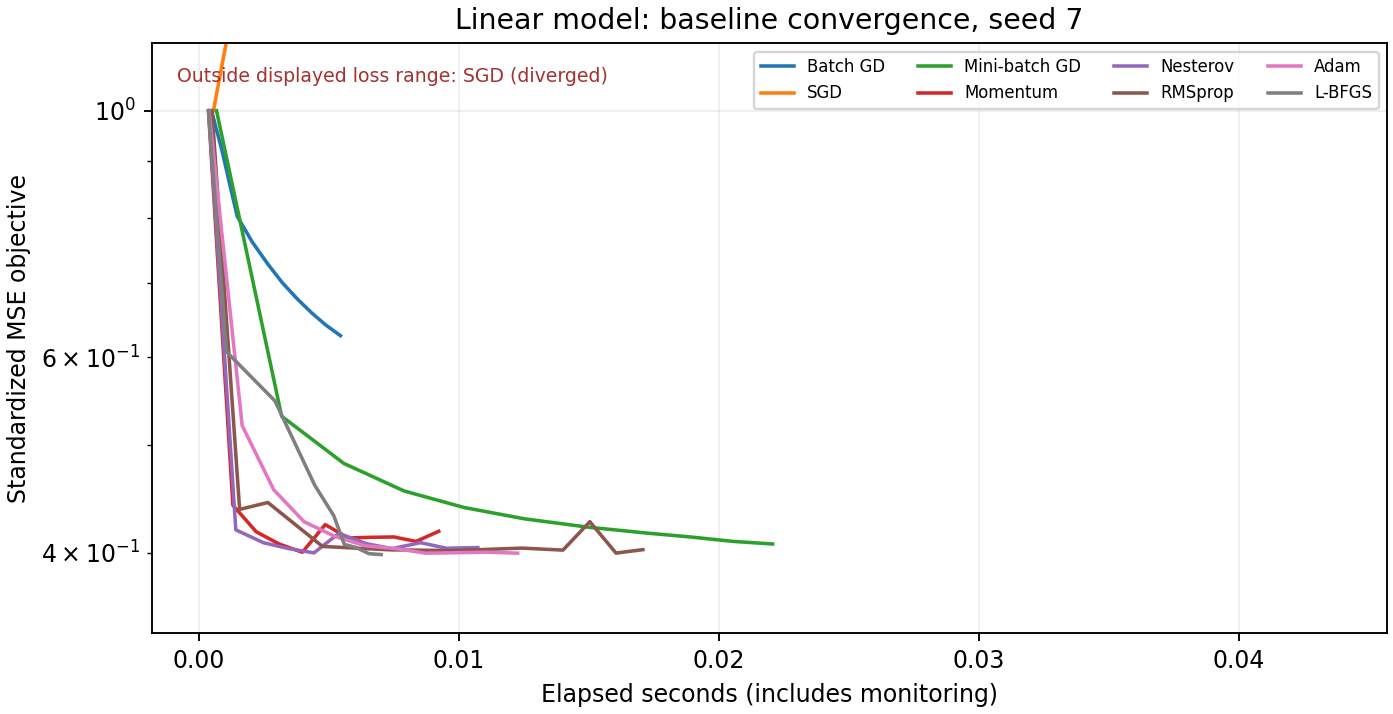

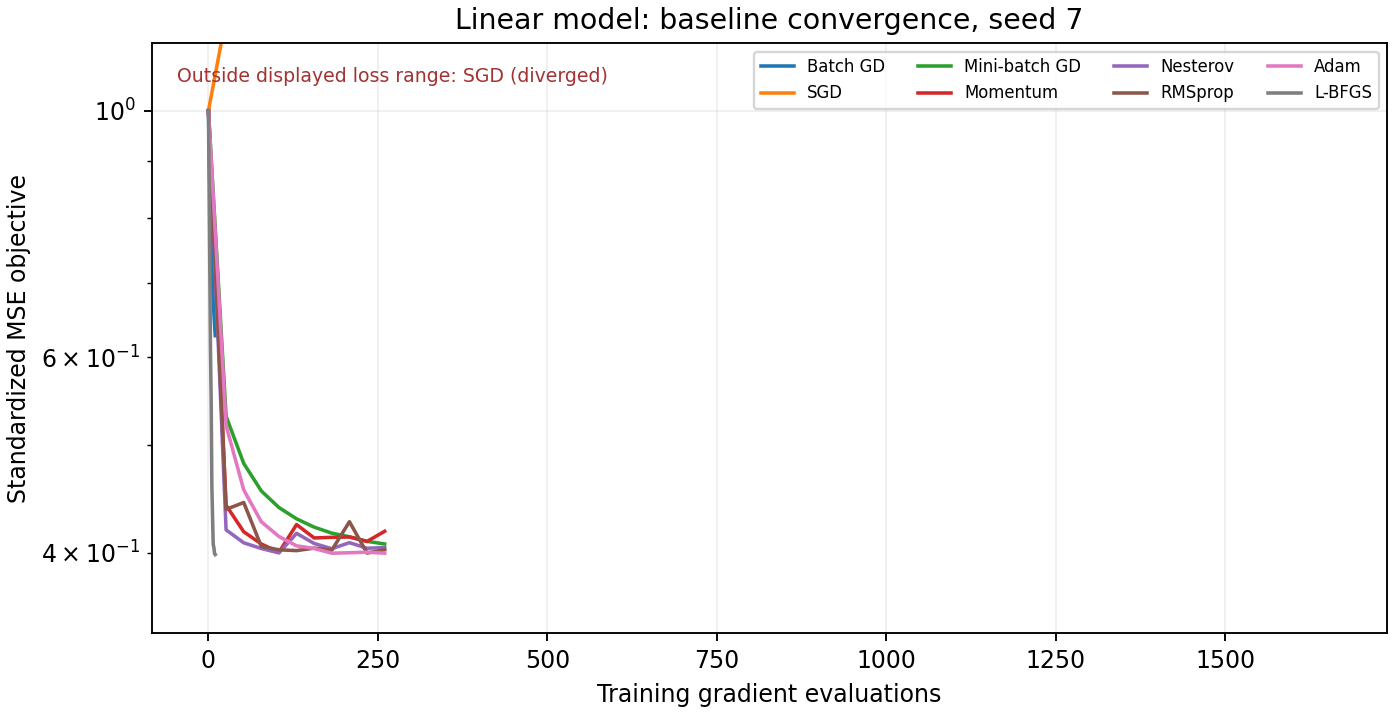

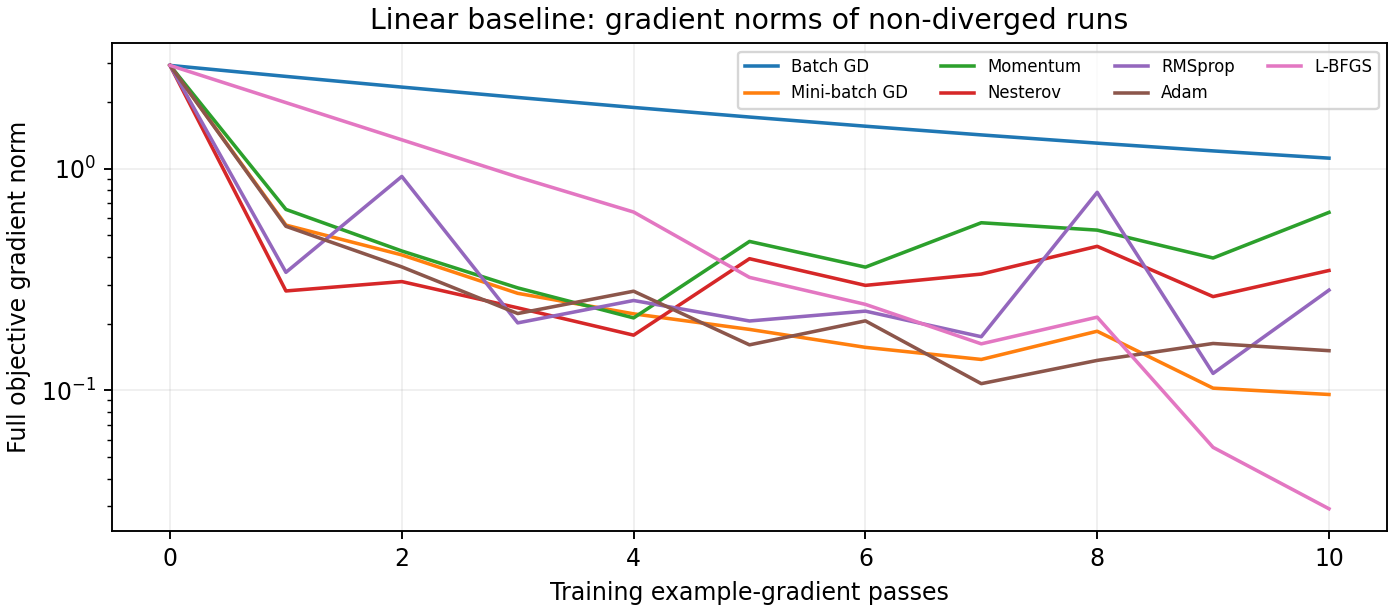

,optimizer,updates,gradient_evaluations,function_evaluations,monitor_gradient_evaluations,effective_passes,threshold_seconds,final_gradient_norm,loss_increase_fraction,peak_observed_process_rss_mib,status
0,Batch GD,10,10,10,11,10.000000,NaN,1.115217,0.0,723.191406,budget_completed
3,SGD,3219,3219,3219,2,1.943841,NaN,992.724161,1.0,723.210938,diverged
6,Mini-batch GD,260,260,260,11,10.000000,NaN,0.095794,0.0,723.210938,budget_completed
9,Momentum,260,260,260,11,10.000000,NaN,0.634857,0.4,723.210938,budget_completed
18,Nesterov,260,260,260,11,10.000000,NaN,0.347182,0.3,723.214844,budget_completed
21,RMSprop,260,260,260,11,10.000000,NaN,0.283120,0.4,723.218750,budget_completed
24,Adam,260,260,260,11,10.000000,NaN,0.150974,0.2,723.218750,budget_completed
63,L-BFGS,8,10,10,9,10.000000,NaN,0.029228,0.0,726.109375,budget_completed


In [23]:
for figure_name in ["convergence_effective_passes.png", "convergence_elapsed_seconds.png",
                    "convergence_gradient_evaluations.png", "gradient_norms.png"]:
    display(NotebookImage(filename=str(result_folder / "figures" / figure_name)))
baseline_counters = runs[(runs.model == "linear") & (runs.sweep == "baseline") & (runs.seed == 7)]
display(baseline_counters[["optimizer", "updates", "gradient_evaluations", "function_evaluations",
                           "monitor_gradient_evaluations", "effective_passes", "threshold_seconds",
                           "final_gradient_norm", "loss_increase_fraction", "peak_observed_process_rss_mib", "status"]])

## 20. Report and analysis generation code

This generator reads the measured CSV/JSON evidence and creates a nine-page academic PDF, detailed sensitivity tables, and a ten-slide/nine-minute presentation script. It makes no full-suite claim when only demo mode was executed.

In [24]:
"""Generate a nine-page academic PDF, measured analysis, and a nine-minute presentation."""
import argparse
import html
import json
from pathlib import Path

import numpy as np
import pandas as pd
from reportlab.lib import colors
from reportlab.lib.enums import TA_LEFT
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
from reportlab.lib.units import inch
from reportlab.platypus import (Image, KeepTogether, PageBreak, Paragraph, SimpleDocTemplate,
                               Spacer, Table, TableStyle)



def one_factor(runs, model, optimizer, parameter):
    frame = runs[(runs.model == model) & (runs.optimizer == optimizer)].copy()
    base = frame[frame.sweep == "baseline"].iloc[0]
    for field in ("lr", "batch_size", "momentum", "alpha", "epochs", "scaling", "schedule"):
        if field != parameter:
            frame = frame[frame[field] == base[field]]
    frame["eligible_val_rmse"] = frame.val_rmse.where(frame.status != "diverged")
    return frame.groupby(parameter).agg(mean=("eligible_val_rmse", "mean"), sd=("eligible_val_rmse", "std"),
                                        valid_seeds=("eligible_val_rmse", "count"), attempts=("seed", "size")).reset_index()


def build_report(mode="demo"):
    directory = RESULTS / mode
    report_dir = ROOT / "reports" if mode == "demo" else ROOT / "reports/full"
    report_dir.mkdir(parents=True, exist_ok=True)
    manifest = json.loads((directory / "manifest.json").read_text())
    analysis = json.loads((directory / "analysis.json").read_text())
    board, runs = pd.read_csv(directory / "leaderboard.csv"), pd.read_csv(directory / "runs.csv")
    history = pd.read_csv(directory / "histories.csv")
    champion = board.iloc[0]
    chosen_cfg = runs[runs.config_id == analysis["champion"]["config_id"]].iloc[0]
    seed_prediction = pd.read_csv(directory / "predictions.csv")
    seed_rmse = np.sqrt(np.mean((seed_prediction.actual_kwh-seed_prediction.predicted_kwh)**2))
    h = analysis["hessian"]
    failure_groups = runs[(runs.sweep == "baseline") & (runs.status == "diverged")].groupby(["model", "optimizer"]).size()
    failure_text = "; ".join(f"{model} / {optimizer}: {count} failed seeds" for (model, optimizer), count in failure_groups.items()) or "No baseline divergence was observed"
    ntrain, nval, ntest = [manifest["split"][k]["rows"] for k in ("train", "validation", "test")]
    scope = (f"First {manifest['max_hours']:,} clock hours" if manifest["max_hours"] else "Full available hourly history")
    sensitivities = [("Learning rate", "linear", "Adam", "lr"), ("Batch size", "linear", "Adam", "batch_size"),
                     ("Momentum", "linear", "Momentum", "momentum"), ("Scaling", "linear", "Adam", "scaling")]
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, axs = plt.subplots(2, 2, figsize=(8.2, 5.3), layout="constrained")
    for ax, (label, model, optimizer, parameter) in zip(axs.flat, sensitivities):
        group = one_factor(runs, model, optimizer, parameter)
        ax.errorbar(np.arange(len(group)), group["mean"], yerr=group.sd.fillna(0), marker="o", capsize=4)
        ax.set_xticks(np.arange(len(group)), group[parameter].astype(str), rotation=15)
        ax.set(xlabel=label, ylabel="Validation RMSE (kWh)", title=f"{model} / {optimizer}")
        ax.grid(alpha=.2)
    fig.savefig(directory / "figures/sensitivity.png", dpi=180)
    plt.close(fig)
    # Full-history EDA is descriptive; it does not choose features or tune parameters.
    hourly, _ = load_hourly()
    fig, axs = plt.subplots(2, 1, figsize=(8.2, 4.5), layout="constrained")
    daily = hourly.energy_kwh.resample("D").sum(min_count=24)
    axs[0].plot(daily.index, daily, lw=.7)
    axs[0].set(ylabel="Daily energy (kWh)", title="Observed complete days: one household")
    pattern = hourly.energy_kwh.groupby((hourly.index.hour-1) % 24).mean()
    axs[1].bar(pattern.index, pattern)
    axs[1].set(xlabel="Hour at interval start (local clock)", ylabel="Mean hourly kWh")
    fig.savefig(directory / "figures/dataset_eda.png", dpi=170)
    plt.close(fig)

    styles = getSampleStyleSheet()
    styles.add(ParagraphStyle(name="ReportTitle", fontName="Helvetica-Bold", fontSize=30, leading=33,
                              textColor=colors.HexColor("#112740"), spaceAfter=15))
    styles.add(ParagraphStyle(name="Deck", fontSize=13, leading=19, textColor=colors.HexColor("#42617b"), spaceAfter=14))
    styles.add(ParagraphStyle(name="BodyReport", fontSize=9.3, leading=13.5, spaceAfter=8))
    styles.add(ParagraphStyle(name="SmallReport", fontSize=8, leading=11, spaceAfter=6))
    styles.add(ParagraphStyle(name="EqReport", fontName="Courier", fontSize=9, leading=13,
                              backColor=colors.HexColor("#edf5f7"), borderPadding=8, spaceBefore=5, spaceAfter=12))
    styles["Heading1"].textColor = colors.HexColor("#112740")
    styles["Heading2"].fontSize, styles["Heading2"].leading = 12, 15
    story = []

    def p(text, style="BodyReport"):
        story.append(Paragraph(text, styles[style]))

    def title(number, text):
        p(f"{number:02d} / OPTIMIZATION IN MACHINE LEARNING", "SmallReport")
        p(text, "Heading1")

    def sub(text):
        p(text, "Heading2")

    def table(headers, rows, widths=None, font=8):
        data = [[Paragraph(html.escape(str(v)), styles["SmallReport"]) for v in headers]]
        data += [[Paragraph(html.escape(str(v)), styles["SmallReport"]) for v in row] for row in rows]
        t = Table(data, colWidths=widths, repeatRows=1, hAlign="LEFT")
        t.setStyle(TableStyle([("BACKGROUND", (0,0), (-1,0), colors.HexColor("#dceaf1")),
                               ("VALIGN", (0,0), (-1,-1), "TOP"),
                               ("ROWBACKGROUNDS", (0,1), (-1,-1), [colors.white, colors.HexColor("#f5f8fb")]),
                               ("BOTTOMPADDING", (0,0), (-1,-1), 3), ("TOPPADDING", (0,0), (-1,-1), 3),
                               ("LINEBELOW", (0,0), (-1,0), .6, colors.HexColor("#b6cbd9"))]))
        story.append(t)
        story.append(Spacer(1, 8))

    def image(name, height=None):
        path = directory / "figures" / name
        from PIL import Image as PILImage
        with PILImage.open(path) as im:
            w, hh = im.size
        width = 475
        target_h = height or width * hh / w
        story.append(Image(str(path), width=width, height=target_h))
        story.append(Spacer(1, 5))

    def page():
        story.append(PageBreak())

    p("B.TECH CSE / RESEARCH PROJECT", "SmallReport")
    p("OptiEnergy AI", "ReportTitle")
    p("A Comparative Study of Optimization Algorithms for Smart Energy Consumption Prediction", "Deck")
    p(f"Course: Optimization in Machine Learning | Reproducible CPU study | {pd.Timestamp.now().strftime('%d %B %Y')}", "SmallReport")
    sub("Abstract")
    p("This project investigates how optimization algorithms affect household next-hour energy prediction. "
      "A causal pipeline converts minute-level UCI power observations into hourly energy and creates lagged, rolling, and cyclical calendar features. "
      "Unregularized linear regression provides a convex setting, ridge adds controlled curvature, and a fixed small Tanh neural network provides a non-convex setting. "
      "Seven first-order update variants and L-BFGS are instrumented for data passes, updates, gradient/function evaluations, elapsed time, gradient norm, and checkpoint stability.")
    p(f"The included {mode} study executed {analysis['run_count']} runs across seeds 7, 21, and 42. "
      f"The validation-selected family was <b>{champion['model']} / {champion.optimizer}</b>, with mean validation RMSE "
      f"{champion.val_rmse_mean:.4f} kWh. Its final test RMSE was {champion.test_rmse_mean:.4f} +/- {champion.test_rmse_std:.4f} kWh "
      f"(sample SD), compared with persistence RMSE {analysis['persistence_test']['rmse']:.4f} kWh. "
      f"There were {analysis['diverged_runs']} diverged runs, retained as stability outcomes. "
      "These measurements do not establish a universally best optimizer.")
    sub("Research questions")
    p("1. How do curvature, conditioning, and scaling affect stable learning rates and convergence?<br/>"
      "2. How do momentum and adaptive updates trade computational cost against prediction error?<br/>"
      "3. How sensitive are results to learning rate, batch size, regularization, schedule, and seed?")
    sub("Measured scope")
    table(["Setting", "Included measurement"], [["Data budget", scope],
        ["Baseline / repetitions", f"{manifest['epochs']} epochs; 3 seeds"],
        ["Chronological train / validation / test", f"{ntrain:,} / {nval:,} / {ntest:,} usable rows"],
        ["Full multi-year sensitivity suite", "Implemented; not executed in this demo report" if mode == "demo" else "Executed for this full report"]], [200, 275])
    p("Keywords: gradient descent; stochastic optimization; conditioning; causal forecasting; reproducible experiments.", "SmallReport")
    page()

    title(2, "Dataset and causal forecasting pipeline")
    p("The UCI Individual Household Electric Power Consumption dataset contains one-minute measurements from a single household in Sceaux, France. "
      "It is distributed under CC BY 4.0 (Hebrail &amp; Berard; DOI:10.24432/C58K54). The official source was downloaded and its text-file SHA-256 stored in the run manifest.")
    table(["Quantity", "Observed value"], [["Raw minute rows", f"{manifest['dataset']['raw_rows']:,}"],
       ["Missing or invalid minutes", f"{manifest['dataset']['missing_or_invalid_minutes']:,}"],
       ["Complete hourly energy labels", f"{manifest['dataset']['complete_hours']:,}"],
       ["Incomplete / partial hours", f"{manifest['dataset']['incomplete_hours']:,}"]], [260, 215])
    p("energy_kWh(t) = sum of minute-average power_kW / 60", "EqReport")
    p("Hourly labels require 60 valid nonnegative readings. The index is the right endpoint: a row at 14:00 represents [13:00,14:00). "
      "At origin t, the target is the next interval [t,t+1h), ending at t+1h. Input gaps alone may forward-fill for at most six hours. "
      "No backward filling, centered rolling averages, or target imputation is used.")
    sub("Features and temporal separation")
    p("The 26 inputs are current energy, a missing-input indicator, lags 1/3/6/12/24h, rolling mean and standard deviation for 3/6/12/24h, "
      "hour/day/weekday/month/weekend, and sine/cosine hour/weekday/month encodings. Rolling features include the just-finished hour, which is available at the origin. "
      "The 70/15/15 split is chronological; labels reaching the next partition are purged. Scaling and target standardization use only training rows.")
    image("dataset_eda.png", 251)
    p("Figure 1. Full-history descriptive EDA; model selection uses only the stated train/validation periods. Daily totals require complete observed days.", "SmallReport")
    page()

    title(3, "Objective, curvature, and convergence theory")
    p("Let A contain the transformed features and an appended intercept column; u is the training-standardized target. "
      "Let D be diagonal with ones for weights and zero for the intercept.")
    p("J(w) = ||Aw - u||^2 / n + (alpha/2) w^T D w<br/>"
      "grad J = 2 A^T(Aw-u)/n + alpha D w<br/>H = 2 A^T A/n + alpha D", "EqReport")
    p("For any v, v-transpose H v is nonnegative, so the linear objective is convex. A positive-definite H gives a unique minimizer; "
      "redundant or constant features can make unregularized regression singular. Ridge penalizes every weight but not the intercept, increasing curvature in otherwise flat directions. "
      "Its effect is not a uniform eigenvalue shift because the intercept is unpenalized.")
    sub("Measured geometry")
    table(["Train-standardized linear design", "Value"], [
        ["Hessian dimension / numerical rank", f"{h['dimension']} / {h['numerical_rank']}"],
        ["Largest eigenvalue L", f"{h['max_eigenvalue']:.6f}"],
        ["Full condition number", "Undefined / singular at numerical tolerance" if h['condition_number'] is None else f"{h['condition_number']:.3f}"],
        ["Positive-spectrum condition number", f"{h['positive_spectrum_condition_number']:.3f}"],
        ["Batch-GD stable upper step 2/L", f"{h['safe_gd_lr_upper_bound']:.6f}"],
        ["Ridge alpha=.01 minimum eigenvalue", f"{h['ridge_alpha_0.01_min_eigenvalue']:.6f}"],
        ["Ridge alpha=.01 condition number", f"{h['ridge_alpha_0.01_condition_number']:.3f}"],
        ["Central-difference relative gradient error", f"{analysis['gradient_check_relative_error']:.3e}"]], [300, 175])
    p("For a quadratic, GD's error along an eigenvector contracts by 1-eta*lambda. Steps 0&lt;eta&lt;2/L are stable; eta&lt;=1/L ensures descent. "
      "Small curvature eigenvalues slow progress. The full-data bound does not bound each sample's curvature and therefore does not certify SGD stability. "
      "Feature scaling alters the geometry; it is evaluated as a separate experimental factor.")
    sub("Non-convex setting")
    p("The ANN has widths 26-32-16-1 with Tanh activations and the same MSE/L2 convention. Parameter interactions create a non-convex landscape. "
      "A small gradient can indicate a local minimum, a saddle, or a saturated region; it does not certify global optimality. "
      "The comparison fixes architecture and seed-specific initial weights within this family.")
    p("The numerical rank threshold is L times 1e-10. Roundoff-scale negative eigenvalues would not establish non-convexity. "
      "The finite positive-spectrum condition number is not the condition number of the singular full Hessian.", "SmallReport")
    page()

    title(4, "Optimization methods and implementation")
    p("Let g be the mean batch gradient including the exact L2 gradient. State begins at zero. First-order methods are written in NumPy for linear/ridge models; "
      "the ANN uses corresponding PyTorch optimizers. Epsilon is 1e-8.")
    table(["Method", "Implemented principle", "Cost / extra state"], [
        ["Batch GD", "w <- w - eta*g; all n rows", "O(np) / O(p)"],
        ["SGD", "Same update; one sample per step", "O(p) / O(p)"],
        ["Mini-batch GD", "Same update; b samples per step", "O(bp) / O(p)"],
        ["Momentum", "v <- beta*v-eta*g; w <- w+v", "O(bp) / O(p)"],
        ["Nesterov", "NumPy gradient at w+beta*v, then velocity update", "O(bp) / O(p)"],
        ["RMSprop", "s <- .99*s+.01*g^2; divide g by sqrt(s)+eps", "O(bp) / O(p)"],
        ["Adam", "First/second moments .9/.999, bias correction, coordinate scaling", "O(bp) / O(p)"],
        ["L-BFGS", "Inverse-Hessian action from 10 curvature pairs; line search", "O(qnp+mp) / O(mp)"]], [85, 265, 125])
    p("For L-BFGS, m=10 history pairs and q is the number of full-data evaluations for an accepted update. For neural models, replace the linear bp term "
      "by forward/backward network cost. Python/Autograd overhead makes sample-wise ANN SGD substantially different from vectorized linear SGD.")
    sub("Implementation details that matter")
    p("Adam uses per-update bias correction m/(1-.9^t), s/(1-.999^t); RMSprop has no such correction. Biases are not L2-penalized. "
      "The NumPy Nesterov code uses an explicit lookahead; PyTorch uses its standard momentum-buffer parameterization. This convention difference is disclosed, "
      "and conclusions compare optimizers within a model family rather than assuming identical iterates across libraries.")
    p("SciPy uses unconstrained L-BFGS-B for linear models; PyTorch uses strong-Wolfe L-BFGS for the ANN. Both are given a hard full-data closure budget. "
      "Accepted steps and closure evaluations are recorded separately. Learning rate, batch size, and momentum sweeps do not apply to these line-search runs.")
    sub("Validation of the implementation")
    p("Tests check analytic gradients against central differences, Hessian-vector differences, intercept regularization, exact first optimizer steps, "
      "convex benchmark convergence, all model/optimizer training combinations, repeated-seed determinism, and model save/load equivalence. "
      "Causality tests mutate future values and verify that earlier features and recursive predictions remain unchanged.")
    sub("Reference solver")
    p("Scikit-learn LinearRegression supplies a direct least-squares reference. It shares feature/target transformations and temporal partitions, "
      "but is not an iterative budget-matched optimizer. Its result is not described as an Adam result merely because other runs use Adam.")
    page()

    title(5, "Controlled experimental design")
    p(f"Measured scope: {scope.lower()}. Training has {ntrain} rows; validation {nval}; test {ntest}. "
      f"Baseline runs use {manifest['epochs']} epochs, eta=.01, batch size 64 for mini-batch methods, momentum=.9, and standard scaling. "
      "Linear and ANN use alpha=0; ridge uses alpha=.01. Linear initialization is zero; neural initialization is paired by seed.")
    table(["Experimental variable", "Values / protocol"], [
        ["Seeds", "7, 21, 42; mean and sample SD"],
        ["Learning rate", "0.0001, 0.001, 0.01, 0.1"], ["Batch size", "16, 32, 64, 128"],
        ["Momentum", "0.5, 0.9, 0.99"], ["Regularization alpha", "0, 0.001, 0.01, 0.1"],
        ["Schedule", "Constant; eta0/(1+.05*(epoch-1))"],
        ["Epoch sensitivity", "5/10/20 in demo; 10/30/60 in full mode"],
        ["Scaling", "Standard, min-max, robust, none"],
        ["Selection", "One factor at a time; mean validation RMSE; all 3 runs finite"],
        ["Final test", "Selected configuration per model/optimizer; no test-driven tuning"]], [160, 315])
    sub("Budget accounting")
    p("The first-order primary budget is epochs times n processed examples. The update count differs: one per epoch for batch GD, n per epoch for SGD, "
      "and ceil(n/b) per epoch for mini-batch methods. L-BFGS cannot exceed the same example-gradient budget, but may stop sooner due to convergence or line-search behavior. "
      "Monitoring full gradients and validation forwards is separately counted and included in measured elapsed time.")
    selected = runs[(runs.sweep == "baseline") & (runs.model == "linear") & (runs.seed == 7)]
    table(["Linear baseline / seed 7", "Updates", "Grad calls", "Data passes", "Status"], [
        [r.optimizer, int(r.updates), int(r.gradient_evaluations), f"{r.effective_passes:.2f}", r.status]
        for _, r in selected.iterrows()], [135, 60, 70, 70, 140])
    p("The demo sweeps representative pairings rather than every combination. Its tuned leaderboard therefore has unequal search budgets. "
      "Baseline curves hold settings fixed and support the cleanest within-family optimizer comparison. Full mode expands each applicable one-factor study. "
      "No full-suite results are claimed by this demo report.", "SmallReport")
    page()

    title(6, "Final predictive results")
    p("Rows are ordered by mean validation RMSE. Test metrics are revealed after configuration selection; lower test error is not used to reorder or choose the champion. "
      "Errors are in kWh and +/- is sample SD over three seeds. All unsuccessful baseline attempts remain in runs.csv and baseline_summary.csv.")
    table(["Model / optimizer", "Val RMSE", "Test RMSE +/- SD", "Test MAE", "Test R2"], [
        [f"{r['model']} / {r.optimizer}", f"{r.val_rmse_mean:.3f}", f"{r.test_rmse_mean:.3f} +/- {r.test_rmse_std:.3f}",
         f"{r.test_mae_mean:.3f}", f"{r.test_r2_mean:.3f}"] for _, r in board.iterrows()], [155, 65, 115, 70, 70])
    p(f"The selected {champion['model']} / {champion.optimizer} configuration achieved test RMSE {champion.test_rmse_mean:.4f} kWh "
      f"and R2 {champion.test_r2_mean:.4f}. Persistence achieved RMSE {analysis['persistence_test']['rmse']:.4f} kWh. "
      f"The deployed fixed seed-7 model has test RMSE {seed_rmse:.4f} kWh; this is distinct from the family mean. "
      "Small differences between top methods are not sufficient evidence of statistically significant superiority.")
    p(f"{analysis['diverged_runs']} runs diverged across the complete plan. Baseline outcomes: {failure_text}. "
      "A pairing without three non-diverged runs in any configuration has no eligible final test score. All attempted settings remain in the logs.", "SmallReport")
    page()

    title(7, "Convergence, computation, and stability")
    image("convergence_effective_passes.png", 242)
    p("Figure 2. Identical-baseline linear runs, seed 7. The loss range focuses on non-diverged runs; failed traces outside that range are explicitly marked. "
      "All raw values are in the CSV and HTML. The x-axis excludes additional monitoring. Loss uses standardized targets.", "SmallReport")
    image("convergence_elapsed_seconds.png", 242)
    p("Figure 3. The same objective against elapsed seconds, including monitoring. Timing is machine-dependent. "
      "L-BFGS may perform multiple closures per accepted step; its x-axis accounting therefore differs from the epoch plot.", "SmallReport")
    p("Stochastic updates can raise monitored loss; momentum can overshoot and adaptive coordinates do not guarantee monotonic descent. "
      "The logs retain the fraction of checkpoint increases, last-five loss SD, final gradient norm, and time to objective .35. "
      "A missing threshold time means the threshold was not observed, rather than a zero duration. Models return the validation-best checkpoint, not necessarily the final one.")
    page()

    title(8, "Sensitivity and forecast diagnostics")
    image("sensitivity.png", 306)
    p("Figure 4. One-factor validation sensitivity, mean +/- sample SD. Other fields are held at the relevant baseline. "
      "Seed is the repeated factor, not a second tuned hyperparameter. Scaling changes the optimization landscape and the meaning of a fixed ridge penalty.", "SmallReport")
    image("predictions.png", 205)
    p("Figure 5. Fixed-seed validation-selected champion, first held-out week. The figure uses actual test observations. "
      "The model is a one-hour-ahead predictor, not a perfectly smooth reconstruction of household peaks.", "SmallReport")
    p("Residual scatter and histograms are exported separately. They expose peak underprediction, asymmetry, or heteroskedasticity without changing the final selected model. "
      "The dashboard can generate 24-hour recursive forecasts by feeding predictions back into future feature rows; future observed values never enter those features. "
      "This extension has no separate multi-horizon accuracy claim.")
    page()

    title(9, "System, reproducibility, and conclusions")
    sub("Architecture and delivery")
    p("UCI download/cache -> validated hourly energy -> causal features -> chronological split -> train-only transformations -> "
      "shared model/objective -> instrumented optimizers -> validation selection -> final test -> saved model and exports. "
      "The seven-page Streamlit application exposes data analysis, interactive training, optimizer comparison, benchmark landscapes, historical forecasting, and reports.")
    sub("Benchmark interpretation")
    p("The playground includes positive-definite quadratic, condition-number-100 quadratic, Rosenbrock, and Himmelblau objectives. "
      "Contours and 3D surfaces share starting points; paths and normalized gradient arrows illustrate geometry. Exact-gradient deterministic functions "
      "make SGD and mini-batch GD identical to GD here. Multiple Himmelblau basins and Rosenbrock's curved valley demonstrate why non-convex guarantees differ from quadratic analysis.")
    sub("Reproduction and evidence")
    p("Re-run the standalone notebook from top to bottom. The test cell validates the implementation and the experiment cell executes the controlled demo. "
      "The manifest records data hash, source checksum, partitions, seeds, software versions, and CPU/thread metadata. "
      "Repeated cached results preserve their original measured training times; report regeneration time is not a new training measurement. "
      "Google Colab runs this notebook directly without a project upload. Model bundles store fitted transforms and weights without training/test arrays.")
    sub("Limitations and next steps")
    p("The dataset describes one household, and the demo spans an early contiguous period. Three seeds quantify limited seed variability, not population confidence. "
      "One validation period permits temporal selection bias; a larger study should use rolling-origin validation, multiple seasons and households, "
      "equal tuning resources, and uncertainty estimates. RSS is a sampled whole-process footprint. CPU timing includes monitoring and depends on environment load. "
      + ("Full mode can be expensive, especially sample-wise ANN SGD; it is implemented but not represented as already measured here." if mode == "demo" else "The full run remains limited to the available dataset and protocol; broader temporal and household validation is still needed."))
    p(f"Within this measured budget, validation selected {champion['model']} / {champion.optimizer}; its test error improves on persistence. "
      "The broader conclusion is that curvature, stochasticity, preprocessing, and computational accounting all matter. "
      "The project supports defensible comparisons and documents failures rather than assuming a preferred optimizer.")
    sub("References")
    p("[1] Hebrail, G. and Berard, A. Individual Household Electric Power Consumption. UCI, 2006. DOI:10.24432/C58K54.<br/>"
      "[2] Kingma, D. P. and Ba, J. Adam: A Method for Stochastic Optimization. arXiv:1412.6980, 2014.<br/>"
      "[3] Nocedal, J. Updating Quasi-Newton Matrices with Limited Storage. Mathematics of Computation 35(151), 773-782, 1980. DOI:10.1090/S0025-5718-1980-0572855-7.<br/>"
      "[4] SciPy, minimize(method='L-BFGS-B'): docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html.<br/>"
      "[5] PyTorch, Optimization algorithms: docs.pytorch.org/docs/stable/optim.html.", "SmallReport")

    def footer(canvas, doc):
        canvas.saveState()
        canvas.setStrokeColor(colors.HexColor("#d8e2eb"))
        canvas.line(58, 46, A4[0]-58, 46)
        canvas.setFont("Helvetica", 8)
        canvas.setFillColor(colors.HexColor("#53677b"))
        canvas.drawString(58, 31, "OptiEnergy AI | Measured " + mode + " study")
        canvas.drawRightString(A4[0]-58, 31, str(doc.page))
        canvas.restoreState()

    path = report_dir / "Project_Report.pdf"
    document = SimpleDocTemplate(str(path), pagesize=A4, leftMargin=58, rightMargin=58,
                                 topMargin=48, bottomMargin=61, title="OptiEnergy AI - Optimization Study",
                                 author="OptiEnergy AI Project")
    document.build(story, onFirstPage=footer, onLaterPages=footer)
    write_analysis(report_dir, directory, manifest, analysis, board, runs, chosen_cfg, seed_rmse)
    print(f"Built {path}")
    return path


def write_analysis(report_dir, directory, manifest, analysis, board, runs, chosen_cfg, seed_rmse):
    champion = board.iloc[0]
    rows = ["| Model | Optimizer | Val RMSE | Test RMSE ± SD | Test MAE | Test R² | Seconds ± SD |",
            "|---|---|---:|---:|---:|---:|---:|"]
    for _, r in board.iterrows():
        rows.append(f"| {r['model']} | {r.optimizer} | {r.val_rmse_mean:.4f} | {r.test_rmse_mean:.4f} ± {r.test_rmse_std:.4f} | "
                    f"{r.test_mae_mean:.4f} | {r.test_r2_mean:.4f} | {r.training_seconds_mean:.4f} ± {r.training_seconds_std:.4f} |")
    failure_groups = runs[(runs.sweep == "baseline") & (runs.status == "diverged")].groupby(["model", "optimizer"]).size()
    failure_text = "; ".join(f"{model}/{optimizer}: {count} failed seeds" for (model, optimizer), count in failure_groups.items()) or "none"
    text = f"""# Measured experimental analysis

This is the **{manifest['mode']}** study: {manifest['max_hours'] or 'all'} hourly records before feature filtering, baseline {manifest['epochs']} epochs, seeds {manifest['seeds']}. {analysis['run_count']} runs were attempted; {analysis['diverged_runs']} diverged. Cached repetitions retain original measured timings. Dataset raw SHA-256: `{manifest['dataset']['raw_sha256']}`.

Chronological usable row counts: {manifest['split']['train']['rows']} train, {manifest['split']['validation']['rows']} validation, {manifest['split']['test']['rows']} test. Test origins: {manifest['split']['test']['first_origin']} through {manifest['split']['test']['last_origin']}.

The champion is **{champion['model']} / {champion.optimizer}**, chosen by mean validation RMSE **{champion.val_rmse_mean:.4f} kWh**. Final test RMSE is **{champion.test_rmse_mean:.4f} ± {champion.test_rmse_std:.4f} kWh**, sample SD. The fixed deployment seed 7 has RMSE {seed_rmse:.4f} kWh, which is not the family mean. Persistence test RMSE is {analysis['persistence_test']['rmse']:.4f} kWh.

The leading validation scores are close. Their order does not demonstrate statistical significance; another row can have better test RMSE without becoming the selected champion. Test observations never guide selection.

## Validation-selected leaderboard

{chr(10).join(rows)}

## What the measured study supports

* Baseline divergence: {failure_text}. Failed runs retain finite checkpoints for diagnostics but are ineligible for final selection. The full suite includes smaller learning-rate sweeps for all first-order pairings.
* The unregularized standardized Hessian has numerical rank {analysis['hessian']['numerical_rank']} of {analysis['hessian']['dimension']}. Its full condition number is undefined at tolerance; positive-spectrum condition number is {analysis['hessian']['positive_spectrum_condition_number']:.2f}.
* Ridge alpha=.01 raises the smallest eigenvalue to {analysis['hessian']['ridge_alpha_0.01_min_eigenvalue']:.5f}. Its finite full condition number {analysis['hessian']['ridge_alpha_0.01_condition_number']:.2f} is not directly comparable to the unregularized positive-spectrum-only number.
* The full-data GD step bound is 2/L={analysis['hessian']['safe_gd_lr_upper_bound']:.5f}. SGD divergence below that bound is possible because individual samples have higher curvature.
* The analytic gradient's central-difference relative error is {analysis['gradient_check_relative_error']:.3e}.
* Full-batch linear methods are deterministic across seeds; zero predictive SD is expected. ANN initialization and mini-batch order produce variability.

## One-factor sensitivity

"""
    for title, model, optimizer, parameter in [("Learning rate", "linear", "Adam", "lr"), ("Batch size", "linear", "Adam", "batch_size"),
            ("Momentum", "linear", "Momentum", "momentum"), ("Regularization", "ridge", "Adam", "alpha"),
            ("Scaling", "linear", "Adam", "scaling"), ("Schedule", "linear", "Adam", "schedule"), ("Epochs", "linear", "Adam", "epochs")]:
        group = one_factor(runs, model, optimizer, parameter)
        text += f"### {title}: {model} / {optimizer}\n\n| {parameter} | Validation RMSE mean | Sample SD | Valid seeds / attempts |\n|---|---:|---:|---:|\n"
        for _, r in group.iterrows():
            mean = f"{r['mean']:.4f}" if np.isfinite(r['mean']) else "not scored"
            sd = f"{r.sd:.4f}" if np.isfinite(r.sd) else "not available"
            text += f"| {r[parameter]} | {mean} | {sd} | {int(r.valid_seeds)} / {int(r.attempts)} |\n"
        text += "\n"
    text += """## Reading the graphs and counters

The fixed-baseline convergence graphs hold model, objective, initial weights, split, and baseline hyperparameters constant. The tuned leaderboard can vary one selected setting per pairing. These answer different questions; demo tuning coverage differs across pairings. Effective data passes, gradient calls, optimizer updates, and seconds must be interpreted together. Monitoring overhead is separately counted and included in seconds. Checkpoint stability and threshold time depend on monitoring frequency. Memory is checkpoint-sampled whole-process RSS.

A lower final training objective can generalize worse; returned models use validation-best checkpoints. `final_training_loss` and `final_gradient_norm` refer to the last finite checkpoint, not necessarily the restored model. `best_epoch` identifies the returned checkpoint. Missing threshold time means not reached. Failed runs remain in `runs.csv` and `baseline_summary.csv`; absence from the final leaderboard is deliberate.

## Limits

This study does not establish multi-household generalization or universal optimizer superiority. Three-seed SD is not a confidence interval. The supplied demo does not measure full-year performance; full mode must be executed separately for the complete history and sensitivity coverage. Recursive 24-hour forecasts are a causal extension with no separately claimed multi-horizon score. Reference data: Hebrail & Berard, UCI, DOI:10.24432/C58K54.
"""
    (report_dir / "Experimental_Analysis.md").write_text(text, encoding="utf-8")
    chosen = {k: chosen_cfg[k] for k in ("model", "optimizer", "lr", "batch_size", "epochs", "momentum", "alpha", "scaling", "schedule")}
    presentation = f"""# OptiEnergy AI - presentation content and speaker notes

**10 slides · 9 minutes total.** The measurements below are from the actual {manifest['mode']} run, not a proposed full experiment. Use the named exported graphs on the matching slides.

## 1. Title and research question (0:00-0:40)

**On slide:** OptiEnergy AI. Which optimization methods reach useful next-hour forecasts efficiently and stably?

**Speaker notes:** Electricity forecasting is the application, while optimization is the main research subject. I compare convex linear/ridge models and a non-convex ANN, holding conditions fixed within each family. I measure accuracy together with computation and stability.

## 2. Dataset and units (0:40-1:30)

**On slide:** UCI 235; {manifest['dataset']['raw_rows']:,} minute records; kWh = sum(kW)/60; {manifest['dataset']['complete_hours']:,} complete observed hours. Visual: `figures/dataset_eda.png`.

**Speaker notes:** Power and energy have different units. Only complete 60-minute hours form targets. At origin t, the previous hour is finished; I predict the next interval. Missing targets are never filled. Credit Hebrail and Berard, DOI:10.24432/C58K54, CC BY 4.0.

## 3. Leakage-safe features and splits (1:30-2:20)

**On slide:** 26 causal inputs; lags 1/3/6/12/24; rolling mean/std; cyclical calendar; chronological 70/15/15; boundary purge; train-only scaling.

**Speaker notes:** Forward fill is limited to six input hours. Every feature uses information available at the forecast origin. I purge labels crossing split boundaries, fit transformations on training rows, and test causality by changing future observations. The demo has {manifest['split']['train']['rows']} train, {manifest['split']['validation']['rows']} validation, and {manifest['split']['test']['rows']} test rows.

## 4. Objective and geometry (2:20-3:20)

**On slide:** J=||Aw-u||²/n + alpha*wᵀDw/2. Gradient=2Aᵀ(Aw-u)/n+alpha*Dw. Hessian=2AᵀA/n+alpha*D. GD: 0<eta<2/L.

**Speaker notes:** The Hessian is positive semidefinite, proving convexity. Redundant inputs make it singular; the numerical rank is {analysis['hessian']['numerical_rank']}/{analysis['hessian']['dimension']}. Ridge adds curvature without penalizing the bias. ANN parameters interact nonlinearly, so the global convex guarantee no longer applies. My gradient-check error is {analysis['gradient_check_relative_error']:.2e}.

## 5. Eight optimization methods (3:20-4:15)

**On slide:** Batch GD, SGD, mini-batch GD, Momentum, Nesterov, RMSprop, Adam, L-BFGS. Show two update equations plus state/cost table.

**Speaker notes:** The seven first-order variants are hand-written for linear models. Momentum stores direction, RMSprop stores squared gradients, and Adam stores first and second moments with bias correction. L-BFGS stores curvature pairs and uses a line search. I count every closure evaluation, because one accepted step may cost several gradients.

## 6. Fair experimental protocol (4:15-5:10)

**On slide:** Seeds 7/21/42; same initialization and split; equal example-processing budgets; separate updates/gradients/time; validation-only tuning; final test.

**Speaker notes:** An epoch is one data pass but has different update counts. Monitoring is separately counted, and timing includes it. One-factor sensitivity changes learning rate, batch size, momentum, regularization, schedule, epochs, or scaling. Demo sweeps representative pairings; full mode expands coverage. The direct sklearn solution is a reference rather than an iterative matched-budget method.

## 7. Measured results (5:10-6:15)

**On slide:** {analysis['run_count']} runs; {analysis['diverged_runs']} diverged. Validation selection: **{champion['model']} / {champion.optimizer}**. Test RMSE **{champion.test_rmse_mean:.3f} ± {champion.test_rmse_std:.3f} kWh**; persistence **{analysis['persistence_test']['rmse']:.3f} kWh**. Visual: `figures/leaderboard.png`.

**Speaker notes:** These are actual measurements on {manifest['max_hours'] or 'all'} clock hours, not all four years for demo mode. The lowest validation mean selects the champion; a better observed test score does not change selection. Close top scores do not establish significance. The deployable model uses fixed seed 7, whose score is {seed_rmse:.3f} kWh. Selection: {chosen}.

## 8. Convergence and sensitivity (6:15-7:15)

**On slide:** `figures/convergence_effective_passes.png` and `figures/sensitivity.png`.

**Speaker notes:** Read loss against data passes and time, not just epochs. The linear SGD baseline at .01 diverged; its failure remains in the logs. A full-data curvature bound does not guarantee per-sample stability. High momentum and learning rates can overshoot; small steps can underfit a short budget. State which comparison is baseline and which is tuned.

## 9. Dashboard demonstration (7:15-8:15)

**On slide:** Seven pages; interactive training; 2D/3D landscapes; historical energy prediction; exports.

**Demo sequence:** Open Optimizer Comparison, change the budget axis; open Playground, compare ill-conditioned quadratic and Rosenbrock; open Energy Prediction, choose a historical origin and show a 24-hour recursive forecast.

**Speaker notes:** Benchmark gradients isolate geometry. Recursive forecasts truncate observations at the origin and feed only predictions forward. Actual future readings appear solely for comparison. Multi-horizon accuracy has not been separately validated.

## 10. Conclusions and limitations (8:15-9:00)

**On slide:** Geometry and budgets matter. Reproducible code and real results. Limits: one household, short demo, three seeds. Next: full suite, rolling-origin validation, more households.

**Speaker notes:** This project demonstrates mathematical formulation, self-implemented methods, controlled experiments, and honest reporting. It does not declare a universally best optimizer. The next scientific step is stronger temporal evaluation and equal tuning resources across families. Questions are welcome.

## Before presenting

Run the dashboard and cache the pages. Keep the exported PNGs available offline. Rehearse the nine-minute script. Be ready to derive the gradient, explain kW-to-kWh conversion, and distinguish gradient calls from processed examples. The complete algorithm equations and 40 viva answers are in the companion notes.
"""
    (report_dir / "Presentation_Content.md").write_text(presentation, encoding="utf-8")

## 21. Hyperparameter sensitivity

Only the named parameter changes relative to its pairing's baseline. Diverged repetitions do not contribute a sensitivity score, and valid-seed counts are disclosed. The regularization convention is alpha/2 times squared non-bias weights.

Built C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\reports\Project_Report.pdf


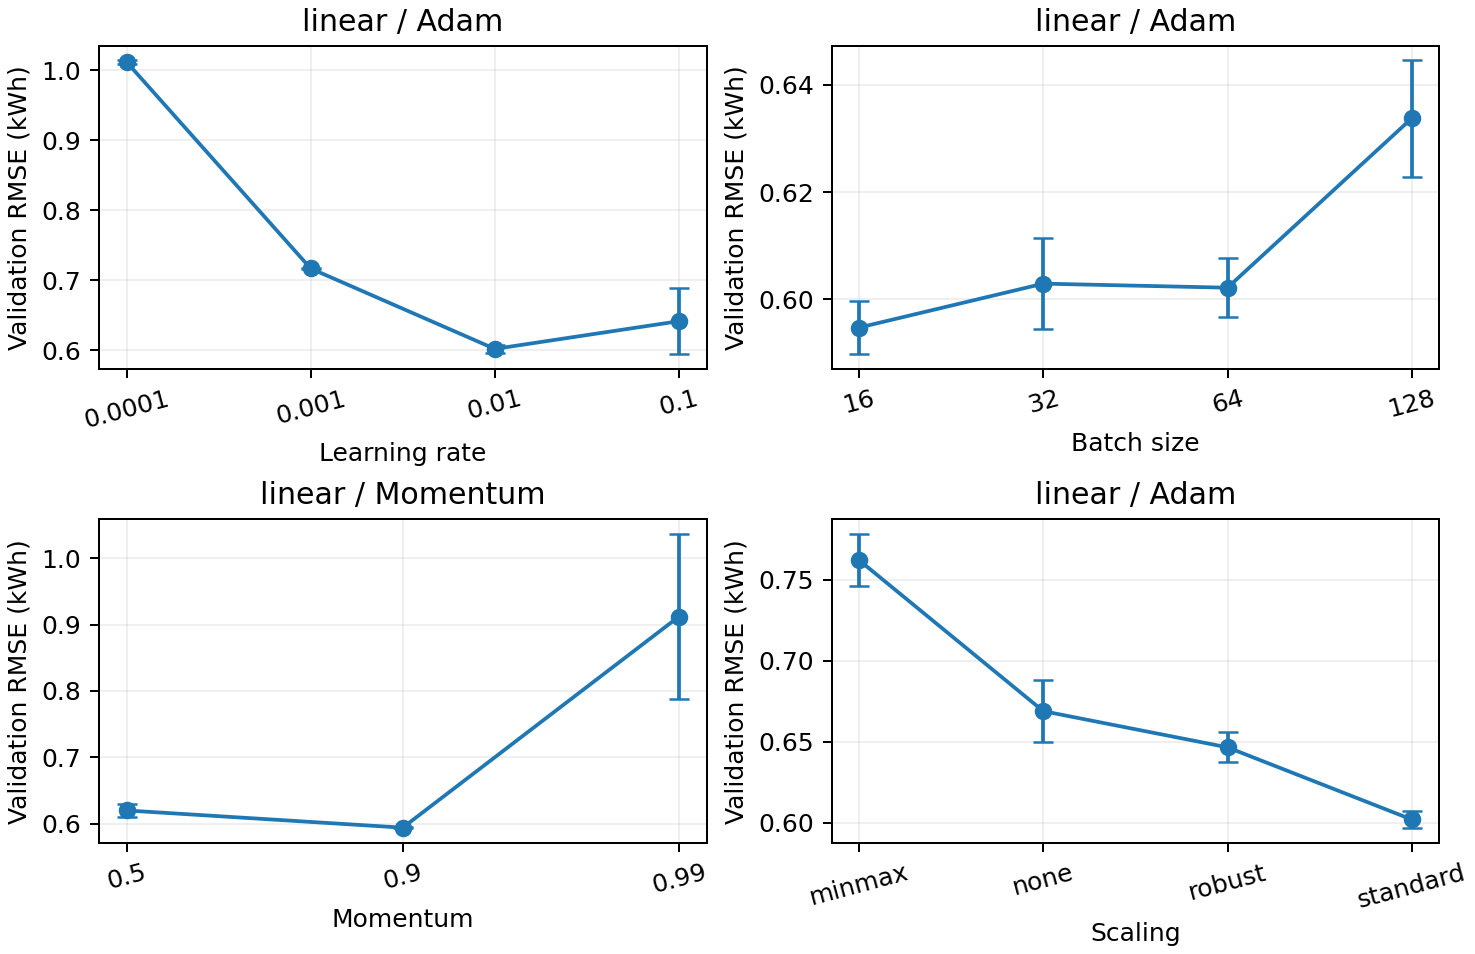

**Learning rate — linear / Adam**

,lr,mean,sd,valid_seeds,attempts
0,0.0001,1.01188,0.00242,3,3
1,0.0010,0.71694,0.00060,3,3
2,0.0100,0.60215,0.00550,3,3
3,0.1000,0.64173,0.04750,3,3


**Batch size — linear / Adam**

,batch_size,mean,sd,valid_seeds,attempts
0,16,0.59471,0.00502,3,3
1,32,0.60291,0.00845,3,3
2,64,0.60215,0.00550,3,3
3,128,0.63374,0.01085,3,3


**Momentum — linear / Momentum**

,momentum,mean,sd,valid_seeds,attempts
0,0.50,0.61991,0.00918,3,3
1,0.90,0.59396,0.00113,3,3
2,0.99,0.91209,0.12407,3,3


... (4 outputs left out)

**Epochs — linear / Adam**

,epochs,mean,sd,valid_seeds,attempts
0,5,0.62292,0.00530,3,3
1,10,0.60215,0.00550,3,3
2,20,0.59428,0.01057,3,3


**Scaling — linear / Adam**

,scaling,mean,sd,valid_seeds,attempts
0,minmax,0.76192,0.01606,3,3
1,none,0.66890,0.01896,3,3
2,robust,0.64661,0.00928,3,3
3,standard,0.60215,0.00550,3,3


In [25]:
# Generate the report and the measured sensitivity figure from this notebook run.
report_path = build_report(MODE)
display(NotebookImage(filename=str(result_folder / "figures/sensitivity.png")))
for label, family, method, parameter in [
    ("Learning rate", "linear", "Adam", "lr"),
    ("Batch size", "linear", "Adam", "batch_size"),
    ("Momentum", "linear", "Momentum", "momentum"),
    ("L2 strength", "ridge", "Adam", "alpha"),
    ("Learning-rate schedule", "linear", "Adam", "schedule"),
    ("Epochs", "linear", "Adam", "epochs"),
    ("Scaling", "linear", "Adam", "scaling"),
]:
    display(Markdown(f"**{label} — {family} / {method}**"))
    display(one_factor(runs, family, method, parameter).round(5))

## 22. Actual/predicted energy, residuals, and coefficients

The deployable champion is chosen by validation mean and uses fixed seed 7. Its individual score is distinct from the family mean. Inspect residuals without using them to reselect a model on the held-out test set.

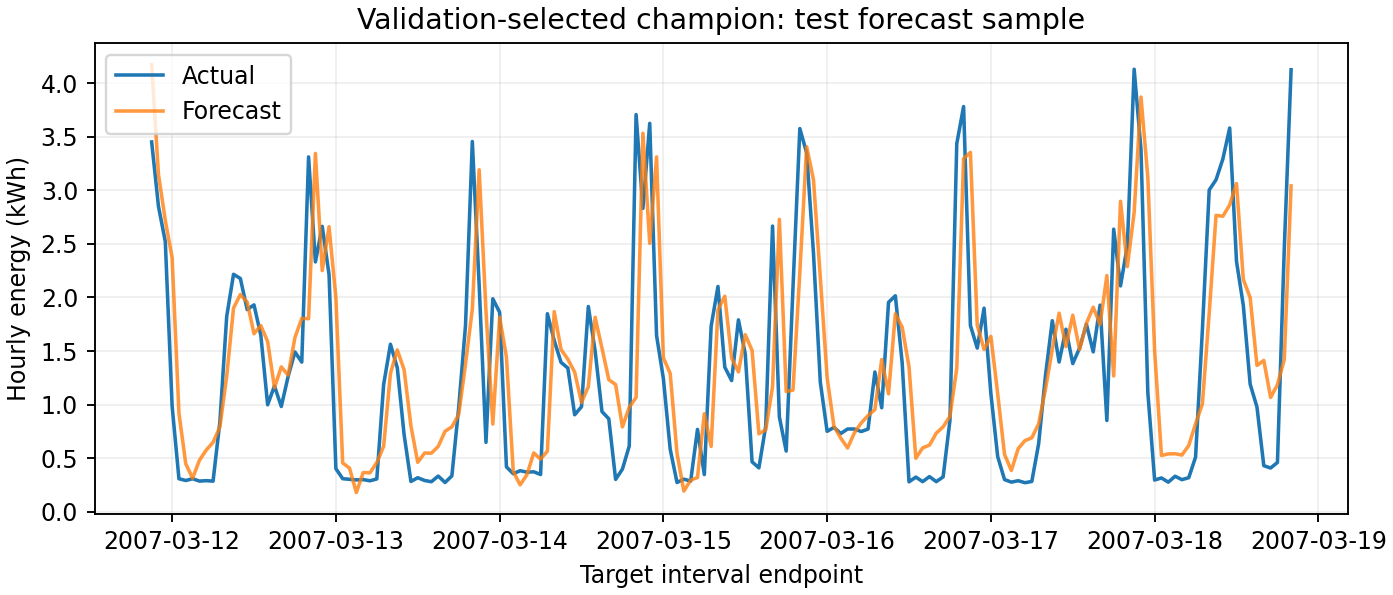

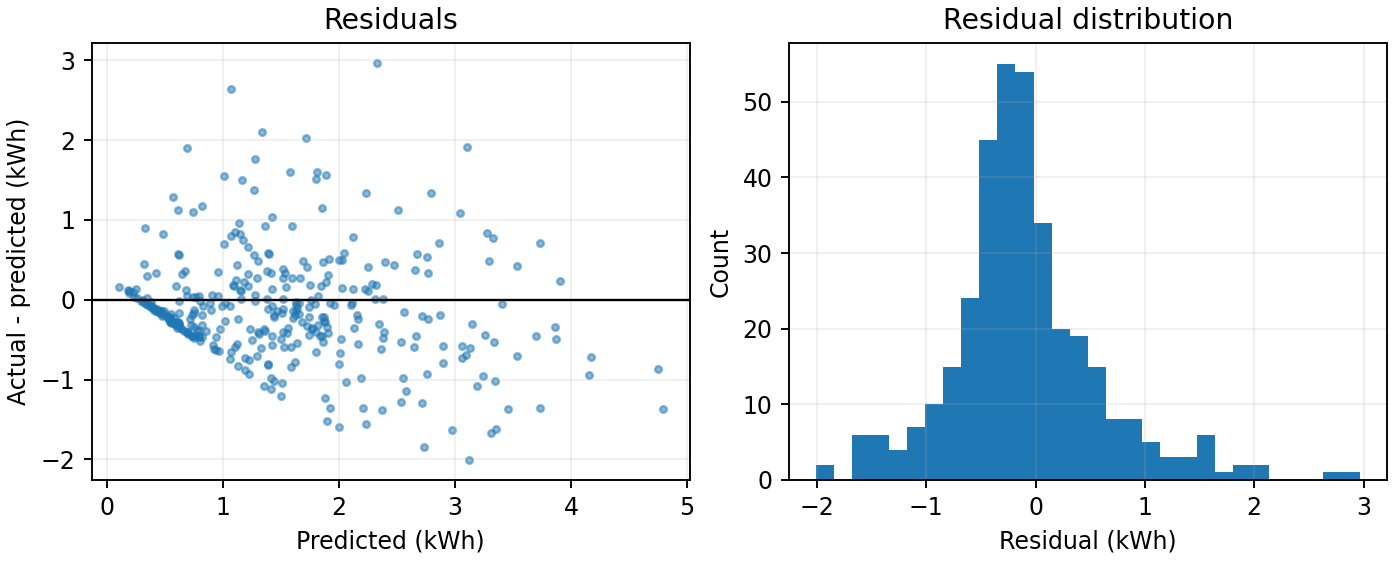

,deployment_seed,mse,rmse,mae,r2
0,7,0.479044,0.69213,0.505864,0.567239


In [26]:
for figure_name in ["predictions.png", "residuals.png"]:
    display(NotebookImage(filename=str(result_folder / "figures" / figure_name)))
champion_bundle = load_bundle(result_folder / "champion.joblib")  # Our own trusted artifact.
test_predictions = pd.read_csv(result_folder / "predictions.csv", parse_dates=["origin", "target_time"])
champion_seed_metrics = regression_metrics(test_predictions.actual_kwh, test_predictions.predicted_kwh)
display(pd.DataFrame([{"deployment_seed": 7, **champion_seed_metrics}]))

if hasattr(champion_bundle["model"], "weights"):
    transform = champion_bundle["transform"]
    selected_data = prepare_data(hourly, scaling=champion_bundle["config"]["scaling"], max_hours=MAX_HOURS)
    coefficient_scale = getattr(transform["scaler"], "scale_", np.ones(len(selected_data.feature_names)))
    if selected_data.scaling == "minmax":
        raw_coefficients = champion_bundle["model"].weights[:-1]*coefficient_scale
    else:
        raw_coefficients = champion_bundle["model"].weights[:-1]/coefficient_scale
    effects = raw_coefficients*selected_data.frames["train"][selected_data.feature_names].std(ddof=0).to_numpy()*selected_data.y_std
    coefficient_frame = pd.DataFrame({"feature": selected_data.feature_names, "effect_kwh_per_sd": effects})
    px.bar(coefficient_frame.sort_values("effect_kwh_per_sd"), x="effect_kwh_per_sd", y="feature", orientation="h",
           title="Linear association per training feature SD (not causal importance)", height=650).show()

## 23. Interactive optimization landscapes

Change `FUNCTION`, `METHODS`, `STEP_SIZE`, and `STEPS` and run this cell again. Quadratics illustrate curvature and stable steps; Rosenbrock illustrates a narrow curved valley; Himmelblau has multiple basins. On deterministic exact-gradient functions, SGD and mini-batch GD coincide with GD. Gradient arrows are normalized negative gradients, not momentum directions.

In [27]:
FUNCTION = "Rosenbrock"  # Quadratic / Ill-conditioned quadratic / Rosenbrock / Himmelblau
METHODS = ["Batch GD", "Momentum", "Adam", "L-BFGS"]
STEP_SIZE = BENCHMARKS[FUNCTION][3]
STEPS = 150
paths = {method: trajectory(FUNCTION, method, STEP_SIZE, steps=STEPS) for method in METHODS}
landscape(FUNCTION, paths, three_d=False, animate=True).show()
landscape(FUNCTION, paths, three_d=True).show()
display(pd.DataFrame([
    {"optimizer": method, "accepted_points": len(path), "last_x": path[-1, 0], "last_y": path[-1, 1],
     "last_objective": float(BENCHMARKS[FUNCTION][0](path[-1])[0])}
    for method, path in paths.items()
]))

,optimizer,accepted_points,last_x,last_y,last_objective
0,Batch GD,151,-0.904729,0.826598,3.634494e+00
1,Momentum,151,0.743456,0.551429,6.598323e-02
2,Adam,151,-1.092105,1.108910,5.078856e+00
3,L-BFGS,37,0.999999,0.999998,2.807650e-12


## 24. Historical next-hour and recursive forecasts

Choose an origin from `test_predictions.origin` or any later historical origin with complete feature history. The default uses the first held-out test origin. Future actual values are attached only for comparison. Multi-step forecasts feed previous predictions forward and have no separately tuned multi-horizon accuracy claim.

In [28]:
FORECAST_ORIGIN = test_predictions.origin.iloc[0]
HORIZON = 24  # 1 through 24
forecast_output = forecast(champion_bundle, hourly, FORECAST_ORIGIN, horizon=HORIZON)
display(forecast_output)
fig = px.line(forecast_output, x="target_time", y=["actual_kwh", "predicted_kwh"], markers=True,
               title=f"Forecast issued at {FORECAST_ORIGIN} — energy in intervals ending at each timestamp",
               labels={"value": "Hourly energy (kWh)", "target_time": "Target interval endpoint"})
fig.show()
forecast_output.to_csv(result_folder / "recursive_forecast.csv", index=False)
print(f"Next-hour prediction: {forecast_output.predicted_kwh.iloc[0]:.3f} kWh")

changed_future = hourly.copy()
changed_future.loc[changed_future.index > FORECAST_ORIGIN, "energy_kwh"] = 9999
mutation_check = forecast(champion_bundle, changed_future, FORECAST_ORIGIN, horizon=HORIZON)
np.testing.assert_array_equal(forecast_output.predicted_kwh, mutation_check.predicted_kwh)
print("Future-mutation check passed: predicted values do not use future observations.")

,forecast_origin,target_time,horizon,predicted_kwh,actual_kwh
0,2007-03-11 20:00:00,2007-03-11 21:00:00,1,4.172791,3.451300
1,2007-03-11 20:00:00,2007-03-11 22:00:00,2,3.728741,2.849967
2,2007-03-11 20:00:00,2007-03-11 23:00:00,3,3.374915,2.520667
3,2007-03-11 20:00:00,2007-03-12 00:00:00,4,3.051416,0.985467
4,2007-03-11 20:00:00,2007-03-12 01:00:00,5,2.590622,0.307733
5,2007-03-11 20:00:00,2007-03-12 02:00:00,6,2.196432,0.291500
6,2007-03-11 20:00:00,2007-03-12 03:00:00,7,1.792165,0.308233
7,2007-03-11 20:00:00,2007-03-12 04:00:00,8,1.524477,0.285900
8,2007-03-11 20:00:00,2007-03-12 05:00:00,9,1.429772,0.289833
9,2007-03-11 20:00:00,2007-03-12 06:00:00,10,1.439095,0.285333


Next-hour prediction: 4.173 kWh


Future-mutation check passed: predicted values do not use future observations.


## 25. Notebook controls

These widgets provide lightweight in-notebook controls for training, convergence comparisons, landscapes, and historical forecasts. Each training click uses validation metrics; the controlled experiment above owns final test selection. In Colab, the custom widget manager is enabled when available. The notebook also works by editing and rerunning the ordinary parameter cells if widget rendering is unavailable.

In [29]:
import ipywidgets as widgets
if IN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()

model_control = widgets.Dropdown(options=["linear", "ridge", "ann", "sklearn"], description="Model:")
optimizer_control = widgets.Dropdown(options=list(OPTIMIZERS), value="Adam", description="Optimizer:")
lr_control = widgets.SelectionSlider(options=[.0001, .001, .01, .1], value=.01, description="LR:")
batch_control = widgets.Dropdown(options=[16, 32, 64, 128], value=64, description="Batch:")
epoch_control = widgets.IntSlider(min=1, max=50, value=10, description="Epochs:")
momentum_control = widgets.SelectionSlider(options=[.5, .9, .99], value=.9, description="Momentum:")
alpha_control = widgets.Dropdown(options=[0., .001, .01, .1], value=0., description="L2:")
training_button = widgets.Button(description="Train on demo data", button_style="success")
training_output = widgets.Output()

def train_from_controls(_):
    with training_output:
        training_output.clear_output(wait=True)
        family = model_control.value
        cfg = TrainConfig(model=family, optimizer=optimizer_control.value, lr=lr_control.value,
                          batch_size=batch_control.value, epochs=epoch_control.value,
                          momentum=momentum_control.value, alpha=alpha_control.value if family in {"ridge", "ann"} else 0.)
        data = prepare_data(hourly, max_hours=DEMO_HOURS)
        result = train(data, cfg)
        display(pd.DataFrame([{k: result.summary[k] for k in ["status", "val_rmse", "val_mae", "val_r2", "training_seconds"]}]))
        line(result.history, "epoch", ["train_loss", "validation_loss"], title="Interactive training: validation only").show()
training_button.on_click(train_from_controls)
training_tab = widgets.VBox([widgets.HBox([model_control, optimizer_control]),
                            widgets.HBox([lr_control, batch_control]), widgets.HBox([epoch_control, momentum_control]),
                            alpha_control, training_button, training_output])

compare_model = widgets.Dropdown(options=["linear", "ridge", "ann"], description="Model:")
compare_axis = widgets.Dropdown(options=["effective_passes", "epoch", "elapsed_seconds", "gradient_evaluations"], description="X axis:")
compare_button = widgets.Button(description="Show baseline curves")
compare_output = widgets.Output()
def compare_from_controls(_):
    with compare_output:
        compare_output.clear_output(wait=True)
        frame = histories[(histories.model == compare_model.value) & (histories.sweep == "baseline") & (histories.seed == 7)]
        line(frame, compare_axis.value, "train_loss", "optimizer", "Identical-baseline comparison").show()
compare_button.on_click(compare_from_controls)
compare_tab = widgets.VBox([widgets.HBox([compare_model, compare_axis]), compare_button, compare_output])

function_control = widgets.Dropdown(options=list(BENCHMARKS), description="Function:")
landscape_button = widgets.Button(description="Draw trajectories")
landscape_output = widgets.Output()
def landscape_from_controls(_):
    with landscape_output:
        landscape_output.clear_output(wait=True)
        name = function_control.value
        paths = {method: trajectory(name, method, BENCHMARKS[name][3], steps=150)
                 for method in ["Batch GD", "Momentum", "Adam", "L-BFGS"]}
        landscape(name, paths, animate=True).show()
landscape_button.on_click(landscape_from_controls)
landscape_tab = widgets.VBox([function_control, landscape_button, landscape_output])

origin_control = widgets.Dropdown(options=[(str(origin), str(origin)) for origin in test_predictions.origin], description="Origin:",
                                  layout=widgets.Layout(width="420px"))
horizon_control = widgets.IntSlider(min=1, max=24, value=1, description="Horizon:")
forecast_button = widgets.Button(description="Forecast", button_style="info")
forecast_widget_output = widgets.Output()
def forecast_from_controls(_):
    with forecast_widget_output:
        forecast_widget_output.clear_output(wait=True)
        display(forecast(champion_bundle, hourly, origin_control.value, horizon=horizon_control.value))
forecast_button.on_click(forecast_from_controls)
forecast_tab = widgets.VBox([origin_control, horizon_control, forecast_button, forecast_widget_output])

notebook_controls = widgets.Tab(children=[training_tab, compare_tab, landscape_tab, forecast_tab])
for index, title in enumerate(["Model training", "Optimizer comparison", "Playground", "Forecast"]):
    notebook_controls.set_title(index, title)
display(notebook_controls)

## 26. Generated report, tables, presentation, and downloads

The files below are generated directly from this notebook's measured results. In Jupyter/VS Code, open `OptiEnergy_Notebook_Work/` or use the relative links. In Colab, use the Files panel or change `COLAB_DOWNLOAD` to an exact filename. No archive is required.

In [30]:
report_folder = ROOT / "reports" if MODE == "demo" else ROOT / "reports/full"
deliverables = [report_path, report_folder / "Experimental_Analysis.md", report_folder / "Presentation_Content.md",
                result_folder / "leaderboard.csv", result_folder / "runs.csv", result_folder / "histories.csv",
                result_folder / "predictions.csv", result_folder / "recursive_forecast.csv"]
for path in deliverables:
    relative_path = path.relative_to(Path.cwd())
    if IN_COLAB:
        print(relative_path.as_posix())
    else:
        display(FileLink(relative_path.as_posix()))

COLAB_DOWNLOAD = None  # For example: "Project_Report.pdf" or "leaderboard.csv".
if IN_COLAB and COLAB_DOWNLOAD:
    from google.colab import files as colab_files
    match = next((path for path in deliverables if path.name == COLAB_DOWNLOAD), None)
    if match is None:
        raise ValueError("Choose a filename from the generated deliverables listed above.")
    colab_files.download(str(match))

C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\reports\Project_Report.pdf

C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\reports\Experimental_Analysis.md

C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\reports\Presentation_Content.md

C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\results\demo\leaderboard.csv

C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\results\demo\runs.csv

C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\results\demo\histories.csv

C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\results\demo\predictions.csv

C:\Users\admin\Documents\Codex\2026-11-24\c\work\notebook_validation\OptiEnergy_Notebook_Work\results\demo\recursive_forecast.csv

## 27. Full mathematical notes

The following is the companion mathematical documentation, included directly in the notebook for study and viva preparation.

# Mathematical formulation and optimization notes

## 1. Forecasting problem and units

Let `p_m` be the minute-average household active power in kW. For a complete hour ending at t,

\[
e_t=\frac{1}{60}\sum_{m\in[t-1h,t)}p_m\quad\text{kWh}.
\]

At forecast origin t, predict `y_t=e_(t+1)` from `x_t`, constructed using observations through t. Calendar features describe the next interval `[t,t+1h)`. The information set is `F_t = sigma(e_s: s<=t, calendar)`, and the forecast must be measurable with respect to `F_t`. Complete observed targets are never filled. Short missing input intervals can be causally forward-filled.

Training-only transformations produce `z_j=(x_j-mu_j)/s_j` (for standard scaling) and `u=(y-mu_y)/s_y`. All models in a comparison optimize the same standardized-target objective and use the same fitted transformations. Results are inverted to kWh. Changing feature scaling is its own experiment because it changes optimization geometry and the interpretation of a fixed regularization coefficient.

## 2. Linear model, loss, gradient, and Hessian

Append a column of ones to form the design matrix `A in R^(n x (d+1))`. Let `w=(theta,b)` and `D=diag(1,...,1,0)` so the intercept is not regularized.

\[
\hat u=Aw,\quad J(w)=\frac1n\|Aw-u\|_2^2+\frac\alpha2w^TDw.
\]

\[
\nabla J(w)=\frac2n A^T(Aw-u)+\alpha Dw,
\qquad H=\nabla^2J(w)=\frac2n A^TA+\alpha D.
\]

For any vector v, `v^T H v=2||Av||²/n+alpha||D v||²>=0`; therefore the linear/ridge objective is convex. It is strictly convex exactly when the Hessian is positive definite. Correlated calendar and lag variables, constant indicators, or redundant rolling features can make the unregularized Hessian singular. A tiny negative computed eigenvalue near machine precision is roundoff, not proof of non-convexity.

For alpha>0, the non-intercept directions are regularized and the intercept column is nonzero, giving a positive-definite Hessian in this formulation. Ridge improves conditioning by raising eigenvalues, though the unpenalized intercept means the eigenvalues are **not simply all shifted by alpha**. Its optimum solves `(2A^TA/n + alpha D)w = 2A^T u/n`.

The smoothness constant is `L=lambda_max(H)`. With positive-definite H, `mu=lambda_min(H)>0` and the spectral condition number is `kappa=L/mu`. For singular H, the full condition number is infinite/undefined; the implementation records JSON null and also reports the positive-spectrum condition number with an explicit numerical rank tolerance `L*1e-10`.

Batch GD on a quadratic is stable for `0<eta<2/L`; `eta<=1/L` ensures descent. Along each eigenvector its error contracts by `1-eta*lambda_i`. For strongly convex smooth losses, appropriate constant-step GD has a linear rate bounded in terms of mu/L. A bound from the **full-data** Hessian does not guarantee stability for every stochastic sample Hessian. Outliers can make the maximum single-sample curvature much larger.

The central difference gradient check is

\[
g_j^{num}=\frac{J(w+\epsilon e_j)-J(w-\epsilon e_j)}{2\epsilon},\quad
error=\frac{\|g^{num}-g\|_2}{\max(1,\|g^{num}\|_2,\|g\|_2)}.
\]

Unit tests check both random weights and L2/intercept behavior. Finite differences of gradients verify the Hessian action.

## 3. Neural model and non-convexity

The fixed network is `f(z)=W3 tanh(W2 tanh(W1 z+b1)+b2)+b3`, with hidden widths 32 and 16. Its loss is mean standardized squared error plus `alpha/2` times the squared Frobenius norms of weight matrices. Biases are excluded, matching the linear regularization convention. Autograd differentiates the same objective used for monitoring.

Parameter products and nonlinear activations make the parameter-space loss non-convex. Stationary points can be minima or saddles; the linear-model condition-number guarantee does not transfer globally. A small gradient alone does not certify a global optimum. Initialization, batch noise, saturation, learning rate, and optimizer state can affect the reachable basin.

## 4. Implemented optimizer updates

Let `g_t` denote the mini-batch mean gradient **including the exact L2 gradient**, and let epsilon be `1e-8`. Every state is zero-initialized. Batch GD uses all n samples; SGD uses one; mini-batch methods use b samples. Each epoch shuffles the same seeded permutation within a model/seed comparison.

| Method | Update | Additional state |
|---|---|---|
| Batch / stochastic / mini-batch GD | `w_(t+1)=w_t-eta_t*g_t` | O(p) gradient storage |
| Momentum | `v_t=beta*v_(t-1)-eta_t*g_t`; `w_(t+1)=w_t+v_t` | O(p) velocity |
| NumPy Nesterov | `q_t=w_t+beta*v_(t-1)`; evaluate `g(q_t)`; update velocity and weights as above | O(p) velocity |
| RMSprop | `s_t=.99*s_(t-1)+.01*g_t²`; `w_(t+1)=w_t-eta_t*g_t/(sqrt(s_t)+epsilon)` | O(p) second moment |
| Adam | `m_t=.9*m_(t-1)+.1*g_t`; `s_t=.999*s_(t-1)+.001*g_t²`; bias-correct both, then `w-=eta*mhat/(sqrt(shat)+epsilon)` | O(p) two moments |
| L-BFGS | Build inverse-Hessian action from recent `(s_k,y_k)` curvature pairs using two-loop recursion; select a step by line search | O(m*p) for history m=10 |

For Adam, `mhat=m/(1-.9^t)` and `shat=s/(1-.999^t)`; the counter increments per optimizer update, not per epoch. RMSprop does not use bias correction. `momentum` controls Momentum/Nesterov; Adam's beta1/beta2 are fixed. The NumPy Nesterov class explicitly evaluates a lookahead gradient. PyTorch uses its standard momentum-buffer Nesterov parameterization, `buffer=beta*buffer+g`, `direction=g+beta*buffer`, then an update of the current parameters. This is an implementation convention difference across model families; comparisons are made **within** each family, not by assuming identical NumPy/PyTorch iterates. Learning-rate decay also interacts with the momentum-buffer convention.

The two schedules are constant `eta_e=eta_0` and epoch decay `eta_e=eta_0/(1+.05*(e-1))`. Fixed finite-epoch decay is a sensitivity setting; it is not a claimed asymptotic convergence theorem. L-BFGS experiments use line searches with no fixed learning-rate sweep.

## 5. Computational complexity and fairness

For a linear model with p parameters and b samples, a first-order update costs O(bp) and extra optimizer state O(p). A full epoch costs O(np), but sample-wise Python/Autograd overhead can dominate SGD. For the neural network replace bp by the forward/backward network computation. Monitoring full objectives/gradients adds O(np) per checkpoint and is counted separately.

L-BFGS's two-loop inverse-Hessian action costs O(mp) per accepted update, plus q objective/gradient evaluations costing O(qnp) for full-data closures and O(mp) storage. q is variable, so an accepted update cannot be equated to one gradient evaluation. No dense Hessian is stored by the optimizer. The small linear Hessian is computed only for offline analysis.

The primary training budget is example-gradient processing: `epochs*n` for first-order methods and at most that budget for L-BFGS closures. Extra monitoring is logged separately. A full-data gradient is one call processing n examples; a sample gradient is one call processing one. Consequently gradient-call counts alone do not measure equal work. Wall time includes monitoring but excludes dataset loading and final metric exports. The sklearn solver is a direct reference and is not subject to this iterative budget.

The first seed's identical-baseline curves address controlled optimizer behavior. The selected leaderboard answers a different question: performance after each available validation search. Demo search budgets are unequal, so selected results cannot establish intrinsic superiority of the update rules.

## 6. Evaluation and stability

`MSE=mean((y-yhat)²)`, `RMSE=sqrt(MSE)` in kWh, `MAE=mean(abs(y-yhat))` in kWh, and `R²=1-SSE/SST`. MSE is in kWh². R² can be negative. Train/validation optimization curves are in standardized-target units, not kWh²; a regularized training objective also includes the L2 term.

Stability summaries include the fraction of monitored training-loss increases and the standard deviation of the last five monitored losses. These are descriptive, checkpoint-frequency-dependent statistics, not theoretical stability proofs. The gradient norm is the full regularized training-objective gradient. A preset loss threshold of .35 is checked at checkpoints; missing threshold time means it was not reached, not zero time. The best validation checkpoint is returned, while final losses and final gradient norm describe the last finite checkpoint; `best_epoch` makes that distinction explicit.

Sample SD (`ddof=1`) across three seeds quantifies variability under these seeds, not a confidence interval. Equal initialization and seeded shuffles support paired within-family comparisons. Deterministic batch methods should have the same results across seeds in linear models; timing can still vary.

## 7. Benchmark theory

* Quadratic: `f=.5(x²+4y²)`, Hessian diag(1,4), unique minimum (0,0).
* Ill-conditioned quadratic: `f=.5(x²+100y²)`, condition number 100, stable GD step `<.02`.
* Rosenbrock: `f=(1-x)²+100(y-x²)²`, minimum (1,1), curved valley; non-convex globally.
* Himmelblau: `f=(x²+y-11)²+(x+y²-7)²`, multiple minima; starting point matters.

Contour colors use `log(1+f)` for readability, while 3D surfaces show raw f. Gradient arrows are normalized and do not show momentum or adaptive directions. On deterministic exact-gradient functions, stochastic and mini-batch GD coincide with GD: there is no data sampling noise to compare. Animations show the first selected trajectory. Divergent paths stop gracefully rather than drawing non-finite geometry.

## References

UCI dataset DOI: https://doi.org/10.24432/C58K54. Adam: https://arxiv.org/abs/1412.6980. SciPy L-BFGS-B: https://docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html. PyTorch optimizers and implementation conventions: https://docs.pytorch.org/docs/stable/optim.html.

## 28. Viva preparation

Forty questions and answers covering the formulation, implementation, fairness, data leakage, convergence, and limitations.

# Viva questions and concise answers

1. **What is being optimized?** Standardized next-hour prediction MSE, optionally plus alpha/2 times squared non-bias weights. This is distinct from the physical energy target in kWh.
2. **Why is hourly power not already energy?** kW is power. Each minute contributes power/60 kWh; summing 60 valid readings integrates over one hour.
3. **What exactly is the forecast origin?** Index t means the previous hour has finished. We estimate energy from t to t+1 hour with no measurements from that interval.
4. **Why avoid random train/test splits?** Nearby time-series rows share lag windows and future regimes. Random splitting would violate the intended chronological forecast setting.
5. **Why purge split boundaries?** A row just before a validation origin can have its label at that origin; purging keeps training labels strictly before validation origins.
6. **How do you prove there is no future leakage?** Features use causal shifts/rolling windows, inputs fill only forward, transformations fit on train, history truncates before recursive features, and tests mutate future observations without changing earlier features or forecasts.
7. **Why not interpolate all gaps?** Two-sided interpolation uses future endpoints. We only forward-fill short input gaps and never fill targets.
8. **Is linear regression always strictly convex?** It is convex; strict convexity requires positive-definite X-transpose-X (after intercept augmentation). Redundant features can make it singular.
9. **Why does ridge help optimization?** It adds curvature to penalized directions and improves conditioning while trading prediction bias for lower variance. The intercept remains unpenalized.
10. **What is the gradient?** For augmented design A, 2 A-transpose(Aw-y)/n + alpha D w, where D has a zero at the intercept position.
11. **What is the Hessian?** 2 A-transpose-A/n + alpha D, constant for linear squared loss. Its eigenvalues determine curvature and stable full-batch steps.
12. **What is a safe batch-GD step?** For this quadratic, 0<eta<2/L, where L is the maximum Hessian eigenvalue; eta<=1/L guarantees descent.
13. **Does that bound guarantee SGD stability?** No. Single-sample Hessians may have much larger eigenvalues than the mean Hessian, especially with outliers.
14. **Why scale features?** Unequal feature scales elongate contours and constrain stable steps. Scaling changes the Hessian and often reduces directional imbalance.
15. **Why is the ANN non-convex?** The parameters interact through matrix products and nonlinear activations. A zero gradient need not identify a global minimum.
16. **Why are batch GD, SGD, and mini-batch GD different if the update equation matches?** Their gradient estimates use n, 1, or b samples. Noise, per-update cost, and the number of updates per data pass differ.
17. **What does momentum store?** A decaying accumulated update/gradient direction. It can accelerate consistent directions but can overshoot with high momentum.
18. **How is Nesterov different?** The NumPy implementation evaluates the gradient at a momentum lookahead point before completing the velocity update. PyTorch uses its documented buffer form.
19. **What does RMSprop adapt?** Per-coordinate step scales from an exponentially smoothed squared gradient. Its epsilon avoids division by zero.
20. **Why does Adam use bias correction?** Zero-initialized moment estimates underestimate early moments; dividing by 1-beta^t corrects that initialization bias.
21. **Why not assume Adam wins?** Adaptive steps can help, but results depend on geometry, hyperparameters, stochasticity, regularization, and budget. We rank measured validation outcomes.
22. **Why use L-BFGS?** It approximates inverse-Hessian actions from recent curvature pairs with limited memory and often makes useful full-data progress with relatively few accepted steps.
23. **Why count L-BFGS function evaluations?** A line search may evaluate several trial steps for one accepted update. Ignoring those calls overstates efficiency.
24. **Are epochs a fair budget?** Equal passes match data-gradient processing for first-order methods, but do not match update counts, overhead, or wall time. We display all of them.
25. **What is the sklearn baseline for?** It gives an unregularized direct least-squares reference. It is not an eighth custom iterative optimizer.
26. **How are hyperparameters selected?** Mean validation RMSE across seeds; test data is evaluated only for the selected configuration per model/optimizer. The champion's deployment seed is pre-fixed to 7.
27. **Why three seeds?** They expose some stochastic variability while keeping the demo tractable. Three are insufficient for strong statistical claims.
28. **Is sample SD a confidence interval?** No. It describes spread across the chosen seeds; data uncertainty and temporal regime uncertainty are different.
29. **Why can R-squared be negative?** The model can have larger squared error than predicting the test-set mean. Negative values are retained.
30. **Why keep diverged runs?** Divergence is a meaningful learning-rate/stability outcome. Failed runs must not be silently dropped from the experimental record or assigned invented scores.
31. **What is the difference between best and final loss?** The returned model is the lowest-validation-loss checkpoint. Final logs describe the last finite checkpoint, which may generalize less well.
32. **Does lower training loss guarantee lower test error?** No. Overfitting and temporal distribution shift can worsen generalization even while optimizing the training objective.
33. **How does recursive forecasting avoid leakage?** Truncate observed history at t, predict t+1, append that prediction, then build the next feature row. Actual future readings are for evaluation only.
34. **What is the weakness of recursive forecasting?** Prediction errors feed later inputs and compound. The one-step model was not trained specifically for multi-horizon accuracy.
35. **Why a persistence baseline?** Predicting next hour equals the last observed hour tests whether learned models add value beyond simple temporal continuity.
36. **What does the benchmark playground teach?** Conditioned versus ill-conditioned convex geometry, narrow valleys, multiple minima, learning-rate instability, and how optimizer trajectories react.
37. **How is custom differentiation validated?** Central finite differences against analytic gradients; Hessian-vector differences; known optimizer first steps; convergence on a convex quadratic.
38. **What is measured memory?** Checkpoint-sampled process RSS. It includes Python, libraries, and loaded models, so it is not isolated optimizer memory and may miss transient peaks.
39. **What is reproducible about timing?** Software versions, CPU metadata, threading, and seeds are logged. Wall time still depends on machine load, caching, and hardware; exact matching is not promised.
40. **What would you improve next?** Run the full suite, use rolling-origin validation, evaluate multiple households and seasons, add weather/occupancy covariates, and directly evaluate multi-horizon forecasting.

## 29. Optional: create the seven-page Streamlit app from this notebook

The entire Streamlit source is embedded below as plain text. Set `EXPORT_STREAMLIT_APP = True` and run this cell to write the app into `OptiEnergy_Notebook_Work/`. This is optional: all training, experiments, forecasts, and report generation already run above. No additional upload, clone, or archive is needed.

To launch the exported app locally, run `python -m streamlit run app.py` from the generated folder. Long-running Streamlit hosting is not started automatically inside Colab.

In [31]:
EXPORT_STREAMLIT_APP = False
STREAMLIT_SOURCE_FILES = {'.gitignore': '.venv/\n__pycache__/\n.pytest_cache/\n*.pyc\ndata/raw/\nresults/cache/\nresults/full/\nsaved_models/*.joblib\n.streamlit/secrets.toml\n.ipynb_checkpoints/\n', '.streamlit/config.toml': '[theme]\nbase = "dark"\nprimaryColor = "#43dfb0"\nbackgroundColor = "#0b1020"\nsecondaryBackgroundColor = "#151d31"\ntextColor = "#edf2fa"\nfont = "sans serif"\n\n[server]\nheadless = true\nmaxUploadSize = 50\n\n[browser]\ngatherUsageStats = false\n', 'app.py': '"""Run from repository root: python -m streamlit run app.py."""\nimport streamlit as st\n\nst.set_page_config(page_title="OptiEnergy AI", page_icon="⚡", layout="wide")\nst.markdown("""<style>\n.block-container {padding-top:2rem; max-width:1500px;}\n[data-testid="stMetric"] {background:#151d31;border:1px solid #29334a;border-radius:14px;padding:18px;}\nh1 {letter-spacing:-1.2px;} .eyebrow {color:#43dfb0;font-size:12px;letter-spacing:3px;}\n</style>""", unsafe_allow_html=True)\nwith st.sidebar:\n    st.markdown("## ⚡ OptiEnergy AI")\n    st.caption("OPTIMIZATION RESEARCH LAB")\n    st.selectbox("Experiment results", ["demo", "full"], key="results_mode")\n    st.caption("Local CPU · UCI 235 · next-hour kWh")\nnavigation = st.navigation([\n    st.Page("pages/1_Overview.py", title="Overview", icon="📊"),\n    st.Page("pages/2_Dataset_Analysis.py", title="Dataset Analysis", icon="🔎"),\n    st.Page("pages/3_Model_Training.py", title="Model Training", icon="⚙️"),\n    st.Page("pages/4_Optimizer_Comparison.py", title="Optimizer Comparison", icon="📈"),\n    st.Page("pages/5_Optimization_Playground.py", title="Optimization Playground", icon="🧭"),\n    st.Page("pages/6_Energy_Prediction.py", title="Energy Prediction", icon="⚡"),\n    st.Page("pages/7_Reports_and_Results.py", title="Reports and Results", icon="📄"),\n])\nnavigation.run()\n', 'config.py': '"""Central, serializable configuration. All paths are relative to this repository."""\nfrom dataclasses import asdict, dataclass\nfrom pathlib import Path\n\nROOT = Path(__file__).resolve().parent\nDATA = ROOT / "data"\nRESULTS = ROOT / "results"\nMODELS = ROOT / "saved_models"\nOPTIMIZERS = ("Batch GD", "SGD", "Mini-batch GD", "Momentum", "Nesterov", "RMSprop", "Adam", "L-BFGS")\nSEEDS = (7, 21, 42)\n\n\n@dataclass(frozen=True)\nclass TrainConfig:\n    model: str = "linear"\n    optimizer: str = "Adam"\n    lr: float = 0.01\n    batch_size: int = 64\n    epochs: int = 12\n    momentum: float = 0.9\n    alpha: float = 0.0\n    schedule: str = "constant"\n    decay: float = 0.05\n    seed: int = 7\n    threshold: float = 0.35\n    scaling: str = "standard"\n\n    def validate(self):\n        if self.model not in {"linear", "ridge", "ann", "sklearn"}:\n            raise ValueError("Unknown model")\n        if self.optimizer not in OPTIMIZERS and not (self.model == "sklearn" and self.optimizer == "Direct solve"):\n            raise ValueError("Unknown optimizer")\n        if not 0 < self.lr <= 10 or not 0 <= self.momentum < 1:\n            raise ValueError("Require 0 < learning rate <= 10 and 0 <= momentum < 1")\n        if self.batch_size < 1 or self.epochs < 1 or self.alpha < 0 or self.decay < 0:\n            raise ValueError("Invalid batch size, epochs, regularization, or decay")\n        if self.model in {"linear", "sklearn"} and self.alpha != 0:\n            raise ValueError("Use model=\'ridge\' for a regularized linear model")\n        if self.schedule not in {"constant", "decay"}:\n            raise ValueError("Unknown learning-rate schedule")\n        if self.scaling not in {"standard", "minmax", "robust", "none"}:\n            raise ValueError("Unknown feature scaling")\n        return self\n\n    def to_dict(self):\n        return asdict(self)\n', 'pages/1_Overview.py': 'from src.dashboard import overview\noverview()\n', 'pages/2_Dataset_Analysis.py': 'from src.dashboard import dataset_analysis\ndataset_analysis()\n', 'pages/3_Model_Training.py': 'from src.dashboard import model_training\nmodel_training()\n', 'pages/4_Optimizer_Comparison.py': 'from src.dashboard import optimizer_comparison\noptimizer_comparison()\n', 'pages/5_Optimization_Playground.py': 'from src.dashboard import optimization_playground\noptimization_playground()\n', 'pages/6_Energy_Prediction.py': 'from src.dashboard import energy_prediction\nenergy_prediction()\n', 'pages/7_Reports_and_Results.py': 'from src.dashboard import reports_and_results\nreports_and_results()\n', 'pytest.ini': '[pytest]\ntestpaths = tests\npythonpath = .\nfilterwarnings =\n    error::RuntimeWarning\n', 'QUICKSTART.md': "# Start here\n\n1. Extract `OptiEnergy-AI.zip` and open the **OptiEnergy-AI** folder in VS Code.\n2. Use Python 3.11-3.13. In a terminal, run:\n\n   ```powershell\n   python -m venv .venv\n   .\\.venv\\Scripts\\python.exe -m pip install -r requirements.txt\n   .\\.venv\\Scripts\\python.exe -m streamlit run app.py\n   ```\n\n3. Open the local address printed by Streamlit. The demo data, results, and model are already included; no initial training or download is needed.\n4. Read `README.md` for the complete setup and experimental protocol.\n\nUseful commands (use your environment's Python):\n\n```bash\npython -m pytest -q\npython -m src.experiments --mode demo\npython -m src.build_report --mode demo\n```\n\nThe report is `reports/Project_Report.pdf`. The timed presentation is `reports/Presentation_Content.md`. Maths, measured analysis, architecture, and 40 viva questions are beside them. The notebook is `notebooks/OptiEnergy_Colab.ipynb`.\n\nThe included measurements are a 2,400-hour real-UCI demo with three seeds. The complete-history experiment is implemented, but you must run `python -m src.experiments --mode full` separately. Full mode can be a long CPU job.\n", 'README.md': "# OptiEnergy AI\n\n**A Comparative Study of Optimization Algorithms for Smart Energy Consumption Prediction**\n\nAn end-to-end B.Tech CSE Optimization in Machine Learning project: causal hourly forecasting, hand-written NumPy optimizers, a PyTorch neural network, controlled experiments, and a seven-page Streamlit research dashboard.\n\nThe scientific question is **how optimization geometry, update rules, and computation budgets affect learning**, not whether a particular optimizer can be declared universally best. Included measurements are from the actual UCI dataset. The demo is a small contiguous subset; the full multi-year experimental suite is executable but has not been pre-run.\n\n## Start in Windows 11 / VS Code\n\nUse Python 3.11, 3.12, or 3.13. Open this folder in VS Code, then use a terminal:\n\n```powershell\npy -3.12 -m venv .venv\n.\\.venv\\Scripts\\python.exe -m pip install --upgrade pip\n.\\.venv\\Scripts\\python.exe -m pip install -r requirements.txt\n.\\.venv\\Scripts\\python.exe -m streamlit run app.py\n```\n\nIf Python 3.12 is not installed, use `py -3.13` or `python` in the first command. Using the environment's Python directly avoids PowerShell activation-policy issues. Select the same `.venv` interpreter in VS Code.\n\nThe included hourly cache and trained demo champion make the dashboard usable without downloading the raw data or retraining. Open the local URL printed by Streamlit (normally `http://localhost:8501`). The dark interface has Overview, Dataset Analysis, Model Training, Optimizer Comparison, Optimization Playground, Energy Prediction, and Reports and Results pages.\n\nOn macOS/Linux:\n\n```bash\npython3 -m venv .venv\nsource .venv/bin/activate\npython -m pip install -r requirements.txt\npython -m streamlit run app.py\n```\n\n## Reproduce the experiments\n\nRun from the repository root using your environment's Python:\n\n```bash\npython -m pytest -q\npython -m src.data_loader\npython -m src.experiments --mode demo\npython -m src.build_report --mode demo\n```\n\n`data_loader` downloads the official ZIP when the hourly cache is absent. Force a complete raw-data reload with `python -m src.data_loader --force`. If a firewall blocks the download, save the official dataset ZIP to `data/raw/uci235.zip` and retry. The loader verifies ZIP CRCs, extracts only the named member, and records a SHA-256 of the source text. No API key is required.\n\nDemo mode uses the first **2,400 clock hours**, a baseline of **10 epochs**, and seeds **7, 21, 42**. It covers every optimizer/model pair and every sensitivity dimension on representative pairings. Some methods can diverge; inspect `runs.csv` rather than assuming every method yields a final score. The report records actual subset dates and row counts.\n\nFull mode covers the whole dataset, a 60-epoch baseline, and all applicable optimizer/model pairings for the one-factor studies:\n\n```bash\npython -m src.experiments --mode full\npython -m src.build_report --mode full\n```\n\nThis is intentionally a substantial CPU workload: sample-wise PyTorch SGD and repeated sweeps can take many hours. Begin with the demo. To run baseline comparisons without sensitivity, use `--skip-sensitivity`. Other controls: `--epochs 20`, `--max-hours 6000`, `--no-cache`. Experiment cache keys include the data fingerprint, configuration, seed, environment, and engine version. Training failures are recorded and excluded from selection, not silently replaced with another optimizer.\n\n## Data and leakage contract\n\nSource: [UCI Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption), Hebrail & Berard, [DOI:10.24432/C58K54](https://doi.org/10.24432/C58K54), CC BY 4.0. Raw data comprises one household, not a representative population of households.\n\n* A row indexed by `t=14:00` represents observed energy in `[13:00,14:00)`. Minute-average power is kW; **sum(power)/60 = kWh**. Only hours with 60 valid minute readings produce observed energy.\n* At origin `t`, predict energy in `[t,t+1h)`, stored with `target_time=t+1h`. Features include current observed energy, lags 1/3/6/12/24h, rolling mean/std 3/6/12/24h, calendar and cyclical variables.\n* Invalid and negative power become missing. Duplicate minutes keep the first occurrence. Input energy alone can forward-fill at most six hours; a missingness feature is included. There is no backward fill, centered rolling window, or target imputation.\n* Chronological 70/15/15 splits are made after feature construction. Boundary targets are purged so training labels precede validation origins and validation labels precede test origins. Historical observed test values may support later **one-step** test forecasts, as they would in deployment.\n* All feature scalers and target standardization are fitted on training rows alone. The training objective is standardized-target MSE plus an optional L2 term. Scores are converted back to kWh. Validation loss excludes the regularization penalty.\n* The exact local clock timestamps are preserved without inventing timezone or daylight-saving metadata.\n* The predictor truncates history at the origin before any recursive forecasts. Actual future energy is used only for displayed comparisons. Historical origins offered in the dashboard follow training and validation selection periods.\n\n## Models, fairness, and budgets\n\n* **Linear / ridge:** same linear prediction form; zero initialization; NumPy analytic loss, gradient, Hessian, and seven first-order update variants. Ridge penalizes weights, not the intercept.\n* **ANN:** fixed `26 -> 32 -> 16 -> 1` architecture (feature count is derived at runtime), Tanh activations, PyTorch float32 CPU, identical initialization within a seed. Linear models use float64.\n* **Reference:** sklearn unregularized `LinearRegression`, solved directly. Its timing is recorded, but it is explicitly not an iterative budget-matched optimizer.\n* **L-BFGS:** SciPy's unconstrained L-BFGS-B path for linear models, and PyTorch strong-Wolfe L-BFGS for the ANN. Every closure is counted, including line-search evaluations. Learning-rate controls do not apply to these line-search experiments.\n\nFor first-order methods, each epoch processes the same training examples once. Batch GD makes one update, SGD makes `n`, and mini-batch methods make `ceil(n/batch_size)`. L-BFGS is stopped before its full-data gradient calls exceed the same example-processing budget. Equal data passes do **not** mean equal optimizer updates or equal time. Logs expose all these axes.\n\nMonitoring performs additional full-training gradients and validation forwards; those calls have separate counters and are included in elapsed time. Monitoring frequency differs between accepted L-BFGS updates and first-order epochs; compare training counters and elapsed time together. Process RSS is sampled at checkpoints and is a whole-process footprint, not isolated optimizer memory. It can miss brief peaks.\n\nAll experiments use validation-best checkpoints. Configurations are selected by mean validation RMSE across three seeds. Only the selected configuration for each model/optimizer is tested. The deployable champion is selected by validation mean, with seed 7 fixed in advance. A tuned leaderboard and a **fixed-baseline** convergence comparison are both supplied; tuning budgets differ between families in demo mode and are disclosed. Test scores never guide parameter selection in the runner.\n\n## Repository\n\n```text\nOptiEnergy-AI/\n  app.py                    Streamlit entry point\n  config.py                 serializable experiment configuration\n  requirements.txt          portable supported version ranges\n  requirements-tested.txt   exact installed versions used for verification\n  .streamlit/config.toml    dark theme\n  src/\n    data_loader.py          download, provenance, complete-hour aggregation\n    feature_engineering.py  causal features and next-hour labels\n    preprocessing.py        temporal splits and train-only transformations\n    models.py               linear/ridge/ANN, loss, gradients, Hessian\n    optimizers.py           reusable NumPy update classes\n    training.py             instrumented training and validation checkpoints\n    evaluation.py           kWh metrics\n    experiments.py          repeated experiments and validation selection\n    benchmark_functions.py  four mathematical landscapes\n    visualization.py        Plotly + Matplotlib exports\n    prediction.py           trusted artifact persistence and causal inference\n    dashboard.py            shared view implementations\n    build_report.py         measured report and presentation generator\n    utils.py                seeds, fingerprints, environment metadata\n  pages/                    seven Streamlit pages\n  tests/                    mathematical, causal, training, and UI tests\n  data/processed/           cached hourly observations + source metadata\n  notebooks/                runnable Google Colab notebook\n  saved_models/             deployable demo champion\n  results/demo/             measured runs, histories, final metrics, plots\n  reports/                  report, maths, analysis, viva, presentation notes\n```\n\n```mermaid\nflowchart LR\n  A[Official UCI ZIP] --> B[Minute validation]\n  B --> C[Complete hourly kWh]\n  C --> D[Causal features at origin t]\n  D --> E[Chronological splits + label purge]\n  E --> F[Train-only transformations]\n  F --> G[NumPy linear and ridge / PyTorch ANN]\n  G --> H[Controlled optimizers + three seeds]\n  H --> I[Validation selection]\n  I --> J[One final test per selected configuration]\n  I --> K[Saved inference bundle]\n  J --> L[CSV / Plotly / Report]\n  K --> M[Streamlit forecasts]\n  L --> M\n```\n\n## Outputs and interpretation\n\n`results/demo/runs.csv` contains every attempted run, including divergence and all counters. `histories.csv` contains checkpoint losses, gradient norms, time, updates, and data passes. `selected_configs.csv` records validation decisions. `final_test_runs.csv` and `leaderboard.csv` contain final scores and sample standard deviations; repeated deterministic linear/full-batch results can have zero SD. `analysis.json` includes Hessian diagnostics, a numerical gradient check, and a persistence baseline. `predictions.csv` is the validation-selected champion's test prediction export.\n\nRead [mathematical documentation](reports/Mathematical_Documentation.md), [experimental analysis](reports/Experimental_Analysis.md), [the academic report](reports/Project_Report.pdf), [the timed presentation](reports/Presentation_Content.md), and [viva preparation](reports/Viva_Questions.md). The report generator is reproducible and draws numbers directly from the CSV/JSON results.\n\nPlotly HTML exports use a CDN for the JavaScript runtime, so opening the exported HTML requires internet. The dashboard itself bundles Plotly locally through Streamlit. PNG figures are entirely offline. Reports and Results exports CSVs, graphs, and metadata as ZIP.\n\n## Google Colab\n\nOpen `notebooks/OptiEnergy_Colab.ipynb` in Colab. Upload this repository ZIP when prompted; the notebook extracts it into `/content`, installs dependencies, executes tests and the demo, regenerates the report, then downloads measured results. The dashboard is intended for local execution; Colab is for training and exporting, avoiding fragile public tunnels.\n\n## Deployment\n\nFor a local or university lab deployment, run `python -m streamlit run app.py`. On a trusted LAN use `--server.address 0.0.0.0`; the host firewall must permit the port. For Streamlit Community Cloud, push the source and the desired processed cache/demo artifacts to GitHub, choose `app.py`, and select Python 3.11 or 3.12. Large experiment sweeps belong offline; the deployed app should load existing results. Free-host resource limits can prevent PyTorch installs or long training jobs, so local CPU execution is the supported baseline.\n\nThe Git ignore rules exclude raw data, run caches, full-suite outputs, and saved-model binaries. If publishing a showcase that includes demo inference, explicitly include the trusted `results/demo/champion.joblib` artifact (already present in the supplied archive). Never load arbitrary user-uploaded pickle/joblib models. Data redistributions must retain UCI attribution.\n\n## Limitations and responsible claims\n\nThe demo is a smoke-scale empirical study, not evidence of year-round performance. One household, an early time window, only three seeds, and one validation period limit generalization. Standard deviations describe seed variability, not confidence intervals or population uncertainty. The ANN receives no weather or occupancy covariates. Full-history EDA is descriptive, not a basis for model selection. A recursive 24-hour forecast is an optional extension and has not been independently validated as a multi-horizon model. No claim of universal optimizer superiority is made.\n\n## References\n\n1. Hebrail, G. & Berard, A. (2006). Individual Household Electric Power Consumption. UCI. https://doi.org/10.24432/C58K54\n2. Kingma, D. P. & Ba, J. (2014). Adam: A Method for Stochastic Optimization. https://arxiv.org/abs/1412.6980\n3. Nocedal, J. (1980). Updating Quasi-Newton Matrices with Limited Storage. Mathematics of Computation, 35(151), 773-782. https://doi.org/10.1090/S0025-5718-1980-0572855-7\n4. SciPy L-BFGS-B documentation. https://docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html\n5. PyTorch optimizer documentation. https://docs.pytorch.org/docs/stable/optim.html\n", 'reports/Architecture.md': '# Project architecture\n\n```mermaid\nflowchart TD\n    A[Official UCI ZIP + SHA-256 provenance] --> B[Validate timestamps and minute power]\n    B --> C[Hourly observed kWh + completeness]\n    C --> D[Causal input fill and lag/rolling/calendar features]\n    D --> E[Chronological 70/15/15 split + boundary purge]\n    E --> F[Train-only feature and target transformations]\n    F --> G[Fixed NumPy linear/ridge or PyTorch ANN]\n    G --> H[Paired seeds and optimizer state initialization]\n    H --> I[Training data-processing budget + monitoring counters]\n    I --> J[Best validation checkpoints]\n    J --> K[Mean validation configuration selection]\n    K --> L[Final test metrics and residuals]\n    K --> M[Trusted inference bundle]\n    L --> N[CSV/JSON + Plotly/Matplotlib + PDF report]\n    M --> O[Historical one-step / recursive forecasts]\n    N --> P[Seven-page Streamlit dashboard]\n    O --> P\n    Q[Quadratic / Rosenbrock / Himmelblau] --> R[Shared NumPy optimizers + SciPy L-BFGS]\n    R --> S[Contours / surfaces / gradient arrows / animation]\n    S --> P\n```\n\nThe training module never reads test arrays. The experiment runner owns final selection and test evaluation. Inference bundles contain the fitted transformations, model parameters, configuration, and training-period metadata; they do not embed the full dataset. The recursive prediction module truncates history at the origin before computing any features.\n', 'reports/Mathematical_Documentation.md': "# Mathematical formulation and optimization notes\n\n## 1. Forecasting problem and units\n\nLet `p_m` be the minute-average household active power in kW. For a complete hour ending at t,\n\n\\[\ne_t=\\frac{1}{60}\\sum_{m\\in[t-1h,t)}p_m\\quad\\text{kWh}.\n\\]\n\nAt forecast origin t, predict `y_t=e_(t+1)` from `x_t`, constructed using observations through t. Calendar features describe the next interval `[t,t+1h)`. The information set is `F_t = sigma(e_s: s<=t, calendar)`, and the forecast must be measurable with respect to `F_t`. Complete observed targets are never filled. Short missing input intervals can be causally forward-filled.\n\nTraining-only transformations produce `z_j=(x_j-mu_j)/s_j` (for standard scaling) and `u=(y-mu_y)/s_y`. All models in a comparison optimize the same standardized-target objective and use the same fitted transformations. Results are inverted to kWh. Changing feature scaling is its own experiment because it changes optimization geometry and the interpretation of a fixed regularization coefficient.\n\n## 2. Linear model, loss, gradient, and Hessian\n\nAppend a column of ones to form the design matrix `A in R^(n x (d+1))`. Let `w=(theta,b)` and `D=diag(1,...,1,0)` so the intercept is not regularized.\n\n\\[\n\\hat u=Aw,\\quad J(w)=\\frac1n\\|Aw-u\\|_2^2+\\frac\\alpha2w^TDw.\n\\]\n\n\\[\n\\nabla J(w)=\\frac2n A^T(Aw-u)+\\alpha Dw,\n\\qquad H=\\nabla^2J(w)=\\frac2n A^TA+\\alpha D.\n\\]\n\nFor any vector v, `v^T H v=2||Av||²/n+alpha||D v||²>=0`; therefore the linear/ridge objective is convex. It is strictly convex exactly when the Hessian is positive definite. Correlated calendar and lag variables, constant indicators, or redundant rolling features can make the unregularized Hessian singular. A tiny negative computed eigenvalue near machine precision is roundoff, not proof of non-convexity.\n\nFor alpha>0, the non-intercept directions are regularized and the intercept column is nonzero, giving a positive-definite Hessian in this formulation. Ridge improves conditioning by raising eigenvalues, though the unpenalized intercept means the eigenvalues are **not simply all shifted by alpha**. Its optimum solves `(2A^TA/n + alpha D)w = 2A^T u/n`.\n\nThe smoothness constant is `L=lambda_max(H)`. With positive-definite H, `mu=lambda_min(H)>0` and the spectral condition number is `kappa=L/mu`. For singular H, the full condition number is infinite/undefined; the implementation records JSON null and also reports the positive-spectrum condition number with an explicit numerical rank tolerance `L*1e-10`.\n\nBatch GD on a quadratic is stable for `0<eta<2/L`; `eta<=1/L` ensures descent. Along each eigenvector its error contracts by `1-eta*lambda_i`. For strongly convex smooth losses, appropriate constant-step GD has a linear rate bounded in terms of mu/L. A bound from the **full-data** Hessian does not guarantee stability for every stochastic sample Hessian. Outliers can make the maximum single-sample curvature much larger.\n\nThe central difference gradient check is\n\n\\[\ng_j^{num}=\\frac{J(w+\\epsilon e_j)-J(w-\\epsilon e_j)}{2\\epsilon},\\quad\nerror=\\frac{\\|g^{num}-g\\|_2}{\\max(1,\\|g^{num}\\|_2,\\|g\\|_2)}.\n\\]\n\nUnit tests check both random weights and L2/intercept behavior. Finite differences of gradients verify the Hessian action.\n\n## 3. Neural model and non-convexity\n\nThe fixed network is `f(z)=W3 tanh(W2 tanh(W1 z+b1)+b2)+b3`, with hidden widths 32 and 16. Its loss is mean standardized squared error plus `alpha/2` times the squared Frobenius norms of weight matrices. Biases are excluded, matching the linear regularization convention. Autograd differentiates the same objective used for monitoring.\n\nParameter products and nonlinear activations make the parameter-space loss non-convex. Stationary points can be minima or saddles; the linear-model condition-number guarantee does not transfer globally. A small gradient alone does not certify a global optimum. Initialization, batch noise, saturation, learning rate, and optimizer state can affect the reachable basin.\n\n## 4. Implemented optimizer updates\n\nLet `g_t` denote the mini-batch mean gradient **including the exact L2 gradient**, and let epsilon be `1e-8`. Every state is zero-initialized. Batch GD uses all n samples; SGD uses one; mini-batch methods use b samples. Each epoch shuffles the same seeded permutation within a model/seed comparison.\n\n| Method | Update | Additional state |\n|---|---|---|\n| Batch / stochastic / mini-batch GD | `w_(t+1)=w_t-eta_t*g_t` | O(p) gradient storage |\n| Momentum | `v_t=beta*v_(t-1)-eta_t*g_t`; `w_(t+1)=w_t+v_t` | O(p) velocity |\n| NumPy Nesterov | `q_t=w_t+beta*v_(t-1)`; evaluate `g(q_t)`; update velocity and weights as above | O(p) velocity |\n| RMSprop | `s_t=.99*s_(t-1)+.01*g_t²`; `w_(t+1)=w_t-eta_t*g_t/(sqrt(s_t)+epsilon)` | O(p) second moment |\n| Adam | `m_t=.9*m_(t-1)+.1*g_t`; `s_t=.999*s_(t-1)+.001*g_t²`; bias-correct both, then `w-=eta*mhat/(sqrt(shat)+epsilon)` | O(p) two moments |\n| L-BFGS | Build inverse-Hessian action from recent `(s_k,y_k)` curvature pairs using two-loop recursion; select a step by line search | O(m*p) for history m=10 |\n\nFor Adam, `mhat=m/(1-.9^t)` and `shat=s/(1-.999^t)`; the counter increments per optimizer update, not per epoch. RMSprop does not use bias correction. `momentum` controls Momentum/Nesterov; Adam's beta1/beta2 are fixed. The NumPy Nesterov class explicitly evaluates a lookahead gradient. PyTorch uses its standard momentum-buffer Nesterov parameterization, `buffer=beta*buffer+g`, `direction=g+beta*buffer`, then an update of the current parameters. This is an implementation convention difference across model families; comparisons are made **within** each family, not by assuming identical NumPy/PyTorch iterates. Learning-rate decay also interacts with the momentum-buffer convention.\n\nThe two schedules are constant `eta_e=eta_0` and epoch decay `eta_e=eta_0/(1+.05*(e-1))`. Fixed finite-epoch decay is a sensitivity setting; it is not a claimed asymptotic convergence theorem. L-BFGS experiments use line searches with no fixed learning-rate sweep.\n\n## 5. Computational complexity and fairness\n\nFor a linear model with p parameters and b samples, a first-order update costs O(bp) and extra optimizer state O(p). A full epoch costs O(np), but sample-wise Python/Autograd overhead can dominate SGD. For the neural network replace bp by the forward/backward network computation. Monitoring full objectives/gradients adds O(np) per checkpoint and is counted separately.\n\nL-BFGS's two-loop inverse-Hessian action costs O(mp) per accepted update, plus q objective/gradient evaluations costing O(qnp) for full-data closures and O(mp) storage. q is variable, so an accepted update cannot be equated to one gradient evaluation. No dense Hessian is stored by the optimizer. The small linear Hessian is computed only for offline analysis.\n\nThe primary training budget is example-gradient processing: `epochs*n` for first-order methods and at most that budget for L-BFGS closures. Extra monitoring is logged separately. A full-data gradient is one call processing n examples; a sample gradient is one call processing one. Consequently gradient-call counts alone do not measure equal work. Wall time includes monitoring but excludes dataset loading and final metric exports. The sklearn solver is a direct reference and is not subject to this iterative budget.\n\nThe first seed's identical-baseline curves address controlled optimizer behavior. The selected leaderboard answers a different question: performance after each available validation search. Demo search budgets are unequal, so selected results cannot establish intrinsic superiority of the update rules.\n\n## 6. Evaluation and stability\n\n`MSE=mean((y-yhat)²)`, `RMSE=sqrt(MSE)` in kWh, `MAE=mean(abs(y-yhat))` in kWh, and `R²=1-SSE/SST`. MSE is in kWh². R² can be negative. Train/validation optimization curves are in standardized-target units, not kWh²; a regularized training objective also includes the L2 term.\n\nStability summaries include the fraction of monitored training-loss increases and the standard deviation of the last five monitored losses. These are descriptive, checkpoint-frequency-dependent statistics, not theoretical stability proofs. The gradient norm is the full regularized training-objective gradient. A preset loss threshold of .35 is checked at checkpoints; missing threshold time means it was not reached, not zero time. The best validation checkpoint is returned, while final losses and final gradient norm describe the last finite checkpoint; `best_epoch` makes that distinction explicit.\n\nSample SD (`ddof=1`) across three seeds quantifies variability under these seeds, not a confidence interval. Equal initialization and seeded shuffles support paired within-family comparisons. Deterministic batch methods should have the same results across seeds in linear models; timing can still vary.\n\n## 7. Benchmark theory\n\n* Quadratic: `f=.5(x²+4y²)`, Hessian diag(1,4), unique minimum (0,0).\n* Ill-conditioned quadratic: `f=.5(x²+100y²)`, condition number 100, stable GD step `<.02`.\n* Rosenbrock: `f=(1-x)²+100(y-x²)²`, minimum (1,1), curved valley; non-convex globally.\n* Himmelblau: `f=(x²+y-11)²+(x+y²-7)²`, multiple minima; starting point matters.\n\nContour colors use `log(1+f)` for readability, while 3D surfaces show raw f. Gradient arrows are normalized and do not show momentum or adaptive directions. On deterministic exact-gradient functions, stochastic and mini-batch GD coincide with GD: there is no data sampling noise to compare. Animations show the first selected trajectory. Divergent paths stop gracefully rather than drawing non-finite geometry.\n\n## References\n\nUCI dataset DOI: https://doi.org/10.24432/C58K54. Adam: https://arxiv.org/abs/1412.6980. SciPy L-BFGS-B: https://docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html. PyTorch optimizers and implementation conventions: https://docs.pytorch.org/docs/stable/optim.html.\n", 'reports/Viva_Questions.md': "# Viva questions and concise answers\n\n1. **What is being optimized?** Standardized next-hour prediction MSE, optionally plus alpha/2 times squared non-bias weights. This is distinct from the physical energy target in kWh.\n2. **Why is hourly power not already energy?** kW is power. Each minute contributes power/60 kWh; summing 60 valid readings integrates over one hour.\n3. **What exactly is the forecast origin?** Index t means the previous hour has finished. We estimate energy from t to t+1 hour with no measurements from that interval.\n4. **Why avoid random train/test splits?** Nearby time-series rows share lag windows and future regimes. Random splitting would violate the intended chronological forecast setting.\n5. **Why purge split boundaries?** A row just before a validation origin can have its label at that origin; purging keeps training labels strictly before validation origins.\n6. **How do you prove there is no future leakage?** Features use causal shifts/rolling windows, inputs fill only forward, transformations fit on train, history truncates before recursive features, and tests mutate future observations without changing earlier features or forecasts.\n7. **Why not interpolate all gaps?** Two-sided interpolation uses future endpoints. We only forward-fill short input gaps and never fill targets.\n8. **Is linear regression always strictly convex?** It is convex; strict convexity requires positive-definite X-transpose-X (after intercept augmentation). Redundant features can make it singular.\n9. **Why does ridge help optimization?** It adds curvature to penalized directions and improves conditioning while trading prediction bias for lower variance. The intercept remains unpenalized.\n10. **What is the gradient?** For augmented design A, 2 A-transpose(Aw-y)/n + alpha D w, where D has a zero at the intercept position.\n11. **What is the Hessian?** 2 A-transpose-A/n + alpha D, constant for linear squared loss. Its eigenvalues determine curvature and stable full-batch steps.\n12. **What is a safe batch-GD step?** For this quadratic, 0<eta<2/L, where L is the maximum Hessian eigenvalue; eta<=1/L guarantees descent.\n13. **Does that bound guarantee SGD stability?** No. Single-sample Hessians may have much larger eigenvalues than the mean Hessian, especially with outliers.\n14. **Why scale features?** Unequal feature scales elongate contours and constrain stable steps. Scaling changes the Hessian and often reduces directional imbalance.\n15. **Why is the ANN non-convex?** The parameters interact through matrix products and nonlinear activations. A zero gradient need not identify a global minimum.\n16. **Why are batch GD, SGD, and mini-batch GD different if the update equation matches?** Their gradient estimates use n, 1, or b samples. Noise, per-update cost, and the number of updates per data pass differ.\n17. **What does momentum store?** A decaying accumulated update/gradient direction. It can accelerate consistent directions but can overshoot with high momentum.\n18. **How is Nesterov different?** The NumPy implementation evaluates the gradient at a momentum lookahead point before completing the velocity update. PyTorch uses its documented buffer form.\n19. **What does RMSprop adapt?** Per-coordinate step scales from an exponentially smoothed squared gradient. Its epsilon avoids division by zero.\n20. **Why does Adam use bias correction?** Zero-initialized moment estimates underestimate early moments; dividing by 1-beta^t corrects that initialization bias.\n21. **Why not assume Adam wins?** Adaptive steps can help, but results depend on geometry, hyperparameters, stochasticity, regularization, and budget. We rank measured validation outcomes.\n22. **Why use L-BFGS?** It approximates inverse-Hessian actions from recent curvature pairs with limited memory and often makes useful full-data progress with relatively few accepted steps.\n23. **Why count L-BFGS function evaluations?** A line search may evaluate several trial steps for one accepted update. Ignoring those calls overstates efficiency.\n24. **Are epochs a fair budget?** Equal passes match data-gradient processing for first-order methods, but do not match update counts, overhead, or wall time. We display all of them.\n25. **What is the sklearn baseline for?** It gives an unregularized direct least-squares reference. It is not an eighth custom iterative optimizer.\n26. **How are hyperparameters selected?** Mean validation RMSE across seeds; test data is evaluated only for the selected configuration per model/optimizer. The champion's deployment seed is pre-fixed to 7.\n27. **Why three seeds?** They expose some stochastic variability while keeping the demo tractable. Three are insufficient for strong statistical claims.\n28. **Is sample SD a confidence interval?** No. It describes spread across the chosen seeds; data uncertainty and temporal regime uncertainty are different.\n29. **Why can R-squared be negative?** The model can have larger squared error than predicting the test-set mean. Negative values are retained.\n30. **Why keep diverged runs?** Divergence is a meaningful learning-rate/stability outcome. Failed runs must not be silently dropped from the experimental record or assigned invented scores.\n31. **What is the difference between best and final loss?** The returned model is the lowest-validation-loss checkpoint. Final logs describe the last finite checkpoint, which may generalize less well.\n32. **Does lower training loss guarantee lower test error?** No. Overfitting and temporal distribution shift can worsen generalization even while optimizing the training objective.\n33. **How does recursive forecasting avoid leakage?** Truncate observed history at t, predict t+1, append that prediction, then build the next feature row. Actual future readings are for evaluation only.\n34. **What is the weakness of recursive forecasting?** Prediction errors feed later inputs and compound. The one-step model was not trained specifically for multi-horizon accuracy.\n35. **Why a persistence baseline?** Predicting next hour equals the last observed hour tests whether learned models add value beyond simple temporal continuity.\n36. **What does the benchmark playground teach?** Conditioned versus ill-conditioned convex geometry, narrow valleys, multiple minima, learning-rate instability, and how optimizer trajectories react.\n37. **How is custom differentiation validated?** Central finite differences against analytic gradients; Hessian-vector differences; known optimizer first steps; convergence on a convex quadratic.\n38. **What is measured memory?** Checkpoint-sampled process RSS. It includes Python, libraries, and loaded models, so it is not isolated optimizer memory and may miss transient peaks.\n39. **What is reproducible about timing?** Software versions, CPU metadata, threading, and seeds are logged. Wall time still depends on machine load, caching, and hardware; exact matching is not promised.\n40. **What would you improve next?** Run the full suite, use rolling-origin validation, evaluate multiple households and seasons, add weather/occupancy covariates, and directly evaluate multi-horizon forecasting.\n", 'requirements-tested.txt': '# Exact tested environment; CPU torch 2.6.0 is portable.\nnumpy==2.2.3\npandas==2.2.3\nscipy==1.15.2\nscikit-learn==1.6.1\ntorch==2.6.0\nstreamlit==1.44.1\nplotly==6.8.0\nmatplotlib==3.10.1\njoblib==1.4.2\npsutil==7.2.2\npytest==9.0.3\nreportlab==4.5.1\npypdf==7.1.1\nnbformat==5.10.4\n', 'requirements.txt': '# Tested with Python 3.13; Python 3.11 or 3.12 recommended for deployment.\nnumpy>=2.1,<3\npandas>=2.2,<3\nscipy>=1.14,<2\nscikit-learn>=1.6,<2\ntorch>=2.6,<3\nstreamlit>=1.44,<2\nplotly>=6,<7\nmatplotlib>=3.9,<4\njoblib>=1.4,<2\npsutil>=6,<8\npytest>=8,<10\nreportlab>=4.2,<5\npypdf>=5,<8\nnbformat>=5.10,<6\n', 'src/__init__.py': '"""OptiEnergy AI: reproducible optimization and causal energy forecasting."""\n', 'src/benchmark_functions.py': 'import numpy as np\n\n\ndef quadratic(p):\n    x, y = p\n    return .5 * (x*x + 4*y*y), np.array([x, 4*y])\n\n\ndef ill_conditioned(p):\n    x, y = p\n    return .5 * (x*x + 100*y*y), np.array([x, 100*y])\n\n\ndef rosenbrock(p):\n    x, y = p\n    return (1-x)**2 + 100*(y-x*x)**2, np.array([-2*(1-x)-400*x*(y-x*x), 200*(y-x*x)])\n\n\ndef himmelblau(p):\n    x, y = p\n    a, b = x*x+y-11, x+y*y-7\n    return a*a+b*b, np.array([4*x*a+2*b, 2*a+4*y*b])\n\n\nBENCHMARKS = {"Quadratic": (quadratic, (-4., 4.), (3., 3.), .1),\n              "Ill-conditioned quadratic": (ill_conditioned, (-4., 4.), (3., 3.), .01),\n              "Rosenbrock": (rosenbrock, (-2., 2.), (-1.2, 1.), .001),\n              "Himmelblau": (himmelblau, (-5., 5.), (-3., -3.), .01)}\n', 'src/build_report.py': '"""Generate a nine-page academic PDF, measured analysis, and a nine-minute presentation."""\nimport argparse\nimport html\nimport json\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nfrom reportlab.lib import colors\nfrom reportlab.lib.enums import TA_LEFT\nfrom reportlab.lib.pagesizes import A4\nfrom reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet\nfrom reportlab.lib.units import inch\nfrom reportlab.platypus import (Image, KeepTogether, PageBreak, Paragraph, SimpleDocTemplate,\n                               Spacer, Table, TableStyle)\n\nfrom config import RESULTS, ROOT\n\n\ndef one_factor(runs, model, optimizer, parameter):\n    frame = runs[(runs.model == model) & (runs.optimizer == optimizer)].copy()\n    base = frame[frame.sweep == "baseline"].iloc[0]\n    for field in ("lr", "batch_size", "momentum", "alpha", "epochs", "scaling", "schedule"):\n        if field != parameter:\n            frame = frame[frame[field] == base[field]]\n    frame["eligible_val_rmse"] = frame.val_rmse.where(frame.status != "diverged")\n    return frame.groupby(parameter).agg(mean=("eligible_val_rmse", "mean"), sd=("eligible_val_rmse", "std"),\n                                        valid_seeds=("eligible_val_rmse", "count"), attempts=("seed", "size")).reset_index()\n\n\ndef build_report(mode="demo"):\n    directory = RESULTS / mode\n    report_dir = ROOT / "reports" if mode == "demo" else ROOT / "reports/full"\n    report_dir.mkdir(parents=True, exist_ok=True)\n    manifest = json.loads((directory / "manifest.json").read_text())\n    analysis = json.loads((directory / "analysis.json").read_text())\n    board, runs = pd.read_csv(directory / "leaderboard.csv"), pd.read_csv(directory / "runs.csv")\n    history = pd.read_csv(directory / "histories.csv")\n    champion = board.iloc[0]\n    chosen_cfg = runs[runs.config_id == analysis["champion"]["config_id"]].iloc[0]\n    seed_prediction = pd.read_csv(directory / "predictions.csv")\n    seed_rmse = np.sqrt(np.mean((seed_prediction.actual_kwh-seed_prediction.predicted_kwh)**2))\n    h = analysis["hessian"]\n    failure_groups = runs[(runs.sweep == "baseline") & (runs.status == "diverged")].groupby(["model", "optimizer"]).size()\n    failure_text = "; ".join(f"{model} / {optimizer}: {count} failed seeds" for (model, optimizer), count in failure_groups.items()) or "No baseline divergence was observed"\n    ntrain, nval, ntest = [manifest["split"][k]["rows"] for k in ("train", "validation", "test")]\n    scope = (f"First {manifest[\'max_hours\']:,} clock hours" if manifest["max_hours"] else "Full available hourly history")\n    sensitivities = [("Learning rate", "linear", "Adam", "lr"), ("Batch size", "linear", "Adam", "batch_size"),\n                     ("Momentum", "linear", "Momentum", "momentum"), ("Scaling", "linear", "Adam", "scaling")]\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    fig, axs = plt.subplots(2, 2, figsize=(8.2, 5.3), layout="constrained")\n    for ax, (label, model, optimizer, parameter) in zip(axs.flat, sensitivities):\n        group = one_factor(runs, model, optimizer, parameter)\n        ax.errorbar(np.arange(len(group)), group["mean"], yerr=group.sd.fillna(0), marker="o", capsize=4)\n        ax.set_xticks(np.arange(len(group)), group[parameter].astype(str), rotation=15)\n        ax.set(xlabel=label, ylabel="Validation RMSE (kWh)", title=f"{model} / {optimizer}")\n        ax.grid(alpha=.2)\n    fig.savefig(directory / "figures/sensitivity.png", dpi=180)\n    plt.close(fig)\n    # Full-history EDA is descriptive; it does not choose features or tune parameters.\n    from src.data_loader import load_hourly\n    hourly, _ = load_hourly()\n    fig, axs = plt.subplots(2, 1, figsize=(8.2, 4.5), layout="constrained")\n    daily = hourly.energy_kwh.resample("D").sum(min_count=24)\n    axs[0].plot(daily.index, daily, lw=.7)\n    axs[0].set(ylabel="Daily energy (kWh)", title="Observed complete days: one household")\n    pattern = hourly.energy_kwh.groupby((hourly.index.hour-1) % 24).mean()\n    axs[1].bar(pattern.index, pattern)\n    axs[1].set(xlabel="Hour at interval start (local clock)", ylabel="Mean hourly kWh")\n    fig.savefig(directory / "figures/dataset_eda.png", dpi=170)\n    plt.close(fig)\n\n    styles = getSampleStyleSheet()\n    styles.add(ParagraphStyle(name="ReportTitle", fontName="Helvetica-Bold", fontSize=30, leading=33,\n                              textColor=colors.HexColor("#112740"), spaceAfter=15))\n    styles.add(ParagraphStyle(name="Deck", fontSize=13, leading=19, textColor=colors.HexColor("#42617b"), spaceAfter=14))\n    styles.add(ParagraphStyle(name="BodyReport", fontSize=9.3, leading=13.5, spaceAfter=8))\n    styles.add(ParagraphStyle(name="SmallReport", fontSize=8, leading=11, spaceAfter=6))\n    styles.add(ParagraphStyle(name="EqReport", fontName="Courier", fontSize=9, leading=13,\n                              backColor=colors.HexColor("#edf5f7"), borderPadding=8, spaceBefore=5, spaceAfter=12))\n    styles["Heading1"].textColor = colors.HexColor("#112740")\n    styles["Heading2"].fontSize, styles["Heading2"].leading = 12, 15\n    story = []\n\n    def p(text, style="BodyReport"):\n        story.append(Paragraph(text, styles[style]))\n\n    def title(number, text):\n        p(f"{number:02d} / OPTIMIZATION IN MACHINE LEARNING", "SmallReport")\n        p(text, "Heading1")\n\n    def sub(text):\n        p(text, "Heading2")\n\n    def table(headers, rows, widths=None, font=8):\n        data = [[Paragraph(html.escape(str(v)), styles["SmallReport"]) for v in headers]]\n        data += [[Paragraph(html.escape(str(v)), styles["SmallReport"]) for v in row] for row in rows]\n        t = Table(data, colWidths=widths, repeatRows=1, hAlign="LEFT")\n        t.setStyle(TableStyle([("BACKGROUND", (0,0), (-1,0), colors.HexColor("#dceaf1")),\n                               ("VALIGN", (0,0), (-1,-1), "TOP"),\n                               ("ROWBACKGROUNDS", (0,1), (-1,-1), [colors.white, colors.HexColor("#f5f8fb")]),\n                               ("BOTTOMPADDING", (0,0), (-1,-1), 3), ("TOPPADDING", (0,0), (-1,-1), 3),\n                               ("LINEBELOW", (0,0), (-1,0), .6, colors.HexColor("#b6cbd9"))]))\n        story.append(t)\n        story.append(Spacer(1, 8))\n\n    def image(name, height=None):\n        path = directory / "figures" / name\n        from PIL import Image as PILImage\n        with PILImage.open(path) as im:\n            w, hh = im.size\n        width = 475\n        target_h = height or width * hh / w\n        story.append(Image(str(path), width=width, height=target_h))\n        story.append(Spacer(1, 5))\n\n    def page():\n        story.append(PageBreak())\n\n    p("B.TECH CSE / RESEARCH PROJECT", "SmallReport")\n    p("OptiEnergy AI", "ReportTitle")\n    p("A Comparative Study of Optimization Algorithms for Smart Energy Consumption Prediction", "Deck")\n    p("Course: Optimization in Machine Learning | Reproducible CPU study | 24 November 2026", "SmallReport")\n    sub("Abstract")\n    p("This project investigates how optimization algorithms affect household next-hour energy prediction. "\n      "A causal pipeline converts minute-level UCI power observations into hourly energy and creates lagged, rolling, and cyclical calendar features. "\n      "Unregularized linear regression provides a convex setting, ridge adds controlled curvature, and a fixed small Tanh neural network provides a non-convex setting. "\n      "Seven first-order update variants and L-BFGS are instrumented for data passes, updates, gradient/function evaluations, elapsed time, gradient norm, and checkpoint stability.")\n    p(f"The included {mode} study executed {analysis[\'run_count\']} runs across seeds 7, 21, and 42. "\n      f"The validation-selected family was <b>{champion[\'model\']} / {champion.optimizer}</b>, with mean validation RMSE "\n      f"{champion.val_rmse_mean:.4f} kWh. Its final test RMSE was {champion.test_rmse_mean:.4f} +/- {champion.test_rmse_std:.4f} kWh "\n      f"(sample SD), compared with persistence RMSE {analysis[\'persistence_test\'][\'rmse\']:.4f} kWh. "\n      f"There were {analysis[\'diverged_runs\']} diverged runs, retained as stability outcomes. "\n      "These measurements do not establish a universally best optimizer.")\n    sub("Research questions")\n    p("1. How do curvature, conditioning, and scaling affect stable learning rates and convergence?<br/>"\n      "2. How do momentum and adaptive updates trade computational cost against prediction error?<br/>"\n      "3. How sensitive are results to learning rate, batch size, regularization, schedule, and seed?")\n    sub("Measured scope")\n    table(["Setting", "Included measurement"], [["Data budget", scope],\n        ["Baseline / repetitions", f"{manifest[\'epochs\']} epochs; 3 seeds"],\n        ["Chronological train / validation / test", f"{ntrain:,} / {nval:,} / {ntest:,} usable rows"],\n        ["Full multi-year sensitivity suite", "Implemented; not executed in this demo report" if mode == "demo" else "Executed for this full report"]], [200, 275])\n    p("Keywords: gradient descent; stochastic optimization; conditioning; causal forecasting; reproducible experiments.", "SmallReport")\n    page()\n\n    title(2, "Dataset and causal forecasting pipeline")\n    p("The UCI Individual Household Electric Power Consumption dataset contains one-minute measurements from a single household in Sceaux, France. "\n      "It is distributed under CC BY 4.0 (Hebrail &amp; Berard; DOI:10.24432/C58K54). The official source was downloaded and its text-file SHA-256 stored in the run manifest.")\n    table(["Quantity", "Observed value"], [["Raw minute rows", f"{manifest[\'dataset\'][\'raw_rows\']:,}"],\n       ["Missing or invalid minutes", f"{manifest[\'dataset\'][\'missing_or_invalid_minutes\']:,}"],\n       ["Complete hourly energy labels", f"{manifest[\'dataset\'][\'complete_hours\']:,}"],\n       ["Incomplete / partial hours", f"{manifest[\'dataset\'][\'incomplete_hours\']:,}"]], [260, 215])\n    p("energy_kWh(t) = sum of minute-average power_kW / 60", "EqReport")\n    p("Hourly labels require 60 valid nonnegative readings. The index is the right endpoint: a row at 14:00 represents [13:00,14:00). "\n      "At origin t, the target is the next interval [t,t+1h), ending at t+1h. Input gaps alone may forward-fill for at most six hours. "\n      "No backward filling, centered rolling averages, or target imputation is used.")\n    sub("Features and temporal separation")\n    p("The 26 inputs are current energy, a missing-input indicator, lags 1/3/6/12/24h, rolling mean and standard deviation for 3/6/12/24h, "\n      "hour/day/weekday/month/weekend, and sine/cosine hour/weekday/month encodings. Rolling features include the just-finished hour, which is available at the origin. "\n      "The 70/15/15 split is chronological; labels reaching the next partition are purged. Scaling and target standardization use only training rows.")\n    image("dataset_eda.png", 251)\n    p("Figure 1. Full-history descriptive EDA; model selection uses only the stated train/validation periods. Daily totals require complete observed days.", "SmallReport")\n    page()\n\n    title(3, "Objective, curvature, and convergence theory")\n    p("Let A contain the transformed features and an appended intercept column; u is the training-standardized target. "\n      "Let D be diagonal with ones for weights and zero for the intercept.")\n    p("J(w) = ||Aw - u||^2 / n + (alpha/2) w^T D w<br/>"\n      "grad J = 2 A^T(Aw-u)/n + alpha D w<br/>H = 2 A^T A/n + alpha D", "EqReport")\n    p("For any v, v-transpose H v is nonnegative, so the linear objective is convex. A positive-definite H gives a unique minimizer; "\n      "redundant or constant features can make unregularized regression singular. Ridge penalizes every weight but not the intercept, increasing curvature in otherwise flat directions. "\n      "Its effect is not a uniform eigenvalue shift because the intercept is unpenalized.")\n    sub("Measured geometry")\n    table(["Train-standardized linear design", "Value"], [\n        ["Hessian dimension / numerical rank", f"{h[\'dimension\']} / {h[\'numerical_rank\']}"],\n        ["Largest eigenvalue L", f"{h[\'max_eigenvalue\']:.6f}"],\n        ["Full condition number", "Undefined / singular at numerical tolerance" if h[\'condition_number\'] is None else f"{h[\'condition_number\']:.3f}"],\n        ["Positive-spectrum condition number", f"{h[\'positive_spectrum_condition_number\']:.3f}"],\n        ["Batch-GD stable upper step 2/L", f"{h[\'safe_gd_lr_upper_bound\']:.6f}"],\n        ["Ridge alpha=.01 minimum eigenvalue", f"{h[\'ridge_alpha_0.01_min_eigenvalue\']:.6f}"],\n        ["Ridge alpha=.01 condition number", f"{h[\'ridge_alpha_0.01_condition_number\']:.3f}"],\n        ["Central-difference relative gradient error", f"{analysis[\'gradient_check_relative_error\']:.3e}"]], [300, 175])\n    p("For a quadratic, GD\'s error along an eigenvector contracts by 1-eta*lambda. Steps 0&lt;eta&lt;2/L are stable; eta&lt;=1/L ensures descent. "\n      "Small curvature eigenvalues slow progress. The full-data bound does not bound each sample\'s curvature and therefore does not certify SGD stability. "\n      "Feature scaling alters the geometry; it is evaluated as a separate experimental factor.")\n    sub("Non-convex setting")\n    p("The ANN has widths 26-32-16-1 with Tanh activations and the same MSE/L2 convention. Parameter interactions create a non-convex landscape. "\n      "A small gradient can indicate a local minimum, a saddle, or a saturated region; it does not certify global optimality. "\n      "The comparison fixes architecture and seed-specific initial weights within this family.")\n    p("The numerical rank threshold is L times 1e-10. Roundoff-scale negative eigenvalues would not establish non-convexity. "\n      "The finite positive-spectrum condition number is not the condition number of the singular full Hessian.", "SmallReport")\n    page()\n\n    title(4, "Optimization methods and implementation")\n    p("Let g be the mean batch gradient including the exact L2 gradient. State begins at zero. First-order methods are written in NumPy for linear/ridge models; "\n      "the ANN uses corresponding PyTorch optimizers. Epsilon is 1e-8.")\n    table(["Method", "Implemented principle", "Cost / extra state"], [\n        ["Batch GD", "w <- w - eta*g; all n rows", "O(np) / O(p)"],\n        ["SGD", "Same update; one sample per step", "O(p) / O(p)"],\n        ["Mini-batch GD", "Same update; b samples per step", "O(bp) / O(p)"],\n        ["Momentum", "v <- beta*v-eta*g; w <- w+v", "O(bp) / O(p)"],\n        ["Nesterov", "NumPy gradient at w+beta*v, then velocity update", "O(bp) / O(p)"],\n        ["RMSprop", "s <- .99*s+.01*g^2; divide g by sqrt(s)+eps", "O(bp) / O(p)"],\n        ["Adam", "First/second moments .9/.999, bias correction, coordinate scaling", "O(bp) / O(p)"],\n        ["L-BFGS", "Inverse-Hessian action from 10 curvature pairs; line search", "O(qnp+mp) / O(mp)"]], [85, 265, 125])\n    p("For L-BFGS, m=10 history pairs and q is the number of full-data evaluations for an accepted update. For neural models, replace the linear bp term "\n      "by forward/backward network cost. Python/Autograd overhead makes sample-wise ANN SGD substantially different from vectorized linear SGD.")\n    sub("Implementation details that matter")\n    p("Adam uses per-update bias correction m/(1-.9^t), s/(1-.999^t); RMSprop has no such correction. Biases are not L2-penalized. "\n      "The NumPy Nesterov code uses an explicit lookahead; PyTorch uses its standard momentum-buffer parameterization. This convention difference is disclosed, "\n      "and conclusions compare optimizers within a model family rather than assuming identical iterates across libraries.")\n    p("SciPy uses unconstrained L-BFGS-B for linear models; PyTorch uses strong-Wolfe L-BFGS for the ANN. Both are given a hard full-data closure budget. "\n      "Accepted steps and closure evaluations are recorded separately. Learning rate, batch size, and momentum sweeps do not apply to these line-search runs.")\n    sub("Validation of the implementation")\n    p("Tests check analytic gradients against central differences, Hessian-vector differences, intercept regularization, exact first optimizer steps, "\n      "convex benchmark convergence, all model/optimizer training combinations, repeated-seed determinism, and model save/load equivalence. "\n      "Causality tests mutate future values and verify that earlier features and recursive predictions remain unchanged.")\n    sub("Reference solver")\n    p("Scikit-learn LinearRegression supplies a direct least-squares reference. It shares feature/target transformations and temporal partitions, "\n      "but is not an iterative budget-matched optimizer. Its result is not described as an Adam result merely because other runs use Adam.")\n    page()\n\n    title(5, "Controlled experimental design")\n    p(f"Measured scope: {scope.lower()}. Training has {ntrain} rows; validation {nval}; test {ntest}. "\n      f"Baseline runs use {manifest[\'epochs\']} epochs, eta=.01, batch size 64 for mini-batch methods, momentum=.9, and standard scaling. "\n      "Linear and ANN use alpha=0; ridge uses alpha=.01. Linear initialization is zero; neural initialization is paired by seed.")\n    table(["Experimental variable", "Values / protocol"], [\n        ["Seeds", "7, 21, 42; mean and sample SD"],\n        ["Learning rate", "0.0001, 0.001, 0.01, 0.1"], ["Batch size", "16, 32, 64, 128"],\n        ["Momentum", "0.5, 0.9, 0.99"], ["Regularization alpha", "0, 0.001, 0.01, 0.1"],\n        ["Schedule", "Constant; eta0/(1+.05*(epoch-1))"],\n        ["Epoch sensitivity", "5/10/20 in demo; 10/30/60 in full mode"],\n        ["Scaling", "Standard, min-max, robust, none"],\n        ["Selection", "One factor at a time; mean validation RMSE; all 3 runs finite"],\n        ["Final test", "Selected configuration per model/optimizer; no test-driven tuning"]], [160, 315])\n    sub("Budget accounting")\n    p("The first-order primary budget is epochs times n processed examples. The update count differs: one per epoch for batch GD, n per epoch for SGD, "\n      "and ceil(n/b) per epoch for mini-batch methods. L-BFGS cannot exceed the same example-gradient budget, but may stop sooner due to convergence or line-search behavior. "\n      "Monitoring full gradients and validation forwards is separately counted and included in measured elapsed time.")\n    selected = runs[(runs.sweep == "baseline") & (runs.model == "linear") & (runs.seed == 7)]\n    table(["Linear baseline / seed 7", "Updates", "Grad calls", "Data passes", "Status"], [\n        [r.optimizer, int(r.updates), int(r.gradient_evaluations), f"{r.effective_passes:.2f}", r.status]\n        for _, r in selected.iterrows()], [135, 60, 70, 70, 140])\n    p("The demo sweeps representative pairings rather than every combination. Its tuned leaderboard therefore has unequal search budgets. "\n      "Baseline curves hold settings fixed and support the cleanest within-family optimizer comparison. Full mode expands each applicable one-factor study. "\n      "No full-suite results are claimed by this demo report.", "SmallReport")\n    page()\n\n    title(6, "Final predictive results")\n    p("Rows are ordered by mean validation RMSE. Test metrics are revealed after configuration selection; lower test error is not used to reorder or choose the champion. "\n      "Errors are in kWh and +/- is sample SD over three seeds. All unsuccessful baseline attempts remain in runs.csv and baseline_summary.csv.")\n    table(["Model / optimizer", "Val RMSE", "Test RMSE +/- SD", "Test MAE", "Test R2"], [\n        [f"{r[\'model\']} / {r.optimizer}", f"{r.val_rmse_mean:.3f}", f"{r.test_rmse_mean:.3f} +/- {r.test_rmse_std:.3f}",\n         f"{r.test_mae_mean:.3f}", f"{r.test_r2_mean:.3f}"] for _, r in board.iterrows()], [155, 65, 115, 70, 70])\n    p(f"The selected {champion[\'model\']} / {champion.optimizer} configuration achieved test RMSE {champion.test_rmse_mean:.4f} kWh "\n      f"and R2 {champion.test_r2_mean:.4f}. Persistence achieved RMSE {analysis[\'persistence_test\'][\'rmse\']:.4f} kWh. "\n      f"The deployed fixed seed-7 model has test RMSE {seed_rmse:.4f} kWh; this is distinct from the family mean. "\n      "Small differences between top methods are not sufficient evidence of statistically significant superiority.")\n    p(f"{analysis[\'diverged_runs\']} runs diverged across the complete plan. Baseline outcomes: {failure_text}. "\n      "A pairing without three non-diverged runs in any configuration has no eligible final test score. All attempted settings remain in the logs.", "SmallReport")\n    page()\n\n    title(7, "Convergence, computation, and stability")\n    image("convergence_effective_passes.png", 242)\n    p("Figure 2. Identical-baseline linear runs, seed 7. The loss range focuses on non-diverged runs; failed traces outside that range are explicitly marked. "\n      "All raw values are in the CSV and HTML. The x-axis excludes additional monitoring. Loss uses standardized targets.", "SmallReport")\n    image("convergence_elapsed_seconds.png", 242)\n    p("Figure 3. The same objective against elapsed seconds, including monitoring. Timing is machine-dependent. "\n      "L-BFGS may perform multiple closures per accepted step; its x-axis accounting therefore differs from the epoch plot.", "SmallReport")\n    p("Stochastic updates can raise monitored loss; momentum can overshoot and adaptive coordinates do not guarantee monotonic descent. "\n      "The logs retain the fraction of checkpoint increases, last-five loss SD, final gradient norm, and time to objective .35. "\n      "A missing threshold time means the threshold was not observed, rather than a zero duration. Models return the validation-best checkpoint, not necessarily the final one.")\n    page()\n\n    title(8, "Sensitivity and forecast diagnostics")\n    image("sensitivity.png", 306)\n    p("Figure 4. One-factor validation sensitivity, mean +/- sample SD. Other fields are held at the relevant baseline. "\n      "Seed is the repeated factor, not a second tuned hyperparameter. Scaling changes the optimization landscape and the meaning of a fixed ridge penalty.", "SmallReport")\n    image("predictions.png", 205)\n    p("Figure 5. Fixed-seed validation-selected champion, first held-out week. The figure uses actual test observations. "\n      "The model is a one-hour-ahead predictor, not a perfectly smooth reconstruction of household peaks.", "SmallReport")\n    p("Residual scatter and histograms are exported separately. They expose peak underprediction, asymmetry, or heteroskedasticity without changing the final selected model. "\n      "The dashboard can generate 24-hour recursive forecasts by feeding predictions back into future feature rows; future observed values never enter those features. "\n      "This extension has no separate multi-horizon accuracy claim.")\n    page()\n\n    title(9, "System, reproducibility, and conclusions")\n    sub("Architecture and delivery")\n    p("UCI download/cache -> validated hourly energy -> causal features -> chronological split -> train-only transformations -> "\n      "shared model/objective -> instrumented optimizers -> validation selection -> final test -> saved model and exports. "\n      "The seven-page Streamlit application exposes data analysis, interactive training, optimizer comparison, benchmark landscapes, historical forecasting, and reports.")\n    sub("Benchmark interpretation")\n    p("The playground includes positive-definite quadratic, condition-number-100 quadratic, Rosenbrock, and Himmelblau objectives. "\n      "Contours and 3D surfaces share starting points; paths and normalized gradient arrows illustrate geometry. Exact-gradient deterministic functions "\n      "make SGD and mini-batch GD identical to GD here. Multiple Himmelblau basins and Rosenbrock\'s curved valley demonstrate why non-convex guarantees differ from quadratic analysis.")\n    sub("Reproduction and evidence")\n    p("Run python -m pytest -q; python -m src.experiments --mode demo; python -m src.build_report --mode demo. "\n      "The manifest records data hash, source checksum, partitions, seeds, software versions, and CPU/thread metadata. "\n      "Repeated cached results preserve their original measured training times; report regeneration time is not a new training measurement. "\n      "The Colab notebook performs the same commands after ZIP upload. Model bundles store fitted transforms and weights without training/test arrays.")\n    sub("Limitations and next steps")\n    p("The dataset describes one household, and the demo spans an early contiguous period. Three seeds quantify limited seed variability, not population confidence. "\n      "One validation period permits temporal selection bias; a larger study should use rolling-origin validation, multiple seasons and households, "\n      "equal tuning resources, and uncertainty estimates. RSS is a sampled whole-process footprint. CPU timing includes monitoring and depends on environment load. "\n      + ("Full mode can be expensive, especially sample-wise ANN SGD; it is implemented but not represented as already measured here." if mode == "demo" else "The full run remains limited to the available dataset and protocol; broader temporal and household validation is still needed."))\n    p(f"Within this measured budget, validation selected {champion[\'model\']} / {champion.optimizer}; its test error improves on persistence. "\n      "The broader conclusion is that curvature, stochasticity, preprocessing, and computational accounting all matter. "\n      "The project supports defensible comparisons and documents failures rather than assuming a preferred optimizer.")\n    sub("References")\n    p("[1] Hebrail, G. and Berard, A. Individual Household Electric Power Consumption. UCI, 2006. DOI:10.24432/C58K54.<br/>"\n      "[2] Kingma, D. P. and Ba, J. Adam: A Method for Stochastic Optimization. arXiv:1412.6980, 2014.<br/>"\n      "[3] Nocedal, J. Updating Quasi-Newton Matrices with Limited Storage. Mathematics of Computation 35(151), 773-782, 1980. DOI:10.1090/S0025-5718-1980-0572855-7.<br/>"\n      "[4] SciPy, minimize(method=\'L-BFGS-B\'): docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html.<br/>"\n      "[5] PyTorch, Optimization algorithms: docs.pytorch.org/docs/stable/optim.html.", "SmallReport")\n\n    def footer(canvas, doc):\n        canvas.saveState()\n        canvas.setStrokeColor(colors.HexColor("#d8e2eb"))\n        canvas.line(58, 46, A4[0]-58, 46)\n        canvas.setFont("Helvetica", 8)\n        canvas.setFillColor(colors.HexColor("#53677b"))\n        canvas.drawString(58, 31, "OptiEnergy AI | Measured " + mode + " study")\n        canvas.drawRightString(A4[0]-58, 31, str(doc.page))\n        canvas.restoreState()\n\n    path = report_dir / "Project_Report.pdf"\n    document = SimpleDocTemplate(str(path), pagesize=A4, leftMargin=58, rightMargin=58,\n                                 topMargin=48, bottomMargin=61, title="OptiEnergy AI - Optimization Study",\n                                 author="OptiEnergy AI Project")\n    document.build(story, onFirstPage=footer, onLaterPages=footer)\n    write_analysis(report_dir, directory, manifest, analysis, board, runs, chosen_cfg, seed_rmse)\n    print(f"Built {path}")\n    return path\n\n\ndef write_analysis(report_dir, directory, manifest, analysis, board, runs, chosen_cfg, seed_rmse):\n    champion = board.iloc[0]\n    rows = ["| Model | Optimizer | Val RMSE | Test RMSE ± SD | Test MAE | Test R² | Seconds ± SD |",\n            "|---|---|---:|---:|---:|---:|---:|"]\n    for _, r in board.iterrows():\n        rows.append(f"| {r[\'model\']} | {r.optimizer} | {r.val_rmse_mean:.4f} | {r.test_rmse_mean:.4f} ± {r.test_rmse_std:.4f} | "\n                    f"{r.test_mae_mean:.4f} | {r.test_r2_mean:.4f} | {r.training_seconds_mean:.4f} ± {r.training_seconds_std:.4f} |")\n    failure_groups = runs[(runs.sweep == "baseline") & (runs.status == "diverged")].groupby(["model", "optimizer"]).size()\n    failure_text = "; ".join(f"{model}/{optimizer}: {count} failed seeds" for (model, optimizer), count in failure_groups.items()) or "none"\n    text = f"""# Measured experimental analysis\n\nThis is the **{manifest[\'mode\']}** study: {manifest[\'max_hours\'] or \'all\'} hourly records before feature filtering, baseline {manifest[\'epochs\']} epochs, seeds {manifest[\'seeds\']}. {analysis[\'run_count\']} runs were attempted; {analysis[\'diverged_runs\']} diverged. Cached repetitions retain original measured timings. Dataset raw SHA-256: `{manifest[\'dataset\'][\'raw_sha256\']}`.\n\nChronological usable row counts: {manifest[\'split\'][\'train\'][\'rows\']} train, {manifest[\'split\'][\'validation\'][\'rows\']} validation, {manifest[\'split\'][\'test\'][\'rows\']} test. Test origins: {manifest[\'split\'][\'test\'][\'first_origin\']} through {manifest[\'split\'][\'test\'][\'last_origin\']}.\n\nThe champion is **{champion[\'model\']} / {champion.optimizer}**, chosen by mean validation RMSE **{champion.val_rmse_mean:.4f} kWh**. Final test RMSE is **{champion.test_rmse_mean:.4f} ± {champion.test_rmse_std:.4f} kWh**, sample SD. The fixed deployment seed 7 has RMSE {seed_rmse:.4f} kWh, which is not the family mean. Persistence test RMSE is {analysis[\'persistence_test\'][\'rmse\']:.4f} kWh.\n\nThe leading validation scores are close. Their order does not demonstrate statistical significance; another row can have better test RMSE without becoming the selected champion. Test observations never guide selection.\n\n## Validation-selected leaderboard\n\n{chr(10).join(rows)}\n\n## What the measured study supports\n\n* Baseline divergence: {failure_text}. Failed runs retain finite checkpoints for diagnostics but are ineligible for final selection. The full suite includes smaller learning-rate sweeps for all first-order pairings.\n* The unregularized standardized Hessian has numerical rank {analysis[\'hessian\'][\'numerical_rank\']} of {analysis[\'hessian\'][\'dimension\']}. Its full condition number is undefined at tolerance; positive-spectrum condition number is {analysis[\'hessian\'][\'positive_spectrum_condition_number\']:.2f}.\n* Ridge alpha=.01 raises the smallest eigenvalue to {analysis[\'hessian\'][\'ridge_alpha_0.01_min_eigenvalue\']:.5f}. Its finite full condition number {analysis[\'hessian\'][\'ridge_alpha_0.01_condition_number\']:.2f} is not directly comparable to the unregularized positive-spectrum-only number.\n* The full-data GD step bound is 2/L={analysis[\'hessian\'][\'safe_gd_lr_upper_bound\']:.5f}. SGD divergence below that bound is possible because individual samples have higher curvature.\n* The analytic gradient\'s central-difference relative error is {analysis[\'gradient_check_relative_error\']:.3e}.\n* Full-batch linear methods are deterministic across seeds; zero predictive SD is expected. ANN initialization and mini-batch order produce variability.\n\n## One-factor sensitivity\n\n"""\n    for title, model, optimizer, parameter in [("Learning rate", "linear", "Adam", "lr"), ("Batch size", "linear", "Adam", "batch_size"),\n            ("Momentum", "linear", "Momentum", "momentum"), ("Regularization", "ridge", "Adam", "alpha"),\n            ("Scaling", "linear", "Adam", "scaling"), ("Schedule", "linear", "Adam", "schedule"), ("Epochs", "linear", "Adam", "epochs")]:\n        group = one_factor(runs, model, optimizer, parameter)\n        text += f"### {title}: {model} / {optimizer}\\n\\n| {parameter} | Validation RMSE mean | Sample SD | Valid seeds / attempts |\\n|---|---:|---:|---:|\\n"\n        for _, r in group.iterrows():\n            mean = f"{r[\'mean\']:.4f}" if np.isfinite(r[\'mean\']) else "not scored"\n            sd = f"{r.sd:.4f}" if np.isfinite(r.sd) else "not available"\n            text += f"| {r[parameter]} | {mean} | {sd} | {int(r.valid_seeds)} / {int(r.attempts)} |\\n"\n        text += "\\n"\n    text += """## Reading the graphs and counters\n\nThe fixed-baseline convergence graphs hold model, objective, initial weights, split, and baseline hyperparameters constant. The tuned leaderboard can vary one selected setting per pairing. These answer different questions; demo tuning coverage differs across pairings. Effective data passes, gradient calls, optimizer updates, and seconds must be interpreted together. Monitoring overhead is separately counted and included in seconds. Checkpoint stability and threshold time depend on monitoring frequency. Memory is checkpoint-sampled whole-process RSS.\n\nA lower final training objective can generalize worse; returned models use validation-best checkpoints. `final_training_loss` and `final_gradient_norm` refer to the last finite checkpoint, not necessarily the restored model. `best_epoch` identifies the returned checkpoint. Missing threshold time means not reached. Failed runs remain in `runs.csv` and `baseline_summary.csv`; absence from the final leaderboard is deliberate.\n\n## Limits\n\nThis study does not establish multi-household generalization or universal optimizer superiority. Three-seed SD is not a confidence interval. The supplied demo does not measure full-year performance; full mode must be executed separately for the complete history and sensitivity coverage. Recursive 24-hour forecasts are a causal extension with no separately claimed multi-horizon score. Reference data: Hebrail & Berard, UCI, DOI:10.24432/C58K54.\n"""\n    (report_dir / "Experimental_Analysis.md").write_text(text, encoding="utf-8")\n    chosen = {k: chosen_cfg[k] for k in ("model", "optimizer", "lr", "batch_size", "epochs", "momentum", "alpha", "scaling", "schedule")}\n    presentation = f"""# OptiEnergy AI - presentation content and speaker notes\n\n**10 slides · 9 minutes total.** The measurements below are from the actual {manifest[\'mode\']} run, not a proposed full experiment. Use the named exported graphs on the matching slides.\n\n## 1. Title and research question (0:00-0:40)\n\n**On slide:** OptiEnergy AI. Which optimization methods reach useful next-hour forecasts efficiently and stably?\n\n**Speaker notes:** Electricity forecasting is the application, while optimization is the main research subject. I compare convex linear/ridge models and a non-convex ANN, holding conditions fixed within each family. I measure accuracy together with computation and stability.\n\n## 2. Dataset and units (0:40-1:30)\n\n**On slide:** UCI 235; {manifest[\'dataset\'][\'raw_rows\']:,} minute records; kWh = sum(kW)/60; {manifest[\'dataset\'][\'complete_hours\']:,} complete observed hours. Visual: `figures/dataset_eda.png`.\n\n**Speaker notes:** Power and energy have different units. Only complete 60-minute hours form targets. At origin t, the previous hour is finished; I predict the next interval. Missing targets are never filled. Credit Hebrail and Berard, DOI:10.24432/C58K54, CC BY 4.0.\n\n## 3. Leakage-safe features and splits (1:30-2:20)\n\n**On slide:** 26 causal inputs; lags 1/3/6/12/24; rolling mean/std; cyclical calendar; chronological 70/15/15; boundary purge; train-only scaling.\n\n**Speaker notes:** Forward fill is limited to six input hours. Every feature uses information available at the forecast origin. I purge labels crossing split boundaries, fit transformations on training rows, and test causality by changing future observations. The demo has {manifest[\'split\'][\'train\'][\'rows\']} train, {manifest[\'split\'][\'validation\'][\'rows\']} validation, and {manifest[\'split\'][\'test\'][\'rows\']} test rows.\n\n## 4. Objective and geometry (2:20-3:20)\n\n**On slide:** J=||Aw-u||²/n + alpha*wᵀDw/2. Gradient=2Aᵀ(Aw-u)/n+alpha*Dw. Hessian=2AᵀA/n+alpha*D. GD: 0<eta<2/L.\n\n**Speaker notes:** The Hessian is positive semidefinite, proving convexity. Redundant inputs make it singular; the numerical rank is {analysis[\'hessian\'][\'numerical_rank\']}/{analysis[\'hessian\'][\'dimension\']}. Ridge adds curvature without penalizing the bias. ANN parameters interact nonlinearly, so the global convex guarantee no longer applies. My gradient-check error is {analysis[\'gradient_check_relative_error\']:.2e}.\n\n## 5. Eight optimization methods (3:20-4:15)\n\n**On slide:** Batch GD, SGD, mini-batch GD, Momentum, Nesterov, RMSprop, Adam, L-BFGS. Show two update equations plus state/cost table.\n\n**Speaker notes:** The seven first-order variants are hand-written for linear models. Momentum stores direction, RMSprop stores squared gradients, and Adam stores first and second moments with bias correction. L-BFGS stores curvature pairs and uses a line search. I count every closure evaluation, because one accepted step may cost several gradients.\n\n## 6. Fair experimental protocol (4:15-5:10)\n\n**On slide:** Seeds 7/21/42; same initialization and split; equal example-processing budgets; separate updates/gradients/time; validation-only tuning; final test.\n\n**Speaker notes:** An epoch is one data pass but has different update counts. Monitoring is separately counted, and timing includes it. One-factor sensitivity changes learning rate, batch size, momentum, regularization, schedule, epochs, or scaling. Demo sweeps representative pairings; full mode expands coverage. The direct sklearn solution is a reference rather than an iterative matched-budget method.\n\n## 7. Measured results (5:10-6:15)\n\n**On slide:** {analysis[\'run_count\']} runs; {analysis[\'diverged_runs\']} diverged. Validation selection: **{champion[\'model\']} / {champion.optimizer}**. Test RMSE **{champion.test_rmse_mean:.3f} ± {champion.test_rmse_std:.3f} kWh**; persistence **{analysis[\'persistence_test\'][\'rmse\']:.3f} kWh**. Visual: `figures/leaderboard.png`.\n\n**Speaker notes:** These are actual measurements on {manifest[\'max_hours\'] or \'all\'} clock hours, not all four years for demo mode. The lowest validation mean selects the champion; a better observed test score does not change selection. Close top scores do not establish significance. The deployable model uses fixed seed 7, whose score is {seed_rmse:.3f} kWh. Selection: {chosen}.\n\n## 8. Convergence and sensitivity (6:15-7:15)\n\n**On slide:** `figures/convergence_effective_passes.png` and `figures/sensitivity.png`.\n\n**Speaker notes:** Read loss against data passes and time, not just epochs. The linear SGD baseline at .01 diverged; its failure remains in the logs. A full-data curvature bound does not guarantee per-sample stability. High momentum and learning rates can overshoot; small steps can underfit a short budget. State which comparison is baseline and which is tuned.\n\n## 9. Dashboard demonstration (7:15-8:15)\n\n**On slide:** Seven pages; interactive training; 2D/3D landscapes; historical energy prediction; exports.\n\n**Demo sequence:** Open Optimizer Comparison, change the budget axis; open Playground, compare ill-conditioned quadratic and Rosenbrock; open Energy Prediction, choose a historical origin and show a 24-hour recursive forecast.\n\n**Speaker notes:** Benchmark gradients isolate geometry. Recursive forecasts truncate observations at the origin and feed only predictions forward. Actual future readings appear solely for comparison. Multi-horizon accuracy has not been separately validated.\n\n## 10. Conclusions and limitations (8:15-9:00)\n\n**On slide:** Geometry and budgets matter. Reproducible code and real results. Limits: one household, short demo, three seeds. Next: full suite, rolling-origin validation, more households.\n\n**Speaker notes:** This project demonstrates mathematical formulation, self-implemented methods, controlled experiments, and honest reporting. It does not declare a universally best optimizer. The next scientific step is stronger temporal evaluation and equal tuning resources across families. Questions are welcome.\n\n## Before presenting\n\nRun the dashboard and cache the pages. Keep the exported PNGs available offline. Rehearse the nine-minute script. Be ready to derive the gradient, explain kW-to-kWh conversion, and distinguish gradient calls from processed examples. The complete algorithm equations and 40 viva answers are in the companion notes.\n"""\n    (report_dir / "Presentation_Content.md").write_text(presentation, encoding="utf-8")\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--mode", choices=["demo", "full"], default="demo")\n    build_report(parser.parse_args().mode)\n', 'src/dashboard.py': '"""Shared Streamlit views. Training only occurs after an explicit form submission."""\nimport io\nimport json\nfrom pathlib import Path\nimport zipfile\n\nimport numpy as np\nimport pandas as pd\nimport plotly.express as px\nimport streamlit as st\n\nfrom config import OPTIMIZERS, RESULTS, ROOT, TrainConfig\nfrom src.benchmark_functions import BENCHMARKS\nfrom src.data_loader import load_hourly\nfrom src.evaluation import regression_metrics\nfrom src.feature_engineering import features_at_origins, supervised_frame\nfrom src.prediction import forecast, load_bundle\nfrom src.preprocessing import prepare_data\nfrom src.training import train\nfrom src.visualization import TEMPLATE, landscape, line, trajectory\n\n\n@st.cache_data(show_spinner="Loading cached hourly UCI data…")\ndef dataset():\n    return load_hourly()\n\n\ndef result_dir():\n    return RESULTS / st.session_state.get("results_mode", "demo")\n\n\ndef measured(name):\n    path = result_dir() / name\n    return pd.read_csv(path) if path.exists() else pd.DataFrame()\n\n\ndef heading(kicker, title, subtitle):\n    st.markdown(f\'<div class="eyebrow">{kicker}</div>\', unsafe_allow_html=True)\n    st.title(title)\n    st.caption(subtitle)\n\n\ndef missing_results():\n    st.info("No measured results for this mode yet. Run: python -m src.experiments --mode " +\n            st.session_state.get("results_mode", "demo"))\n\n\ndef overview():\n    heading("RESEARCH / OVERVIEW", "Better forecasts. Measured optimization.",\n            "A controlled study of convex linear models and a non-convex neural network.")\n    hourly, meta = dataset()\n    board = measured("leaderboard.csv")\n    a, b, c, d = st.columns(4)\n    a.metric("Minute observations", f"{meta[\'raw_rows\']:,}")\n    b.metric("Complete hourly targets", f"{meta[\'complete_hours\']:,}")\n    c.metric("Optimizers", "8")\n    if not board.empty:\n        champion = board.iloc[0]\n        d.metric("Validation-selected test RMSE", f"{champion.test_rmse_mean:.3f} kWh")\n        st.success(f"Lowest mean validation RMSE: {champion[\'model\']} / {champion.optimizer}. "\n                   "Ranking is determined by validation data; the displayed test score is final evaluation.")\n    else:\n        d.metric("Repeated seeds", "3")\n        missing_results()\n    st.plotly_chart(line(hourly.energy_kwh.resample("D").sum(min_count=24).rename("Daily energy (kWh)").reset_index(),\n                         "origin", "Daily energy (kWh)", title="Daily consumption · only fully observed days"), use_container_width=True)\n    manifest = result_dir() / "manifest.json"\n    if manifest.exists():\n        m = json.loads(manifest.read_text())\n        st.info(f"Displayed run: {m[\'mode\']} · {m[\'max_hours\'] or \'all\'} hourly records · baseline {m[\'epochs\']} epochs · seeds {m[\'seeds\']}. "\n                "Demo results describe this subset and budget only.")\n    left, right = st.columns(2)\n    left.markdown("### What this project investigates\\nLearning speed, noisy updates, conditioning, regularization, generalization, and the cost of each optimizer.")\n    right.markdown("### Forecast contract\\nAt origin **t**, use readings available through **t** to estimate energy in **[t, t+1 hour)**. Labels are never imputed.")\n\n\ndef dataset_analysis():\n    heading("DATA / QUALITY", "Understand the signal", "Power is integrated into energy: hourly kWh = sum of 60 minute kW readings / 60.")\n    hourly, meta = dataset()\n    a, b = st.columns(2)\n    a.metric("Missing / invalid minutes", f"{meta[\'missing_or_invalid_minutes\']:,}")\n    b.metric("Incomplete hours excluded as targets", f"{meta[\'incomplete_hours\']:,}")\n    st.plotly_chart(line(hourly.reset_index(), "origin", "energy_kwh", title="Observed hourly energy (kWh)"), use_container_width=True)\n    missing = (60 - hourly.observed_minutes).resample("ME").sum().rename("Missing minutes").reset_index()\n    st.plotly_chart(px.bar(missing, x="origin", y="Missing minutes", template=TEMPLATE, title="Missingness over time"), use_container_width=True)\n    features = supervised_frame(hourly)\n    left, right = st.columns(2)\n    with left:\n        pattern = hourly.energy_kwh.groupby((hourly.index.hour - 1) % 24).mean().rename("Mean kWh").rename_axis("hour").reset_index()\n        st.plotly_chart(px.bar(pattern, x="hour", y="Mean kWh", template=TEMPLATE, title="Hourly pattern (descriptive only)"), use_container_width=True)\n    with right:\n        pattern = hourly.energy_kwh.groupby((hourly.index - pd.Timedelta(hours=1)).dayofweek).mean().rename("Mean kWh").rename_axis("weekday").reset_index()\n        st.plotly_chart(px.bar(pattern, x="weekday", y="Mean kWh", template=TEMPLATE, title="Weekday pattern · Monday = 0"), use_container_width=True)\n    columns = ["energy_current", "lag_1", "lag_3", "lag_6", "lag_12", "lag_24", "rolling_mean_24", "target"]\n    st.plotly_chart(px.imshow(features[columns].corr(), zmin=-1, zmax=1, color_continuous_scale="RdBu_r", template=TEMPLATE,\n                              title="Correlation · descriptive full history, never used for tuning"), use_container_width=True)\n    feature = st.selectbox("Feature distribution", columns)\n    st.plotly_chart(px.histogram(features, x=feature, nbins=70, template=TEMPLATE), use_container_width=True)\n    st.caption("Timestamps are naive local-clock values supplied by UCI. No unverified DST localization is applied. Partial hours, negative power, invalid numbers, and duplicate timestamps are handled explicitly.")\n\n\ndef model_training():\n    heading("MODELS / TRAIN", "Run a controlled training job", "Metrics below use validation data. Use the experiment CLI for the sealed final test protocol.")\n    with st.form("training_controls"):\n        a, b, c = st.columns(3)\n        model = a.selectbox("Model", ["linear", "ridge", "ann", "sklearn"])\n        optimizer = b.selectbox("Optimizer", OPTIMIZERS, index=6)\n        scaling = c.selectbox("Scaling", ["standard", "minmax", "robust", "none"])\n        lr = a.select_slider("Learning rate", options=[.0001, .001, .01, .1], value=.01)\n        size = b.selectbox("Batch size", [16, 32, 64, 128], index=2)\n        epochs = c.number_input("Epochs", min_value=1, max_value=200, value=10)\n        momentum = a.selectbox("Momentum", [.5, .9, .99], index=1)\n        alpha = b.selectbox("L2 strength (ridge / ANN)", [0., .001, .01, .1])\n        schedule = c.selectbox("Schedule", ["constant", "decay"])\n        seed = a.selectbox("Seed", [7, 21, 42])\n        hours = b.selectbox("Data budget (hours)", [2400, 6000, "All"])\n        submit = st.form_submit_button("Train model", type="primary")\n    if model in {"linear", "sklearn"} and alpha:\n        st.info("L2 is available for ridge and ANN; linear/reference runs use alpha=0.")\n    if optimizer == "L-BFGS":\n        st.caption("L-BFGS uses full-data closures and a line search. The learning rate, batch size, momentum, and schedule controls do not apply. Its closure budget is the epoch count.")\n    if model == "sklearn":\n        st.caption("The sklearn reference uses a direct least-squares solver; optimizer controls do not apply.")\n    if submit:\n        try:\n            hourly, _ = dataset()\n            data = prepare_data(hourly, scaling, None if hours == "All" else hours)\n            cfg = TrainConfig(model=model, optimizer=optimizer, lr=lr, batch_size=size, epochs=int(epochs),\n                              momentum=momentum, alpha=alpha if model in {"ridge", "ann"} else 0.,\n                              seed=seed, schedule=schedule, scaling=scaling)\n            key = (tuple(sorted(cfg.to_dict().items())), hours)\n            if st.session_state.get("training_key") != key:\n                bar, plot = st.progress(0), st.empty()\n\n                def update(epoch, total, history):\n                    bar.progress(min(1., epoch / total))\n                    plot.plotly_chart(line(history, "epoch", ["train_loss", "validation_loss"], title="Live standardized loss"), use_container_width=True)\n\n                result = train(data, cfg, update)\n                bar.progress(1.)\n                st.session_state["training_result"] = result\n                st.session_state["training_data"] = data\n                st.session_state["training_key"] = key\n            else:\n                st.info("Reused this session\'s identical training run.")\n        except (ValueError, RuntimeError, OSError) as exc:\n            st.error(str(exc))\n    if "training_result" in st.session_state:\n        result, data = st.session_state.training_result, st.session_state.training_data\n        a, b, c, d = st.columns(4)\n        a.metric("Validation RMSE", f"{result.summary[\'val_rmse\']:.4f} kWh")\n        b.metric("Validation MAE", f"{result.summary[\'val_mae\']:.4f} kWh")\n        c.metric("Validation R²", f"{result.summary[\'val_r2\']:.3f}")\n        d.metric("Training seconds", f"{result.summary[\'training_seconds\']:.2f}")\n        st.plotly_chart(line(result.history, "epoch", ["train_loss", "validation_loss"], title="Loss at monitored checkpoints"), use_container_width=True)\n        st.plotly_chart(line(result.history, "epoch", "gradient_norm", title="Full-training gradient norm"), use_container_width=True)\n        actual = data.inverse_target(data.y_val)\n        predicted = data.inverse_target(result.model.predict(data.X_val))\n        frame = pd.DataFrame({"Actual (kWh)": actual, "Predicted (kWh)": predicted,\n                              "Residual (kWh)": actual - predicted}, index=data.frames["validation"].index).reset_index()\n        st.plotly_chart(line(frame, "origin", ["Actual (kWh)", "Predicted (kWh)"], title="Validation predictions"), use_container_width=True)\n        st.plotly_chart(px.scatter(frame, x="Predicted (kWh)", y="Residual (kWh)", template=TEMPLATE, title="Validation residuals"), use_container_width=True)\n        if hasattr(result.model, "weights"):\n            # Standardized effect sizes comparable across feature scaling choices.\n            scale = getattr(data.scaler, "scale_", np.ones(len(data.feature_names)))\n            if data.scaling == "minmax":\n                raw_coef = result.model.weights[:-1] * scale\n            else:\n                raw_coef = result.model.weights[:-1] / scale\n            effects = raw_coef * data.frames["train"][data.feature_names].std(ddof=0).to_numpy() * data.y_std\n            importance = pd.DataFrame({"feature": data.feature_names, "effect_kwh_per_sd": effects}).sort_values("effect_kwh_per_sd")\n            st.plotly_chart(px.bar(importance, x="effect_kwh_per_sd", y="feature", orientation="h", template=TEMPLATE,\n                                   title="Coefficients per training feature SD · associations, not causality"), use_container_width=True)\n        st.json(result.summary, expanded=False)\n        st.download_button("Export training history", result.history.to_csv(index=False), "training_history.csv", "text/csv")\n\n\ndef optimizer_comparison():\n    heading("EXPERIMENTS / COMPARE", "Compare evidence, not assumptions", "Equal data-processing budgets; optimizer updates and closure costs are recorded separately.")\n    board, runs, history = measured("leaderboard.csv"), measured("runs.csv"), measured("histories.csv")\n    if board.empty:\n        missing_results()\n        return\n    model = st.selectbox("Model family", sorted(runs.model.unique()))\n    st.dataframe(board[board.model == model], use_container_width=True, hide_index=True)\n    with st.expander("All baseline attempts, including failures"):\n        st.dataframe(measured("baseline_summary.csv"), use_container_width=True, hide_index=True)\n    st.caption("Table configurations are selected by mean validation RMSE across seeds. Baseline curves below hold all settings fixed within the model family.")\n    view = history[(history.model == model) & (history.sweep.isin(["baseline", "reference"]))]\n    seed = st.selectbox("Trajectory seed", [7, 21, 42])\n    view = view[view.seed == seed]\n    x = st.selectbox("Convergence budget axis", ["effective_passes", "epoch", "elapsed_seconds", "gradient_evaluations", "updates"])\n    st.plotly_chart(line(view, x, "train_loss", "optimizer", "Training objective · common axes"), use_container_width=True)\n    st.plotly_chart(line(view, x, "validation_loss", "optimizer", "Validation MSE · common axes"), use_container_width=True)\n    st.plotly_chart(line(view, x, "gradient_norm", "optimizer", "Gradient norm"), use_container_width=True)\n    subset = board[board.model == model]\n    metric = st.selectbox("Final metric", ["test_rmse", "test_mae", "test_r2", "training_seconds"])\n    st.plotly_chart(px.bar(subset, x="optimizer", y=metric+"_mean", error_y=metric+"_std", template=TEMPLATE,\n                          title="Final selected configurations · mean ± sample SD"), use_container_width=True)\n    st.subheader("One-variable sensitivity")\n    optimizer = st.selectbox("Sensitivity optimizer", sorted(runs[runs.model == model].optimizer.unique()))\n    parameter = st.selectbox("Vary one parameter", ["lr", "batch_size", "momentum", "alpha", "epochs", "scaling", "schedule"])\n    frame = runs[(runs.model == model) & (runs.optimizer == optimizer)].copy()\n    if frame.empty:\n        return\n    baseline = frame[frame.sweep.isin(["baseline", "reference"])].iloc[0]\n    fields = ["lr", "batch_size", "momentum", "alpha", "epochs", "scaling", "schedule"]\n    for field in fields:\n        if field != parameter:\n            frame = frame[frame[field] == baseline[field]]\n    frame["eligible_val_rmse"] = frame.val_rmse.where(frame.status != "diverged")\n    grouped = frame.groupby(parameter).agg(mean_val_rmse=("eligible_val_rmse", "mean"), sd_val_rmse=("eligible_val_rmse", "std"),\n                                           valid_seeds=("eligible_val_rmse", "count"), attempts=("seed", "size")).reset_index()\n    if len(grouped) < 2:\n        st.info("This demo has no sensitivity sweep for that pairing. Full mode covers all applicable pairings.")\n    else:\n        st.plotly_chart(px.bar(grouped, x=parameter, y="mean_val_rmse", error_y="sd_val_rmse", template=TEMPLATE,\n                              title="Validation RMSE (kWh) · other variables held at baseline"), use_container_width=True)\n        st.dataframe(grouped, use_container_width=True, hide_index=True)\n        st.caption("Diverged runs have no sensitivity score; valid-seed counts disclose missing repetitions.")\n        heat = frame.pivot_table(index="seed", columns=parameter, values="eligible_val_rmse", aggfunc="mean")\n        st.plotly_chart(px.imshow(heat, template=TEMPLATE, text_auto=".3f", aspect="auto", title="Validation RMSE by seed and parameter"), use_container_width=True)\n    st.caption("Monitoring adds full-data evaluations beyond the training budget. RSS is the observed whole-process footprint, not optimizer-only allocation. Threshold crossing is checked at monitoring checkpoints; a blank time means not reached.")\n\n\ndef optimization_playground():\n    heading("THEORY / PLAYGROUND", "See the optimization landscape", "Deterministic benchmark gradients isolate geometry from mini-batch noise.")\n    a, b = st.columns([1, 3])\n    with a:\n        name = st.selectbox("Function", list(BENCHMARKS))\n        selected = st.multiselect("Algorithms", OPTIMIZERS, default=["Batch GD", "Momentum", "Adam", "L-BFGS"])\n        lr = st.number_input("Step size", min_value=.00001, max_value=1., value=BENCHMARKS[name][3], format="%.5f", key="benchmark_lr_"+name)\n        momentum = st.slider("Momentum coefficient", 0., .99, .9)\n        steps = st.slider("Maximum steps", 10, 1000, 150)\n        start = BENCHMARKS[name][2]\n        x0 = st.number_input("Starting x", value=float(start[0]), key="x0_"+name)\n        y0 = st.number_input("Starting y", value=float(start[1]), key="y0_"+name)\n        three_d = st.toggle("3D surface")\n        animate = st.toggle("Animate first trajectory")\n    paths = {opt: trajectory(name, opt, lr, steps, (x0, y0), momentum) for opt in selected}\n    figure = landscape(name, paths, three_d, animate)\n    with b:\n        st.plotly_chart(figure, use_container_width=True)\n    st.download_button("Export interactive landscape", figure.to_html(include_plotlyjs="cdn"), "landscape.html", "text/html")\n    st.caption("Arrows show normalized negative gradients, not momentum directions. All algorithms see exact gradients here, so SGD and mini-batch GD reduce to ordinary GD. L-BFGS chooses its step using a line search; the step-size control does not apply. Trajectories stop before non-finite or extreme values, and may leave the displayed bounds.")\n    explanations = {"Quadratic": "Positive-definite Hessian: GD converges for 0 < learning rate < 2/L. Different curvatures give different contraction rates.",\n        "Ill-conditioned quadratic": "The Hessian eigenvalues are 1 and 100. The stable GD range is (0, 0.02); slow progress in the flat direction illustrates conditioning.",\n        "Rosenbrock": "A curved narrow valley couples coordinates. Small loss does not necessarily mean the iterate has reached the minimizer (1, 1).",\n        "Himmelblau": "Several global minimizers share zero loss. Starting points and optimizer dynamics determine the basin reached; no global guarantee follows."}\n    st.info(explanations[name])\n\n\ndef energy_prediction():\n    heading("FORECAST / ENERGY", "Forecast from a historical origin", "One-step forecasts use observed history. Recursive horizons feed predictions back as history.")\n    path = result_dir() / "champion.joblib"\n    options = (["Measured champion"] if path.exists() else []) + (["Session-trained model"] if "training_result" in st.session_state else [])\n    if not options:\n        missing_results()\n        return\n    choice = st.selectbox("Forecast model", options)\n    if choice == "Measured champion":\n        bundle = load_bundle(path)\n    else:\n        result, data = st.session_state.training_result, st.session_state.training_data\n        bundle = {"model": result.model, "config": result.config,\n                  "transform": {"feature_names": data.feature_names, "scaler": data.scaler, "y_mean": data.y_mean, "y_std": data.y_std},\n                  "metadata": {"training_last_target": str(data.frames["train"].target_time.max()),\n                               "max_hours": st.session_state.training_key[1]}}\n    hourly, _ = dataset()\n    features = features_at_origins(hourly).dropna()\n    last_train = bundle.get("metadata", {}).get("training_last_target")\n    # Also stay beyond validation used for checkpoint/config selection.\n    hours = bundle.get("metadata", {}).get("max_hours", 2400)\n    partition = prepare_data(hourly, bundle["config"]["scaling"], None if hours in {None, "All"} else int(hours))\n    lower = max(pd.Timestamp(last_train), partition.frames["test"].index.min()) if last_train else partition.frames["test"].index.min()\n    origins = features.index[features.index >= lower]\n    if len(origins) == 0:\n        st.warning("No valid held-out forecast origins")\n        return\n    date = st.date_input("Historical date", value=origins.min().date(), min_value=origins.min().date(), max_value=origins.max().date())\n    available = origins[origins.date == date]\n    if not len(available):\n        st.info("No complete feature history on this date. Select another date.")\n        return\n    origin = st.selectbox("Origin (end of latest observed hour)", list(available), format_func=lambda t: str(t))\n    horizon = st.select_slider("Horizon (hours)", options=[1, 6, 12, 24])\n    try:\n        output = forecast(bundle, hourly, origin, horizon)\n    except ValueError as exc:\n        st.error(str(exc))\n        return\n    a, b = st.columns(2)\n    a.metric("Next-hour energy", f"{output.predicted_kwh.iloc[0]:.3f} kWh")\n    actual = output.actual_kwh.iloc[0]\n    b.metric("Observed energy", "Unavailable" if pd.isna(actual) else f"{actual:.3f} kWh")\n    st.dataframe(output, hide_index=True, use_container_width=True)\n    st.plotly_chart(line(output, "target_time", ["actual_kwh", "predicted_kwh"], title="Energy in intervals ending at the displayed timestamps"), use_container_width=True)\n    st.download_button("Export forecast CSV", output.to_csv(index=False), "energy_forecast.csv", "text/csv")\n    if horizon > 1:\n        st.info("Only the first prediction uses a fully observed feature history. Later horizons use previous predictions; actual future readings are shown for evaluation only. Recursive performance has not been separately tuned.")\n    st.caption("Negative model outputs are displayed as produced, consistently with evaluation. They indicate model error rather than physically valid energy.")\n\n\ndef reports_and_results():\n    heading("EXPORT / RESULTS", "Take the evidence with you", "CSV data, interactive graphs, the academic report, and reproducible run metadata.")\n    directory = result_dir()\n    if not directory.exists():\n        missing_results()\n        return\n    files = [p for p in directory.rglob("*") if p.is_file() and p.suffix in {".csv", ".json", ".png", ".html"}]\n    archive = io.BytesIO()\n    with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:\n        for path in files:\n            z.write(path, path.relative_to(directory))\n    st.download_button("Download measured results + graphs", archive.getvalue(), "OptiEnergy_results.zip", "application/zip", type="primary")\n    selection = st.selectbox("Individual result", [str(p.relative_to(directory)) for p in files]) if files else None\n    if selection:\n        path = directory / selection\n        st.download_button("Download selected file", path.read_bytes(), path.name)\n        if path.suffix == ".csv":\n            st.dataframe(pd.read_csv(path).head(100), use_container_width=True)\n    for name in ["Project_Report.pdf", "Presentation_Content.md", "Viva_Questions.md", "Mathematical_Documentation.md", "Experimental_Analysis.md"]:\n        path = ROOT / "reports" / name\n        if path.exists():\n            st.download_button(name.replace("_", " "), path.read_bytes(), path.name)\n    manifest = directory / "manifest.json"\n    if manifest.exists():\n        st.json(json.loads(manifest.read_text()), expanded=False)\n', 'src/data_loader.py': '"""Download UCI 235 atomically; aggregate complete observed hours without inventing labels."""\nimport argparse\nimport hashlib\nimport json\nimport shutil\nimport time\nimport urllib.request\nimport zipfile\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom config import DATA\nfrom src.utils import write_json\n\nURL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"\nSOURCE = "https://doi.org/10.24432/C58K54"\nSCHEMA = "complete-hours-v2"\n\n\ndef download_dataset(directory=DATA / "raw"):\n    directory = Path(directory)\n    directory.mkdir(parents=True, exist_ok=True)\n    target = directory / "household_power_consumption.txt"\n    if target.exists() and target.stat().st_size > 1_000_000:\n        return target\n    archive = directory / "uci235.zip"\n    if not archive.exists():\n        partial = archive.with_suffix(".partial")\n        for attempt in range(3):\n            try:\n                request = urllib.request.Request(URL, headers={"User-Agent": "OptiEnergy-AI/1.0 educational research"})\n                with urllib.request.urlopen(request, timeout=120) as response, partial.open("wb") as out:\n                    shutil.copyfileobj(response, out)\n                with zipfile.ZipFile(partial) as z:\n                    if z.testzip():\n                        raise ValueError("UCI archive failed its CRC integrity check")\n                partial.replace(archive)\n                break\n            except (OSError, ValueError, zipfile.BadZipFile):\n                partial.unlink(missing_ok=True)\n                if attempt == 2:\n                    raise RuntimeError("Cannot download UCI data. Download the ZIP manually into data/raw/uci235.zip.")\n                time.sleep(attempt + 1)\n    with zipfile.ZipFile(archive) as z:\n        # Read only the named member; never extract arbitrary archive paths.\n        member = next((n for n in z.namelist() if Path(n).name == target.name), None)\n        if member is None:\n            raise ValueError("Dataset file is missing from archive")\n        with z.open(member) as source, target.with_suffix(".partial").open("wb") as out:\n            shutil.copyfileobj(source, out)\n    target.with_suffix(".partial").replace(target)\n    return target\n\n\ndef aggregate_minutes(frame):\n    """An index at 14:00 represents energy observed in [13:00, 14:00)."""\n    frame = frame.copy()\n    timestamps = pd.to_datetime(frame["Date"].astype(str) + " " + frame["Time"].astype(str),\n                                format="%d/%m/%Y %H:%M:%S", errors="coerce")\n    power = pd.to_numeric(frame["Global_active_power"], errors="coerce")\n    power = power.where(np.isfinite(power) & (power >= 0))\n    series = pd.Series(power.to_numpy(), index=timestamps).loc[timestamps.notna().to_numpy()]\n    duplicates = int(series.index.duplicated().sum())\n    series = series[~series.index.duplicated(keep="first")].sort_index()\n    series = series.asfreq("min")\n    groups = series.resample("h", closed="left", label="right")\n    counts = groups.count()\n    energy = (groups.sum(min_count=60) / 60.0).where(counts == 60)\n    hourly = pd.DataFrame({"energy_kwh": energy, "observed_minutes": counts})\n    hourly.index.name = "origin"\n    stats = {"source": SOURCE, "license": "CC BY 4.0; Hebrail & Berard",\n             "raw_rows": len(frame), "duplicate_timestamps": duplicates,\n             "missing_or_invalid_minutes": int(series.isna().sum()),\n             "missing_minute_fraction": float(series.isna().mean()),\n             "hours": len(hourly), "complete_hours": int(energy.notna().sum()),\n             "incomplete_hours": int(energy.isna().sum()), "schema": SCHEMA,\n             "timestamp_convention": "naive local clock; right endpoint of observed hourly interval"}\n    return hourly, stats\n\n\ndef load_hourly(data_dir=DATA, force=False):\n    data_dir = Path(data_dir)\n    cache, metadata = data_dir / "processed/hourly.csv", data_dir / "processed/metadata.json"\n    if cache.exists() and metadata.exists() and not force:\n        stats = json.loads(metadata.read_text(encoding="utf-8"))\n        if stats.get("schema") == SCHEMA:\n            return pd.read_csv(cache, index_col=0, parse_dates=True), stats\n    path = download_dataset(data_dir / "raw")\n    frame = pd.read_csv(path, sep=";", na_values=["?", ""],\n                        usecols=["Date", "Time", "Global_active_power"], low_memory=False)\n    hourly, stats = aggregate_minutes(frame)\n    stats["raw_sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()\n    cache.parent.mkdir(parents=True, exist_ok=True)\n    hourly.to_csv(cache)\n    write_json(metadata, stats)\n    return hourly, stats\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--force", action="store_true")\n    args = parser.parse_args()\n    _, metadata = load_hourly(force=args.force)\n    print(json.dumps(metadata, indent=2))\n', 'src/evaluation.py': 'import numpy as np\nfrom sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score\n\n\ndef regression_metrics(actual, predicted):\n    if not np.isfinite(predicted).all():\n        raise ValueError("Non-finite prediction")\n    mse = mean_squared_error(actual, predicted)\n    return {"mse": float(mse), "rmse": float(np.sqrt(mse)),\n            "mae": float(mean_absolute_error(actual, predicted)), "r2": float(r2_score(actual, predicted))}\n', 'src/experiments.py': '"""Reproducible baseline + one-variable-at-a-time studies, validation selection, final test."""\nimport argparse\nimport hashlib\nimport json\nimport shutil\nimport time\nfrom dataclasses import replace\nfrom pathlib import Path\n\nimport joblib\nimport numpy as np\nimport pandas as pd\n\nfrom config import MODELS, OPTIMIZERS, RESULTS, SEEDS, TrainConfig\nfrom src.data_loader import load_hourly\nfrom src.evaluation import regression_metrics\nfrom src.models import LinearModel, gradient_check, linear_hessian\nfrom src.prediction import save_bundle\nfrom src.preprocessing import prepare_data\nfrom src.training import train\nfrom src.utils import environment, fingerprint, write_json\n\nENGINE_VERSION = "1.0.0"\n\n\ndef experiment_plan(mode="demo", epochs=10, sensitivity=True):\n    plan = []\n    for model in ("linear", "ridge", "ann"):\n        for optimizer in OPTIMIZERS:\n            base = TrainConfig(model=model, optimizer=optimizer, epochs=epochs,\n                               alpha=.01 if model == "ridge" else 0.)\n            plan.append(("baseline", base))\n            if not sensitivity:\n                continue\n            # Demo exercises every sensitivity dimension on representative models.\n            # Full applies each relevant dimension to every model/optimizer pairing.\n            if optimizer != "L-BFGS" and (mode == "full" or (model == "linear" and optimizer == "Adam")):\n                for lr in (.0001, .001, .01, .1):\n                    plan.append(("learning_rate", replace(base, lr=lr)))\n            if optimizer not in {"Batch GD", "SGD", "L-BFGS"} and (mode == "full" or (model == "linear" and optimizer == "Adam")):\n                for size in (16, 32, 64, 128):\n                    plan.append(("batch_size", replace(base, batch_size=size)))\n            if optimizer in {"Momentum", "Nesterov"} and (mode == "full" or (model == "linear" and optimizer == "Momentum")):\n                for momentum in (.5, .9, .99):\n                    plan.append(("momentum", replace(base, momentum=momentum)))\n            if model in {"ridge", "ann"} and (mode == "full" or (model == "ridge" and optimizer == "Adam")):\n                for alpha in (0., .001, .01, .1):\n                    plan.append(("regularization", replace(base, alpha=alpha)))\n            if optimizer != "L-BFGS" and (mode == "full" or (model == "linear" and optimizer == "Adam")):\n                plan.append(("schedule", replace(base, schedule="decay")))\n            if mode == "full" or (model == "linear" and optimizer == "Adam"):\n                for scaling in ("standard", "minmax", "robust", "none"):\n                    plan.append(("scaling", replace(base, scaling=scaling)))\n                for count in (5, 10, 20) if mode == "demo" else (10, 30, 60):\n                    plan.append(("epochs", replace(base, epochs=count)))\n    plan.append(("reference", TrainConfig(model="sklearn", optimizer="Direct solve", epochs=1)))\n    # Store the same configuration once; sweep tables recover baseline rows explicitly.\n    unique = {}\n    for sweep, cfg in plan:\n        unique.setdefault(fingerprint(cfg.to_dict()), (sweep, cfg))\n    return list(unique.values())\n\n\ndef run_experiments(mode="demo", output=None, epochs=None, max_hours=None, sensitivity=True, use_cache=True):\n    if mode not in {"demo", "full"}:\n        raise ValueError("mode must be demo or full")\n    epochs = epochs or (10 if mode == "demo" else 60)\n    max_hours = max_hours if max_hours is not None else (2400 if mode == "demo" else None)\n    output = Path(output or RESULTS / mode)\n    output.mkdir(parents=True, exist_ok=True)\n    cache = RESULTS / "cache"\n    cache.mkdir(parents=True, exist_ok=True)\n    runtime = environment()\n    hourly, metadata = load_hourly()\n    selected_hourly = hourly.iloc[:max_hours] if max_hours else hourly\n    data_hash = hashlib.sha256(pd.util.hash_pandas_object(selected_hourly, index=True).values.tobytes()).hexdigest()\n    prepared = {}\n\n    def get_data(scaling):\n        if scaling not in prepared:\n            prepared[scaling] = prepare_data(hourly, scaling, max_hours)\n        return prepared[scaling]\n\n    base_data = get_data("standard")\n    write_json(output / "manifest.json", {"engine_version": ENGINE_VERSION, "mode": mode,\n        "epochs": epochs, "max_hours": max_hours, "seeds": SEEDS, "data_hash": data_hash,\n        "dataset": metadata, "environment": runtime, "sensitivity": sensitivity,\n        "split": {k: {"rows": len(f), "first_origin": str(f.index.min()), "last_origin": str(f.index.max())}\n                  for k, f in base_data.frames.items()},\n        "protocol": "70/15/15 chronological; boundary labels purged; train-only scaling; validation-only tuning; final test once per selected model/optimizer and seed",\n        "budget": "first order: epochs*n example-gradient budget; L-BFGS: at most epochs full-data closure calls; monitoring separately counted; sklearn direct solve not budget-matched"})\n    plan = experiment_plan(mode, epochs, sensitivity)\n    runs, histories, objects = [], [], {}\n    started = time.perf_counter()\n    for number, (sweep, base) in enumerate(plan, 1):\n        for seed in SEEDS:\n            cfg = replace(base, seed=seed)\n            data = get_data(cfg.scaling)\n            configuration = cfg.to_dict()\n            group = configuration.copy()\n            group.pop("seed")\n            config_id = fingerprint(group)\n            run_id = fingerprint({"config": configuration, "data": data_hash, "engine": ENGINE_VERSION,\n                                  "environment": runtime})\n            path = cache / (run_id + ".joblib")\n            cache_hit = use_cache and path.exists()\n            if cache_hit:\n                result = joblib.load(path)\n            else:\n                result = train(data, cfg)\n                joblib.dump(result, path)\n            objects[run_id] = (result, data)\n            row = {"run_id": run_id, "config_id": config_id, "sweep": sweep, "cache_hit": cache_hit,\n                   **configuration, **result.summary}\n            runs.append(row)\n            history = result.history.assign(run_id=run_id, config_id=config_id, sweep=sweep,\n                                             model=cfg.model, optimizer=cfg.optimizer, seed=seed)\n            histories.append(history)\n            print(f"[{number}/{len(plan)}] {cfg.model:7} {cfg.optimizer:13} seed={seed} {sweep:15} "\n                  f"val_RMSE={result.summary[\'val_rmse\']:.4f} {result.summary[\'status\']}", flush=True)\n    runs = pd.DataFrame(runs)\n    runs.to_csv(output / "runs.csv", index=False)\n    baseline = runs[runs.sweep.isin(["baseline", "reference"])]\n    baseline.groupby(["model", "optimizer", "status"]).agg(\n        repetitions=("seed", "count"), validation_rmse_mean=("val_rmse", "mean"),\n        validation_rmse_std=("val_rmse", "std"), training_seconds_mean=("training_seconds", "mean")\n    ).reset_index().to_csv(output / "baseline_summary.csv", index=False)\n    pd.concat(histories, ignore_index=True).to_csv(output / "histories.csv", index=False)\n    # Only candidates with all three finite, non-diverged repetitions are eligible.\n    eligible = runs[runs.status != "diverged"]\n    candidates = eligible.groupby(["model", "optimizer", "config_id"]).agg(\n        val_rmse_mean=("val_rmse", "mean"), seeds=("seed", "nunique")).reset_index()\n    candidates = candidates[candidates.seeds == len(SEEDS)]\n    chosen = candidates.sort_values(["val_rmse_mean", "config_id"]).groupby(["model", "optimizer"], sort=False).head(1)\n    chosen.to_csv(output / "selected_configs.csv", index=False)\n    final = []\n    for _, candidate in chosen.iterrows():\n        for _, run in runs[runs.config_id == candidate.config_id].iterrows():\n            result, data = objects[run.run_id]\n            prediction = data.inverse_target(result.model.predict(data.X_test))\n            actual = data.inverse_target(data.y_test)\n            metrics = regression_metrics(actual, prediction)\n            final.append({**run.to_dict(), **{"test_" + k: v for k, v in metrics.items()}})\n            save_bundle(output / "models" / f"{run.model}_{run.optimizer.replace(\' \', \'_\')}_{run.seed}.joblib",\n                        result, data, {"run_id": run.run_id, "data_hash": data_hash,\n                                       "last_training_target": str(data.frames["train"].target_time.max())})\n    final = pd.DataFrame(final)\n    final.to_csv(output / "final_test_runs.csv", index=False)\n    columns = ["val_rmse", "test_mse", "test_rmse", "test_mae", "test_r2", "training_seconds", "iterations",\n               "gradient_evaluations", "function_evaluations", "effective_passes", "final_training_loss",\n               "final_validation_loss", "final_gradient_norm", "loss_increase_fraction", "tail_loss_std",\n               "peak_observed_process_rss_mib"]\n    board = final.groupby(["model", "optimizer"])[columns].agg(["mean", "std"])\n    board.columns = ["_".join(c) for c in board.columns]\n    board = board.reset_index().sort_values("val_rmse_mean")\n    board.insert(0, "validation_rank", range(1, len(board) + 1))\n    board.to_csv(output / "leaderboard.csv", index=False)\n    # Champion family/config uses validation means; seed is fixed in advance to 7.\n    champion = chosen.iloc[0]\n    champion_run = runs[(runs.config_id == champion.config_id) & (runs.seed == SEEDS[0])].iloc[0]\n    result, data = objects[champion_run.run_id]\n    save_bundle(MODELS / f"champion_{mode}.joblib", result, data,\n                {"selection": "lowest mean validation RMSE, fixed deployment seed 7", "data_hash": data_hash,\n                 "training_last_target": str(data.frames["train"].target_time.max()), "max_hours": max_hours})\n    shutil.copy2(MODELS / f"champion_{mode}.joblib", output / "champion.joblib")\n    pred = data.frames["test"][["target_time"]].reset_index()\n    pred["actual_kwh"] = data.inverse_target(data.y_test)\n    pred["predicted_kwh"] = data.inverse_target(result.model.predict(data.X_test))\n    pred.to_csv(output / "predictions.csv", index=False)\n    # Persistence predicts that next hour equals the most recently observed hour.\n    naive = regression_metrics(pred.actual_kwh, data.frames["test"].energy_current.to_numpy())\n    hessian = linear_hessian(LinearModel.design(base_data.X_train))\n    eigenvalues = np.linalg.eigvalsh(hessian)\n    h_ridge = linear_hessian(LinearModel.design(base_data.X_train), .01)\n    ridge_eigenvalues = np.linalg.eigvalsh(h_ridge)\n    positive = eigenvalues[eigenvalues > eigenvalues.max() * 1e-10]\n    numeric_rank = len(positive)\n    write_json(output / "analysis.json", {\n        "champion": champion.to_dict(), "champion_seed": SEEDS[0], "persistence_test": naive,\n        "gradient_check_relative_error": gradient_check(np.zeros(hessian.shape[0]),\n            LinearModel.design(base_data.X_train[:50]), base_data.y_train[:50]),\n        "hessian": {"min_eigenvalue": float(eigenvalues.min()), "max_eigenvalue": float(eigenvalues.max()),\n                    "numerical_rank": numeric_rank, "dimension": len(eigenvalues),\n                    "condition_number": float(eigenvalues.max()/eigenvalues.min()) if numeric_rank == len(eigenvalues) else None,\n                    "positive_spectrum_condition_number": float(positive.max()/positive.min()),\n                    "safe_gd_lr_upper_bound": float(2/eigenvalues.max()),\n                    "ridge_alpha_0.01_min_eigenvalue": float(ridge_eigenvalues.min()),\n                    "ridge_alpha_0.01_condition_number": float(ridge_eigenvalues.max()/ridge_eigenvalues.min())},\n        "run_count": len(runs), "diverged_runs": int((runs.status == "diverged").sum()),\n        "cached_runs": int(runs.cache_hit.sum()), "newly_trained_runs": int((~runs.cache_hit).sum()),\n        "total_wall_seconds": time.perf_counter() - started,\n        "caveats": ["Demo covers an early contiguous subset, not all four years."] if mode == "demo" else []})\n    from src.visualization import export_figures\n    export_figures(output)\n    print(f"Saved measured outputs to {output}", flush=True)\n    return board\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--mode", choices=["demo", "full"], default="demo")\n    parser.add_argument("--epochs", type=int)\n    parser.add_argument("--max-hours", type=int)\n    parser.add_argument("--skip-sensitivity", action="store_true")\n    parser.add_argument("--no-cache", action="store_true")\n    args = parser.parse_args()\n    run_experiments(args.mode, epochs=args.epochs, max_hours=args.max_hours,\n                    sensitivity=not args.skip_sensitivity, use_cache=not args.no_cache)\n', 'src/feature_engineering.py': '"""Every feature at origin t is measurable using hourly observations through t."""\nimport numpy as np\nimport pandas as pd\n\nLAGS = (1, 3, 6, 12, 24)\nWINDOWS = (3, 6, 12, 24)\n\n\ndef features_at_origins(hourly):\n    if not isinstance(hourly.index, pd.DatetimeIndex) or not hourly.index.is_monotonic_increasing:\n        raise ValueError("A sorted DatetimeIndex is required")\n    if hourly.index.has_duplicates:\n        raise ValueError("Duplicate hourly origins are not allowed")\n    # Reindex before shifts: a missing clock hour must never become a one-hour lag.\n    observed = hourly["energy_kwh"].asfreq("h")\n    # Causal bounded forward fill is for INPUTS ONLY. Labels remain strictly observed.\n    energy = observed.ffill(limit=6)\n    x = pd.DataFrame({"energy_current": energy, "current_missing": observed.isna().astype(float)})\n    for lag in LAGS:\n        x[f"lag_{lag}"] = energy.shift(lag)\n    for window in WINDOWS:\n        x[f"rolling_mean_{window}"] = energy.rolling(window, min_periods=window).mean()\n        x[f"rolling_std_{window}"] = energy.rolling(window, min_periods=window).std(ddof=0)\n    # Calendar covariates describe the next hourly interval, whose left endpoint is t.\n    idx = x.index\n    x["hour"], x["day"], x["weekday"], x["month"] = idx.hour, idx.day, idx.dayofweek, idx.month\n    x["weekend"] = (idx.dayofweek >= 5).astype(float)\n    for name, values, period in (("hour", idx.hour, 24), ("weekday", idx.dayofweek, 7), ("month", idx.month - 1, 12)):\n        x[name + "_sin"] = np.sin(2 * np.pi * values / period)\n        x[name + "_cos"] = np.cos(2 * np.pi * values / period)\n    return x.replace([np.inf, -np.inf], np.nan)\n\n\ndef supervised_frame(hourly):\n    x = features_at_origins(hourly)\n    x["target"] = hourly["energy_kwh"].asfreq("h").shift(-1)\n    x["target_time"] = x.index + pd.Timedelta(hours=1)\n    return x.dropna().copy()\n', 'src/models.py': '"""Linear MSE and ridge objectives share one analytically differentiated implementation."""\nimport numpy as np\nimport torch\nfrom torch import nn\n\n\nclass LinearModel:\n    def __init__(self, n_features):\n        self.weights = np.zeros(n_features + 1, dtype=np.float64)\n\n    @staticmethod\n    def design(X):\n        return np.column_stack([X, np.ones(len(X))])\n\n    def predict(self, X):\n        return self.design(X) @ self.weights\n\n\nclass RidgeModel(LinearModel):\n    """Model form is identical; the trainer adds alpha/2 times squared non-bias weights."""\n\n\ndef linear_objective(weights, X, y, alpha=0.0):\n    error = X @ weights - y\n    penalty = weights.copy()\n    penalty[-1] = 0.0\n    loss = np.mean(error ** 2) + alpha * .5 * np.dot(penalty, penalty)\n    gradient = 2 * X.T @ error / len(y) + alpha * penalty\n    return float(loss), gradient\n\n\ndef linear_hessian(X, alpha=0.0):\n    regularizer = np.eye(X.shape[1])\n    regularizer[-1, -1] = 0\n    return 2 * X.T @ X / len(X) + alpha * regularizer\n\n\ndef gradient_check(weights, X, y, alpha=.1, epsilon=1e-6):\n    analytic = linear_objective(weights, X, y, alpha)[1]\n    numerical = np.empty_like(weights)\n    for j in range(len(weights)):\n        step = np.zeros_like(weights)\n        step[j] = epsilon\n        numerical[j] = (linear_objective(weights + step, X, y, alpha)[0] -\n                        linear_objective(weights - step, X, y, alpha)[0]) / (2 * epsilon)\n    return float(np.linalg.norm(analytic - numerical) / max(1., np.linalg.norm(analytic), np.linalg.norm(numerical)))\n\n\nclass SmallANN(nn.Module):\n    def __init__(self, n_features):\n        super().__init__()\n        self.net = nn.Sequential(nn.Linear(n_features, 32), nn.Tanh(),\n                                 nn.Linear(32, 16), nn.Tanh(), nn.Linear(16, 1))\n\n    def forward(self, X):\n        return self.net(X).squeeze(-1)\n\n    def predict(self, X):\n        self.eval()\n        with torch.no_grad():\n            return self(torch.as_tensor(X, dtype=torch.float32)).numpy()\n\n\ndef ann_objective(model, X, y, alpha):\n    penalty = sum((p ** 2).sum() for name, p in model.named_parameters() if "weight" in name)\n    return torch.mean((model(X) - y) ** 2) + alpha * .5 * penalty\n', 'src/optimizers.py': '"""First-order NumPy optimizer classes. Nesterov evaluates the gradient at lookahead()."""\nimport numpy as np\n\n\nclass GradientDescent:\n    def __init__(self, lr=.01, momentum=.9):\n        if not np.isfinite(lr) or lr <= 0 or not 0 <= momentum < 1:\n            raise ValueError("Invalid optimizer hyperparameters")\n        self.lr, self.beta, self.t = lr, momentum, 0\n\n    def lookahead(self, weights):\n        return weights\n\n    def step(self, weights, gradient):\n        self.t += 1\n        return weights - self.lr * gradient\n\n\nclass Momentum(GradientDescent):\n    def step(self, weights, gradient):\n        self.t += 1\n        if not hasattr(self, "velocity"):\n            self.velocity = np.zeros_like(weights)\n        self.velocity = self.beta * self.velocity - self.lr * gradient\n        return weights + self.velocity\n\n\nclass Nesterov(Momentum):\n    def lookahead(self, weights):\n        return weights + self.beta * getattr(self, "velocity", np.zeros_like(weights))\n\n\nclass RMSprop(GradientDescent):\n    def step(self, weights, gradient):\n        self.t += 1\n        self.square = .99 * getattr(self, "square", np.zeros_like(weights)) + .01 * gradient ** 2\n        return weights - self.lr * gradient / (np.sqrt(self.square) + 1e-8)\n\n\nclass Adam(GradientDescent):\n    def step(self, weights, gradient):\n        self.t += 1\n        self.first = .9 * getattr(self, "first", np.zeros_like(weights)) + .1 * gradient\n        self.second = .999 * getattr(self, "second", np.zeros_like(weights)) + .001 * gradient ** 2\n        first = self.first / (1 - .9 ** self.t)\n        second = self.second / (1 - .999 ** self.t)\n        return weights - self.lr * first / (np.sqrt(second) + 1e-8)\n\n\ndef make_optimizer(name, lr=.01, momentum=.9):\n    cls = {"Batch GD": GradientDescent, "SGD": GradientDescent, "Mini-batch GD": GradientDescent,\n           "Momentum": Momentum, "Nesterov": Nesterov, "RMSprop": RMSprop, "Adam": Adam}.get(name)\n    if cls is None:\n        raise ValueError("L-BFGS uses a function/gradient closure; it is handled by SciPy/PyTorch")\n    return cls(lr, momentum)\n', 'src/prediction.py': '"""Historical one-step forecasts and optional recursive forecasts using past energy only."""\nfrom pathlib import Path\n\nimport joblib\nimport numpy as np\nimport pandas as pd\n\nfrom src.feature_engineering import features_at_origins\n\n\ndef save_bundle(path, result, data, metadata=None):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    # Do not store any train/validation/test arrays inside an inference bundle.\n    transform = {"feature_names": data.feature_names, "scaler": data.scaler,\n                 "y_mean": data.y_mean, "y_std": data.y_std}\n    joblib.dump({"model": result.model, "transform": transform, "config": result.config,\n                 "metadata": metadata or {}, "schema": 1}, path)\n\n\ndef load_bundle(path):\n    # joblib/pickle files execute code: load only artifacts you generated or trust.\n    return joblib.load(path)\n\n\ndef predict_frame(bundle, frame):\n    transform = bundle["transform"]\n    X = frame[transform["feature_names"]].to_numpy(float)\n    if not np.isfinite(X).all():\n        raise ValueError("Insufficient valid historical observations for this origin")\n    if transform["scaler"] is not None:\n        X = transform["scaler"].transform(X)\n    return bundle["model"].predict(X) * transform["y_std"] + transform["y_mean"]\n\n\ndef forecast(bundle, hourly, origin, horizon=1):\n    if not 1 <= horizon <= 24:\n        raise ValueError("Forecast horizon must be between 1 and 24")\n    origin = pd.Timestamp(origin)\n    if origin not in hourly.index:\n        raise ValueError("Origin must be a historical hourly timestamp")\n    # Truncate FIRST. Future observations can never enter recursive feature creation.\n    history = hourly.loc[:origin, ["energy_kwh"]].copy()\n    rows = []\n    for step in range(horizon):\n        current = origin + pd.Timedelta(hours=step)\n        frame = features_at_origins(history).loc[[current]]\n        estimate = float(predict_frame(bundle, frame)[0])\n        endpoint = current + pd.Timedelta(hours=1)\n        actual = hourly.energy_kwh.get(endpoint, np.nan)\n        rows.append({"forecast_origin": origin, "target_time": endpoint,\n                     "horizon": step + 1, "predicted_kwh": estimate, "actual_kwh": actual})\n        # Leave predictions un-clipped, consistently with measured evaluation metrics.\n        history.loc[endpoint, "energy_kwh"] = estimate\n    return pd.DataFrame(rows)\n', 'src/preprocessing.py': 'from dataclasses import dataclass\n\nimport numpy as np\nimport pandas as pd\nfrom sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler\n\nfrom src.feature_engineering import supervised_frame\n\n\n@dataclass\nclass PreparedData:\n    X_train: np.ndarray\n    X_val: np.ndarray\n    X_test: np.ndarray\n    y_train: np.ndarray\n    y_val: np.ndarray\n    y_test: np.ndarray\n    frames: dict\n    feature_names: list\n    scaler: object\n    y_mean: float\n    y_std: float\n    scaling: str\n\n    def inverse_target(self, y):\n        return np.asarray(y) * self.y_std + self.y_mean\n\n    def transform(self, frame):\n        x = frame[self.feature_names].to_numpy(dtype=float)\n        return self.scaler.transform(x) if self.scaler is not None else x\n\n\ndef prepare_data(hourly, scaling="standard", max_hours=None):\n    if scaling not in {"standard", "minmax", "robust", "none"}:\n        raise ValueError("Unknown scaling")\n    if max_hours is not None:\n        if max_hours < 240:\n            raise ValueError("Use at least 240 hours")\n        hourly = hourly.iloc[:max_hours]\n    frame = supervised_frame(hourly)\n    if len(frame) < 100:\n        raise ValueError("Insufficient complete causal feature/target rows")\n    n = len(frame)\n    a, b = int(n * .70), int(n * .85)\n    train, val, test = frame.iloc[:a].copy(), frame.iloc[a:b].copy(), frame.iloc[b:].copy()\n    # A training target cannot land at the first validation origin. Same for val/test.\n    train = train.loc[train.target_time < val.index.min()]\n    val = val.loc[val.target_time < test.index.min()]\n    names = [c for c in frame if c not in {"target", "target_time"}]\n    scaler = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}.get(scaling)\n    scaler = scaler().fit(train[names].to_numpy(float)) if scaler else None\n    transform = lambda f: scaler.transform(f[names].to_numpy(float)) if scaler else f[names].to_numpy(float)\n    mean, std = float(train.target.mean()), float(train.target.std(ddof=0))\n    std = max(std, 1e-8)\n    target = lambda f: (f.target.to_numpy(float) - mean) / std\n    return PreparedData(transform(train), transform(val), transform(test),\n                        target(train), target(val), target(test),\n                        {"train": train, "validation": val, "test": test}, names,\n                        scaler, mean, std, scaling)\n', 'src/training.py': '"""Instrumented CPU training. Validation checkpoints, no test access in this module."""\nimport copy\nimport time\nfrom dataclasses import dataclass\n\nimport numpy as np\nimport pandas as pd\nimport psutil\nimport torch\nfrom scipy.optimize import minimize\nfrom sklearn.linear_model import LinearRegression\n\nfrom src.evaluation import regression_metrics\nfrom src.models import LinearModel, RidgeModel, SmallANN, ann_objective, linear_objective\nfrom src.optimizers import make_optimizer\nfrom src.utils import seed_everything\n\n\nclass BudgetExhausted(Exception):\n    """Expected termination when a quasi-Newton evaluation budget has been spent."""\n\n\n@dataclass\nclass TrainingResult:\n    model: object\n    history: pd.DataFrame\n    summary: dict\n    config: dict\n\n\ndef train(data, config, progress=None):\n    config.validate()\n    seed_everything(config.seed)\n    rng = np.random.default_rng(config.seed)\n    n, d = data.X_train.shape\n    X, y, V, v = data.X_train, data.y_train, data.X_val, data.y_val\n    ann = config.model == "ann"\n    if ann:\n        X, y, V, v = [torch.as_tensor(z, dtype=torch.float32) for z in (X, y, V, v)]\n        model = SmallANN(d)\n    elif config.model == "sklearn":\n        model = LinearRegression()\n    else:\n        model = (RidgeModel if config.model == "ridge" else LinearModel)(d)\n        X, V = model.design(X), model.design(V)\n    start = time.perf_counter()\n    counters = {"updates": 0, "gradient_evaluations": 0, "function_evaluations": 0,\n                "processed_examples": 0, "monitor_gradient_evaluations": 0,\n                "monitor_function_evaluations": 0}\n    rows, best, best_val, best_epoch = [], None, float("inf"), 0\n    status, message, threshold_seconds = "budget_completed", "", None\n    process = psutil.Process()\n    peak_rss = process.memory_info().rss / 2 ** 20\n\n    def state():\n        if ann:\n            return copy.deepcopy(model.state_dict())\n        return copy.deepcopy(model) if config.model == "sklearn" else model.weights.copy()\n\n    def record(epoch):\n        nonlocal best, best_val, best_epoch, threshold_seconds, peak_rss\n        if ann:\n            model.zero_grad()\n            objective = ann_objective(model, X, y, config.alpha)\n            objective.backward()\n            loss = float(objective.detach())\n            grad = float(torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters())))\n            with torch.no_grad():\n                pred, vp = model(X).numpy(), model(V).numpy()\n        elif config.model == "sklearn":\n            pred, vp = model.predict(X), model.predict(V)\n            w = np.r_[model.coef_, model.intercept_]\n            loss, g = linear_objective(w, LinearModel.design(X), y)\n            grad = float(np.linalg.norm(g))\n        else:\n            loss, g = linear_objective(model.weights, X, y, config.alpha)\n            grad = float(np.linalg.norm(g))\n            pred, vp = X @ model.weights, V @ model.weights\n        counters["monitor_gradient_evaluations"] += 1\n        counters["monitor_function_evaluations"] += 2\n        val_mse = float(np.mean((np.asarray(vp) - data.y_val) ** 2))\n        train_mse = float(np.mean((np.asarray(pred) - data.y_train) ** 2))\n        if not np.isfinite([loss, val_mse, grad]).all() or loss > 1e12:\n            raise FloatingPointError("Non-finite or exploding training objective")\n        if val_mse < best_val:\n            best, best_val, best_epoch = state(), val_mse, epoch\n        elapsed = time.perf_counter() - start\n        if loss <= config.threshold and threshold_seconds is None:\n            threshold_seconds = elapsed\n        peak_rss = max(peak_rss, process.memory_info().rss / 2 ** 20)\n        row = {"epoch": epoch, "train_loss": loss, "train_mse": train_mse, "validation_loss": val_mse,\n               "gradient_norm": grad, "elapsed_seconds": elapsed,\n               "effective_passes": counters["processed_examples"] / n, **counters}\n        rows.append(row)\n        if progress:\n            progress(epoch, config.epochs, pd.DataFrame(rows))\n\n    # L-BFGS may need several full-data closure calls per accepted update.\n    # Stop BEFORE a closure would exceed the same epochs*n example-gradient budget.\n    budget = config.epochs * n\n    try:\n        if config.model == "sklearn":\n            model.fit(X, y)\n            status = "direct_solution"\n            record(1)\n        else:\n            record(0)\n            if config.optimizer == "L-BFGS":\n                if ann:\n                    optimizer = torch.optim.LBFGS(model.parameters(), lr=1., max_iter=1,\n                                                  max_eval=20, history_size=10, line_search_fn="strong_wolfe")\n\n                    def closure():\n                        if counters["processed_examples"] + n > budget:\n                            raise BudgetExhausted()\n                        optimizer.zero_grad()\n                        loss = ann_objective(model, X, y, config.alpha)\n                        if not torch.isfinite(loss):\n                            raise FloatingPointError("Non-finite L-BFGS closure")\n                        loss.backward()\n                        counters["gradient_evaluations"] += 1\n                        counters["function_evaluations"] += 1\n                        counters["processed_examples"] += n\n                        return loss\n\n                    for epoch in range(1, config.epochs + 1):\n                        optimizer.step(closure)\n                        counters["updates"] += 1\n                        record(epoch)\n                else:\n                    def objective(w):\n                        if counters["processed_examples"] + n > budget:\n                            raise BudgetExhausted()\n                        value, gradient = linear_objective(w, X, y, config.alpha)\n                        if not np.isfinite(value) or not np.isfinite(gradient).all():\n                            raise FloatingPointError("Non-finite L-BFGS evaluation")\n                        counters["gradient_evaluations"] += 1\n                        counters["function_evaluations"] += 1\n                        counters["processed_examples"] += n\n                        return value, gradient\n\n                    def callback(w):\n                        model.weights = w.copy()\n                        counters["updates"] += 1\n                        record(counters["updates"])\n\n                    result = minimize(objective, model.weights, method="L-BFGS-B", jac=True, callback=callback,\n                                      options={"maxiter": config.epochs, "maxfun": config.epochs,\n                                               "gtol": 1e-7, "ftol": 1e-12, "maxcor": 10})\n                    model.weights = result.x.copy()\n                    status = "converged" if result.success else "budget_completed"\n                    message = str(result.message)\n            else:\n                if ann:\n                    params = model.parameters()\n                    if config.optimizer in {"Batch GD", "SGD", "Mini-batch GD"}:\n                        optimizer = torch.optim.SGD(params, lr=config.lr)\n                    elif config.optimizer in {"Momentum", "Nesterov"}:\n                        # PyTorch\'s equivalent NAG formulation is documented in MATHEMATICS.md.\n                        optimizer = torch.optim.SGD(params, lr=config.lr, momentum=config.momentum,\n                                                     nesterov=config.optimizer == "Nesterov" and config.momentum > 0)\n                    elif config.optimizer == "RMSprop":\n                        optimizer = torch.optim.RMSprop(params, lr=config.lr, alpha=.99, eps=1e-8)\n                    else:\n                        optimizer = torch.optim.Adam(params, lr=config.lr, betas=(.9, .999), eps=1e-8)\n                else:\n                    optimizer = make_optimizer(config.optimizer, config.lr, config.momentum)\n                size = n if config.optimizer == "Batch GD" else 1 if config.optimizer == "SGD" else config.batch_size\n                for epoch in range(1, config.epochs + 1):\n                    lr = config.lr / (1 + config.decay * (epoch - 1)) if config.schedule == "decay" else config.lr\n                    if ann:\n                        for group in optimizer.param_groups:\n                            group["lr"] = lr\n                    else:\n                        optimizer.lr = lr\n                    order = rng.permutation(n)\n                    for pos in range(0, n, size):\n                        batch = order[pos:pos + size]\n                        if ann:\n                            optimizer.zero_grad()\n                            objective = ann_objective(model, X[batch], y[batch], config.alpha)\n                            if not torch.isfinite(objective) or objective > 1e12:\n                                raise FloatingPointError("Exploding mini-batch loss")\n                            objective.backward()\n                            optimizer.step()\n                        else:\n                            point = optimizer.lookahead(model.weights)\n                            objective, gradient = linear_objective(point, X[batch], y[batch], config.alpha)\n                            if not np.isfinite(objective) or objective > 1e12 or not np.isfinite(gradient).all():\n                                raise FloatingPointError("Exploding mini-batch loss")\n                            model.weights = optimizer.step(model.weights, gradient)\n                        counters["updates"] += 1\n                        counters["gradient_evaluations"] += 1\n                        counters["function_evaluations"] += 1\n                        counters["processed_examples"] += len(batch)\n                    record(epoch)\n    except BudgetExhausted:\n        status, message = "budget_completed", "Stopped before exceeding the example-gradient budget"\n    except (FloatingPointError, OverflowError, RuntimeError) as exc:\n        status, message = "diverged", str(exc)\n    elapsed = time.perf_counter() - start\n    if best is None:\n        raise RuntimeError("No finite model checkpoint: " + message)\n    if ann:\n        model.load_state_dict(best)\n    elif config.model == "sklearn":\n        model = best\n    else:\n        model.weights = best\n    vp = model.predict(data.X_val)\n    metrics = regression_metrics(data.inverse_target(data.y_val), data.inverse_target(vp))\n    history = pd.DataFrame(rows)\n    changes = np.diff(history.train_loss.to_numpy())\n    summary = {"status": status, "message": message, "training_seconds": elapsed,\n               "iterations": counters["updates"], **counters,\n               "effective_passes": counters["processed_examples"] / n,\n               "best_epoch": int(best_epoch), "best_validation_loss": best_val,\n               "final_training_loss": float(history.train_loss.iloc[-1]),\n               "final_validation_loss": float(history.validation_loss.iloc[-1]),\n               "final_gradient_norm": float(history.gradient_norm.iloc[-1]),\n               "loss_increase_fraction": float(np.mean(changes > 0)) if len(changes) else 0.,\n               "tail_loss_std": float(history.train_loss.tail(5).std(ddof=0)),\n               "threshold_seconds": threshold_seconds,\n               "threshold": config.threshold, "peak_observed_process_rss_mib": peak_rss,\n               **{"val_" + k: value for k, value in metrics.items()}}\n    return TrainingResult(model, history, summary, config.to_dict())\n', 'src/utils.py': 'import hashlib\nimport json\nimport os\nimport platform\nimport random\nfrom pathlib import Path\n\nimport numpy as np\n\n\ndef seed_everything(seed):\n    random.seed(seed)\n    np.random.seed(seed)\n    import torch\n    torch.manual_seed(seed)\n    torch.set_num_threads(1)\n    torch.use_deterministic_algorithms(True)\n\n\ndef fingerprint(value):\n    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()[:16]\n\n\ndef write_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, default=str, allow_nan=False), encoding="utf-8")\n\n\ndef environment():\n    from importlib.metadata import version\n    names = ["numpy", "pandas", "scipy", "scikit-learn", "torch", "streamlit"]\n    return {"python": platform.python_version(), "platform": platform.platform(),\n            "packages": {n: version(n) for n in names},\n            "cpu_count": os.cpu_count(), "torch_threads": 1}\n', 'src/visualization.py': 'from pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nimport plotly.express as px\nimport plotly.graph_objects as go\nfrom scipy.optimize import minimize\n\nfrom src.benchmark_functions import BENCHMARKS\nfrom src.optimizers import make_optimizer\n\nTEMPLATE = "plotly_dark"\nCOLORS = ["#43dfb0", "#6a9dff", "#ffc66b", "#ea8afd", "#ff6d87", "#70d3f5", "#d1d770", "#b7a8ff"]\n\n\ndef line(frame, x, y, color=None, title=None):\n    fig = px.line(frame, x=x, y=y, color=color, title=title, template=TEMPLATE,\n                  color_discrete_sequence=COLORS)\n    fig.update_layout(margin=dict(l=20, r=20, t=45, b=25), legend_title_text="")\n    return fig\n\n\ndef trajectory(name, optimizer, lr, steps=200, start=None, momentum=.9):\n    function, _, default, _ = BENCHMARKS[name]\n    point = np.array(start if start is not None else default, dtype=float)\n    if not np.isfinite(point).all() or steps < 1:\n        raise ValueError("Invalid starting point or step count")\n    path = [point.copy()]\n    if optimizer == "L-BFGS":\n        result = minimize(lambda p: function(p), point, jac=True, method="L-BFGS-B",\n                          callback=lambda p: path.append(p.copy()), options={"maxiter": steps})\n        if not np.array_equal(path[-1], result.x):\n            path.append(result.x)\n    else:\n        engine = make_optimizer(optimizer, lr, momentum)\n        for _ in range(steps):\n            with np.errstate(over="ignore", invalid="ignore"):\n                _, gradient = function(engine.lookahead(point))\n                next_point = engine.step(point, gradient)\n                value, _ = function(next_point)\n            if not np.isfinite(value) or np.linalg.norm(next_point) > 1e6:\n                break\n            point = next_point\n            path.append(point.copy())\n    return np.array(path)\n\n\ndef landscape(name, paths, three_d=False, animate=False):\n    function, bounds, _, _ = BENCHMARKS[name]\n    axis = np.linspace(*bounds, 100)\n    xx, yy = np.meshgrid(axis, axis)\n    z, _ = function([xx, yy])\n    fig = go.Figure()\n    if three_d:\n        fig.add_trace(go.Surface(x=xx, y=yy, z=z, opacity=.7, colorscale="Viridis", showscale=False))\n    else:\n        fig.add_trace(go.Contour(x=axis, y=axis, z=np.log1p(z), colorscale="Viridis",\n                                 colorbar_title="log(1 + f)", contours_coloring="heatmap"))\n    for i, (optimizer, path) in enumerate(paths.items()):\n        values = np.array([function(p)[0] for p in path])\n        common = dict(mode="lines+markers", name=optimizer, line=dict(color=COLORS[i % len(COLORS)]),\n                      marker=dict(size=3))\n        if three_d:\n            fig.add_trace(go.Scatter3d(x=path[:, 0], y=path[:, 1], z=values, **common))\n        else:\n            fig.add_trace(go.Scatter(x=path[:, 0], y=path[:, 1], **common))\n            # Show raw negative-gradient directions, normalized only for readability.\n            for point in path[::max(1, len(path)//8)][:8]:\n                g = function(point)[1]\n                delta = -.25 * g / max(np.linalg.norm(g), 1e-12)\n                fig.add_annotation(x=point[0]+delta[0], y=point[1]+delta[1], ax=point[0], ay=point[1],\n                                   xref="x", yref="y", axref="x", ayref="y", showarrow=True,\n                                   arrowhead=2, arrowcolor=COLORS[i % len(COLORS)])\n        for index, label, symbol in ((0, "start", "circle"), (-1, "end", "diamond")):\n            p = path[index]\n            kw = dict(x=[p[0]], y=[p[1]], mode="markers", name=optimizer+" "+label,\n                      marker=dict(size=8, symbol=symbol, color=COLORS[i % len(COLORS)]))\n            if three_d:\n                fig.add_trace(go.Scatter3d(z=[values[index]], **kw))\n            else:\n                fig.add_trace(go.Scatter(**kw))\n    if animate and paths and not three_d:\n        path = next(iter(paths.values()))\n        trace_index = len(fig.data)\n        fig.add_trace(go.Scatter(x=[path[0, 0]], y=[path[0, 1]], mode="markers", marker=dict(size=13, color="white"), name="playhead"))\n        fig.frames = [go.Frame(data=[go.Scatter(x=[p[0]], y=[p[1]])], traces=[trace_index], name=str(i))\n                      for i, p in enumerate(path)]\n        fig.update_layout(updatemenus=[dict(type="buttons", buttons=[dict(label="Play trajectory", method="animate", args=[None, {"frame": {"duration": 35}, "fromcurrent": True}])])])\n    fig.update_layout(template=TEMPLATE, title=name, height=540, xaxis_title="x", yaxis_title="y",\n                      scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="f(x, y)"))\n    if not three_d:\n        fig.update_xaxes(range=list(bounds))\n        fig.update_yaxes(range=list(bounds))\n    return fig\n\n\ndef export_figures(result_dir):\n    """Generate static publication figures and interactive HTML from measured CSV files."""\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    result_dir = Path(result_dir)\n    out = result_dir / "figures"\n    out.mkdir(exist_ok=True)\n    history = pd.read_csv(result_dir / "histories.csv")\n    # Identical baseline config and first seed: all optimizers on common axes.\n    view = history[(history.model == "linear") & (history.sweep == "baseline") & (history.seed == 7)]\n    for x, label in (("epoch", "Epoch / accepted L-BFGS update"), ("elapsed_seconds", "Elapsed seconds (includes monitoring)"),\n                     ("gradient_evaluations", "Training gradient evaluations"), ("effective_passes", "Training example-gradient passes")):\n        fig, ax = plt.subplots(figsize=(8.2, 4.2), layout="constrained")\n        for name, group in view.groupby("optimizer", sort=False):\n            ax.plot(group[x], group.train_loss, label=name)\n        ax.set(xlabel=label, ylabel="Standardized MSE objective", title="Linear model: baseline convergence, seed 7")\n        ax.set_yscale("log")\n        statuses = pd.read_csv(result_dir / "runs.csv")\n        failures = statuses[(statuses.model == "linear") & (statuses.sweep == "baseline") &\n                            (statuses.seed == 7) & (statuses.status == "diverged")].optimizer.tolist()\n        stable = view[~view.optimizer.isin(failures)]\n        if failures and not stable.empty:\n            ax.set_ylim(stable.train_loss.min() * .85, stable.train_loss.max() * 1.15)\n            ax.text(.02, .96, "Outside displayed loss range: " + ", ".join(failures) + " (diverged)",\n                    transform=ax.transAxes, va="top", fontsize=8, color="#a33333")\n        ax.legend(fontsize=7, ncol=4)\n        ax.grid(alpha=.2)\n        fig.savefig(out / f"convergence_{x}.png", dpi=170)\n        plt.close(fig)\n        line(view, x, "train_loss", "optimizer", "Measured convergence").write_html(out / f"convergence_{x}.html", include_plotlyjs="cdn")\n    leaderboard = pd.read_csv(result_dir / "leaderboard.csv")\n    fig, ax = plt.subplots(figsize=(8.2, 4.8), layout="constrained")\n    labels = leaderboard.model + " / " + leaderboard.optimizer\n    ax.barh(labels, leaderboard.test_rmse_mean, xerr=leaderboard.test_rmse_std.fillna(0), color="#357eaa")\n    ax.invert_yaxis()\n    ax.set(xlabel="Test RMSE (kWh), mean +/- SD across 3 seeds", title="Validation-selected configurations")\n    ax.tick_params(axis="y", labelsize=6)\n    fig.savefig(out / "leaderboard.png", dpi=170)\n    plt.close(fig)\n    pred = pd.read_csv(result_dir / "predictions.csv", parse_dates=["origin", "target_time"])\n    fig, ax = plt.subplots(figsize=(8.2, 3.5), layout="constrained")\n    ax.plot(pred.target_time.iloc[:168], pred.actual_kwh.iloc[:168], label="Actual")\n    ax.plot(pred.target_time.iloc[:168], pred.predicted_kwh.iloc[:168], label="Forecast", alpha=.8)\n    ax.set(ylabel="Hourly energy (kWh)", xlabel="Target interval endpoint", title="Validation-selected champion: test forecast sample")\n    ax.legend()\n    fig.savefig(out / "predictions.png", dpi=170)\n    plt.close(fig)\n    fig, axs = plt.subplots(1, 2, figsize=(8.2, 3.3), layout="constrained")\n    residual = pred.actual_kwh - pred.predicted_kwh\n    axs[0].scatter(pred.predicted_kwh, residual, s=8, alpha=.5)\n    axs[0].axhline(0, color="black", lw=1)\n    axs[0].set(xlabel="Predicted (kWh)", ylabel="Actual - predicted (kWh)", title="Residuals")\n    axs[1].hist(residual, bins=30)\n    axs[1].set(xlabel="Residual (kWh)", ylabel="Count", title="Residual distribution")\n    fig.savefig(out / "residuals.png", dpi=170)\n    plt.close(fig)\n    fig, ax = plt.subplots(figsize=(8.2, 3.6), layout="constrained")\n    for name, group in view.groupby("optimizer", sort=False):\n        if name not in failures:\n            ax.plot(group.effective_passes, group.gradient_norm, label=name)\n    ax.set(xlabel="Training example-gradient passes", ylabel="Full objective gradient norm",\n           title="Linear baseline: gradient norms of non-diverged runs")\n    ax.set_yscale("log")\n    ax.legend(fontsize=7, ncol=4)\n    fig.savefig(out / "gradient_norms.png", dpi=170)\n    plt.close(fig)\n    for name in BENCHMARKS:\n        paths = {opt: trajectory(name, opt, BENCHMARKS[name][3]) for opt in ("Batch GD", "Momentum", "Adam", "L-BFGS")}\n        landscape(name, paths).write_html(out / (name.lower().replace(" ", "_") + ".html"), include_plotlyjs="cdn")\n', 'tests/conftest.py': 'import numpy as np\nimport pandas as pd\nimport pytest\n\nfrom src.preprocessing import prepare_data\n\n\n@pytest.fixture\ndef hourly():\n    index = pd.date_range("2020-01-01", periods=480, freq="h", name="origin")\n    values = 1 + .4*np.sin(np.arange(480)*2*np.pi/24) + .001*np.arange(480)\n    return pd.DataFrame({"energy_kwh": values, "observed_minutes": 60}, index=index)\n\n\n@pytest.fixture\ndef data(hourly):\n    return prepare_data(hourly)\n', 'tests/test_dashboard.py': 'from pathlib import Path\n\nimport pytest\nfrom streamlit.testing.v1 import AppTest\n\nROOT = Path(__file__).resolve().parents[1]\n\n\n@pytest.mark.parametrize("page", sorted((ROOT / "pages").glob("*.py")))\ndef test_page_renders_without_exception(page):\n    if not (ROOT / "data/processed/hourly.csv").exists():\n        pytest.skip("UI smoke tests require the bundled hourly cache")\n    app = AppTest.from_file(str(page)).run(timeout=30)\n    assert not app.exception, [str(e.value) for e in app.exception]\n\n\ndef test_navigation_entrypoint():\n    if not (ROOT / "data/processed/hourly.csv").exists():\n        pytest.skip("UI smoke test requires hourly cache")\n    app = AppTest.from_file(str(ROOT / "app.py")).run(timeout=30)\n    assert not app.exception\n\n\ndef test_training_form_executes():\n    if not (ROOT / "data/processed/hourly.csv").exists():\n        pytest.skip("UI smoke test requires hourly cache")\n    app = AppTest.from_file(str(ROOT / "pages/3_Model_Training.py")).run(timeout=30)\n    app.button[0].click().run(timeout=30)\n    assert not app.exception\n    assert len(app.metric) == 4\n', 'tests/test_experiment_protocol.py': 'from config import OPTIMIZERS, TrainConfig\nfrom src.experiments import experiment_plan\nfrom src.training import train\n\n\ndef test_full_sweeps_change_one_variable_at_a_time():\n    mapping = {"learning_rate": "lr", "batch_size": "batch_size", "momentum": "momentum",\n               "regularization": "alpha", "schedule": "schedule", "scaling": "scaling", "epochs": "epochs"}\n    plan = experiment_plan("full", epochs=60)\n    for sweep, config in plan:\n        config.validate()\n        if sweep in {"baseline", "reference"}:\n            continue\n        base = TrainConfig(model=config.model, optimizer=config.optimizer, epochs=60,\n                           alpha=.01 if config.model == "ridge" else 0)\n        changes = {key for key, value in config.to_dict().items() if base.to_dict()[key] != value}\n        assert changes == {mapping[sweep]}\n    for model in ("linear", "ridge", "ann"):\n        assert {c.optimizer for sweep, c in plan if c.model == model and sweep == "baseline"} == set(OPTIMIZERS)\n        for optimizer in OPTIMIZERS[:-1]:\n            assert {c.lr for _, c in plan if c.model == model and c.optimizer == optimizer} >= {.0001, .001, .01, .1}\n\n\ndef test_divergence_preserves_finite_checkpoint(data):\n    data.X_train[:, 0] *= 1e20\n    result = train(data, TrainConfig(optimizer="Batch GD", lr=.1, epochs=2))\n    assert result.summary["status"] == "diverged"\n    assert result.summary["best_epoch"] == 0\n    assert result.summary["message"]\n', 'tests/test_optimizers.py': 'import numpy as np\nimport pytest\n\nfrom src.benchmark_functions import BENCHMARKS\nfrom src.models import LinearModel, gradient_check, linear_hessian, linear_objective\nfrom src.optimizers import Adam, Momentum, Nesterov, RMSprop, make_optimizer\n\n\ndef test_analytic_gradient_and_hessian():\n    rng = np.random.default_rng(7)\n    X = LinearModel.design(rng.normal(size=(50, 4)))\n    y, w = rng.normal(size=50), rng.normal(size=5)\n    assert gradient_check(w, X, y, .2) < 1e-8\n    h = linear_hessian(X, .2)\n    assert np.allclose(h, h.T)\n    assert np.linalg.eigvalsh(h).min() > 0\n    delta = rng.normal(size=5) * 1e-5\n    assert np.allclose(linear_objective(w+delta, X, y, .2)[1] - linear_objective(w, X, y, .2)[1], h @ delta)\n\n\ndef test_intercept_is_not_regularized():\n    w = np.array([2., 3.])\n    X = np.ones((5, 2))\n    g0 = linear_objective(w, X, np.ones(5), 0)[1]\n    g1 = linear_objective(w, X, np.ones(5), .5)[1]\n    np.testing.assert_allclose(g1-g0, [1., 0.])\n\n\ndef test_momentum_and_nesterov_steps():\n    w = np.array([1., -2.])\n    g = np.array([2., -1.])\n    opt = Momentum(.1, .9)\n    np.testing.assert_allclose(opt.step(w, g), [.8, -1.9])\n    np.testing.assert_allclose(opt.step(np.array([.8, -1.9]), g), [.42, -1.71])\n    nag = Nesterov(.1, .9)\n    next_w = nag.step(w, g)\n    np.testing.assert_allclose(nag.lookahead(next_w), [.62, -1.81])\n\n\ndef test_adaptive_first_step_equations():\n    w, g = np.array([2., -1.]), np.array([3., -2.])\n    np.testing.assert_allclose(Adam(.01).step(w, g), w - .01*g/(np.abs(g)+1e-8))\n    np.testing.assert_allclose(RMSprop(.01).step(w, g), w - .01*g/(np.sqrt(.01*g*g)+1e-8))\n\n\n@pytest.mark.parametrize("name", ["Batch GD", "SGD", "Mini-batch GD", "Momentum", "Nesterov", "RMSprop", "Adam"])\ndef test_all_first_order_methods_converge_on_convex_quadratic(name):\n    w = np.array([3., -2.])\n    opt = make_optimizer(name, .03)\n    for _ in range(1500):\n        point = opt.lookahead(w)\n        gradient = np.array([point[0], 4*point[1]])\n        w = opt.step(w, gradient)\n    assert np.linalg.norm(w) < .04\n\n\n@pytest.mark.parametrize("name", list(BENCHMARKS))\ndef test_benchmark_gradients(name):\n    function = BENCHMARKS[name][0]\n    p = np.array([.3, -.2])\n    numerical = []\n    for j in range(2):\n        delta = np.eye(2)[j]*1e-6\n        numerical.append((function(p+delta)[0]-function(p-delta)[0])/2e-6)\n    np.testing.assert_allclose(function(p)[1], numerical, atol=1e-6)\n', 'tests/test_preprocessing.py': 'import numpy as np\nimport pandas as pd\nimport pytest\n\nfrom src.data_loader import aggregate_minutes\nfrom src.feature_engineering import features_at_origins, supervised_frame\nfrom src.preprocessing import prepare_data\n\n\ndef test_kw_to_kwh_and_partial_hours():\n    t = pd.date_range("2020-01-01", periods=90, freq="min")\n    frame = pd.DataFrame({"Date": t.strftime("%d/%m/%Y"), "Time": t.strftime("%H:%M:%S"), "Global_active_power": 2.})\n    hourly, _ = aggregate_minutes(frame)\n    assert hourly.index[0] == pd.Timestamp("2020-01-01 01:00")\n    assert hourly.energy_kwh.iloc[0] == 2.\n    assert np.isnan(hourly.energy_kwh.iloc[1])\n\n\ndef test_invalid_values_and_duplicate_minutes():\n    t = pd.date_range("2020-01-01", periods=60, freq="min")\n    frame = pd.DataFrame({"Date": t.strftime("%d/%m/%Y"), "Time": t.strftime("%H:%M:%S"), "Global_active_power": "1"})\n    frame.loc[2, "Global_active_power"] = "?"\n    frame.loc[3, "Global_active_power"] = "-1"\n    frame = pd.concat([frame, frame.iloc[[0]]])\n    hourly, stats = aggregate_minutes(frame)\n    assert stats["duplicate_timestamps"] == 1\n    assert hourly.observed_minutes.iloc[0] == 58\n    assert hourly.energy_kwh.isna().all()\n\n\ndef test_features_ignore_future_mutations(hourly):\n    origin = hourly.index[150]\n    before = features_at_origins(hourly).loc[:origin]\n    modified = hourly.copy()\n    modified.loc[modified.index > origin, "energy_kwh"] = 999.\n    pd.testing.assert_frame_equal(before, features_at_origins(modified).loc[:origin])\n    frame = supervised_frame(hourly)\n    assert frame.loc[origin, "target"] == hourly.energy_kwh.iloc[151]\n    assert frame.loc[origin, "lag_24"] == hourly.energy_kwh.iloc[126]\n\n\ndef test_missing_targets_never_imputed(hourly):\n    hourly.loc[hourly.index[100], "energy_kwh"] = np.nan\n    assert hourly.index[99] not in supervised_frame(hourly).index\n    assert features_at_origins(hourly).loc[hourly.index[100], "current_missing"] == 1\n\n\ndef test_scaler_fits_train_only_and_boundary_purge(hourly):\n    data = prepare_data(hourly)\n    names = data.feature_names\n    np.testing.assert_allclose(data.scaler.mean_, data.frames["train"][names].mean(), atol=1e-12)\n    assert data.frames["train"].target_time.max() < data.frames["validation"].index.min()\n    assert data.frames["validation"].target_time.max() < data.frames["test"].index.min()\n    modified = hourly.copy()\n    modified.loc[modified.index >= data.frames["test"].index.min(), "energy_kwh"] += 1000\n    changed = prepare_data(modified)\n    np.testing.assert_allclose(data.X_train, changed.X_train)\n    np.testing.assert_allclose(data.scaler.mean_, changed.scaler.mean_)\n\n\n@pytest.mark.parametrize("scaling", ["standard", "minmax", "robust", "none"])\ndef test_scaling_is_finite(hourly, scaling):\n    data = prepare_data(hourly, scaling)\n    assert np.isfinite(data.X_train).all()\n    np.testing.assert_allclose(data.inverse_target(data.y_test), data.frames["test"].target)\n', 'tests/test_training.py': 'from dataclasses import replace\n\nimport numpy as np\nimport pytest\n\nfrom config import OPTIMIZERS, TrainConfig\nfrom src.prediction import forecast, load_bundle, save_bundle\nfrom src.training import train\n\n\n@pytest.mark.parametrize("model", ["linear", "ridge", "ann"])\n@pytest.mark.parametrize("optimizer", OPTIMIZERS)\ndef test_finite_training_and_budget(data, model, optimizer):\n    cfg = TrainConfig(model=model, optimizer=optimizer, epochs=2, alpha=.01 if model == "ridge" else 0)\n    result = train(data, cfg)\n    assert np.isfinite(result.summary["val_rmse"])\n    assert result.summary["processed_examples"] <= cfg.epochs*len(data.y_train)\n    assert result.summary["gradient_evaluations"] == result.summary["function_evaluations"]\n    assert result.summary["best_validation_loss"] <= result.history.validation_loss.iloc[0] + 1e-7\n\n\ndef test_reproducibility(data):\n    cfg = TrainConfig(model="ann", optimizer="Adam", epochs=3)\n    first, second = train(data, cfg), train(data, cfg)\n    np.testing.assert_array_equal(first.model.predict(data.X_val), second.model.predict(data.X_val))\n    np.testing.assert_array_equal(first.history.train_loss, second.history.train_loss)\n\n\ndef test_direct_solver_reference(data):\n    result = train(data, TrainConfig(model="sklearn"))\n    assert result.summary["status"] == "direct_solution"\n    assert result.summary["final_gradient_norm"] < 1e-6\n\n\ndef test_model_round_trip_and_recursive_no_leak(data, hourly, tmp_path):\n    result = train(data, TrainConfig(epochs=3))\n    save_bundle(tmp_path / "model.joblib", result, data)\n    bundle = load_bundle(tmp_path / "model.joblib")\n    np.testing.assert_array_equal(result.model.predict(data.X_test), bundle["model"].predict(data.X_test))\n    origin = hourly.index[400]\n    first = forecast(bundle, hourly, origin, 24)\n    modified = hourly.copy()\n    modified.loc[modified.index > origin, "energy_kwh"] = 9999\n    second = forecast(bundle, modified, origin, 24)\n    np.testing.assert_array_equal(first.predicted_kwh, second.predicted_kwh)\n\n\ndef test_test_labels_are_never_read_by_trainer(data):\n    cfg = TrainConfig(epochs=2)\n    first = train(data, cfg)\n    data.y_test[:] = 99999\n    second = train(data, cfg)\n    np.testing.assert_array_equal(first.model.weights, second.model.weights)\n\n\ndef test_validation_checkpoint_restored(data):\n    result = train(data, TrainConfig(optimizer="SGD", epochs=3, lr=.1))\n    val = np.mean((result.model.predict(data.X_val) - data.y_val)**2)\n    assert val == pytest.approx(result.summary["best_validation_loss"])\n'}


if EXPORT_STREAMLIT_APP:
    for relative_name, source_text in STREAMLIT_SOURCE_FILES.items():
        destination = ROOT / relative_name
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_text(source_text, encoding="utf-8")
    # Notebook classes live in __main__. Give saved models importable package classes
    # before using the bundles in a separate Streamlit or Python process.
    import importlib
    sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
    exported_models = importlib.import_module("src.models")
    artifact_paths = list((result_folder / "models").glob("*.joblib"))
    artifact_paths += [result_folder / "champion.joblib", MODELS / f"champion_{MODE}.joblib"]
    for artifact_path in artifact_paths:
        artifact = load_bundle(artifact_path)
        original_model = artifact["model"]
        if isinstance(original_model, SmallANN):
            portable_model = exported_models.SmallANN(len(artifact["transform"]["feature_names"]))
            portable_model.load_state_dict(original_model.state_dict())
        elif isinstance(original_model, LinearModel):
            cls = exported_models.RidgeModel if artifact["config"]["model"] == "ridge" else exported_models.LinearModel
            portable_model = cls(len(artifact["transform"]["feature_names"]))
            portable_model.weights = original_model.weights.copy()
        else:
            portable_model = original_model  # sklearn classes are already importable.
        artifact["model"] = portable_model
        joblib.dump(artifact, artifact_path)
    print("Created the Streamlit app and source files in", ROOT.name)
    print("From that folder run: python -m streamlit run app.py")
else:
    print("Optional app export is off; this notebook remains fully runnable by itself.")

Optional app export is off; this notebook remains fully runnable by itself.


## 30. Interpretation, limitations, and references

* Default results describe a short real-data demo, not all four years. Full mode is executable but is a separate, much larger study.
* One household and three seeds do not establish population generalization or universal optimizer superiority. Small score differences are not automatically statistically significant.
* RSS is the sampled whole-process footprint, not isolated optimizer memory. Timing includes monitoring and depends on the machine.
* Returned models are validation-best checkpoints. Final losses/gradient norms describe the last finite checkpoint and can differ from the returned checkpoint.
* Negative model forecasts are retained as produced; they are model error rather than physically valid energy. Recursive horizons have no separately claimed multi-horizon accuracy score.
* The notebook's unit-test fixture is synthetic; dataset analysis and all comparison scores use observed UCI energy.
* Notebook widgets are conveniences. Ordinary code cells provide the complete reproducible workflow if a viewer cannot render widgets.

**References:** [UCI household energy data](https://doi.org/10.24432/C58K54); [Adam paper](https://arxiv.org/abs/1412.6980); [SciPy L-BFGS-B documentation](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html); [PyTorch optimizers](https://docs.pytorch.org/docs/stable/optim.html).